# Clasificación de cartas — Beñat Ilzarbe Daza

## Mejor accuracy observado en el test original: 99,25 %

## Índice

1. Laboratorio base y resultados de referencia.
2. Ampliación de datos y comparación inicial de arquitecturas.
3. Retorno a la configuración original con nuevos jokers.
4. Continuación, regularización y comparación a 224.
5. Nueva receta de entrenamiento a 320.
6. Combinación de semillas y primer TTA.
7. Optimización con Optuna.
8. Evaluación de las mejores configuraciones.
9. Combinaciones de modelos y transformaciones en test.
   - 9.1. Modelos restantes de Optuna y búsqueda ampliada.
   - 9.2. TTA ampliado y comparación con la referencia.
10. Conclusiones y receta final.

## 1. Laboratorio base y resultados de referencia

### 1.1. Configuración común y preparación de los originales

In [ ]:
# Dependencias, imports y configuración común. Ejecutar una vez.
import importlib.util
import subprocess
import sys
if importlib.util.find_spec('optuna') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'optuna>=4.2,<5'], check=True)

from google.colab import drive
from pathlib import Path
from datetime import datetime
from contextlib import closing
from itertools import combinations
import os, gc, json, shutil, sqlite3, tempfile, hashlib, zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
import optuna
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model, load_model

drive.mount('/content/drive')
PROYECTO = Path('/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas')
RESULTADOS = PROYECTO / 'Ejecuciones_Limpias' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RESULTADOS.mkdir(parents=True, exist_ok=False)
TRABAJO = Path(tempfile.mkdtemp(prefix='cartas_ordenadas_', dir='/content'))
EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}
SIZE, CLASSES, EPOCHS, PATIENCE_ES = 224, 53, 75, 20
assert (PROYECTO / 'Cards.zip').is_file()
assert tf.config.list_physical_devices('GPU'), 'Selecciona una GPU antes de entrenar.'
tf.keras.mixed_precision.set_global_policy('float32')

# False reutiliza el estudio persistente de Optuna, si ya está completo.
# True crea otro estudio dentro de esta ejecución y repite sus entrenamientos.
REPETIR_OPTUNA_DESDE_CERO = False
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('Resultados de esta ejecución:', RESULTADOS)


### Funciones comunes de datos y callbacks

In [ ]:
# Datos comunes: extraer originales una vez y preparar variantes aisladas.
def extraer_dataset(zip_path, destino):
    destino.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as archivo:
        archivo.extractall(destino)
    candidatos = [p.parent for p in destino.rglob('train')
                  if p.is_dir() and (p.parent/'valid').is_dir() and (p.parent/'test').is_dir()]
    assert len(candidatos) == 1, 'No se identifica una raíz única del dataset.'
    return candidatos[0]

DATOS_BASE = extraer_dataset(PROYECTO/'Cards.zip', TRABAJO/'originales')
CLASES_CARTAS = sorted(p.name for p in (DATOS_BASE/'train').iterdir() if p.is_dir())
assert len(CLASES_CARTAS) == 53
DATOS_JOKERS = None
DATOS_AMPLIADOS = None
IMAGENES_320 = {}
MANIFIESTOS, RUTAS_CARTAS, ETIQUETAS_CARTAS = {}, {}, {}

def preparar_ampliados():
    global DATOS_AMPLIADOS
    if DATOS_AMPLIADOS is None:
        DATOS_AMPLIADOS = TRABAJO/'ampliados'
        shutil.copytree(DATOS_BASE, DATOS_AMPLIADOS)
    return DATOS_AMPLIADOS

def preparar_jokers():
    global DATOS_JOKERS
    if DATOS_JOKERS is None:
        DATOS_JOKERS = TRABAJO/'originales_jokers'
        shutil.copytree(DATOS_BASE, DATOS_JOKERS)
        jokers = sorted(p for p in (PROYECTO/'Nuevos_Jokers').iterdir()
                        if p.suffix.lower() in EXTENSIONES)
        assert len(jokers) == 15
        for i,p in enumerate(jokers):
            split = 'valid' if i % 5 == 0 else 'train'
            with Image.open(p) as im:
                im.convert('RGB').save(DATOS_JOKERS/split/'joker'/f'nuevo_joker_{i}.png')
        for split,esperado in [('train',7636),('valid',268),('test',265)]:
            pares = [(p,j) for j,c in enumerate(CLASES_CARTAS)
                     for p in sorted((DATOS_JOKERS/split/c).rglob('*'))
                     if p.is_file() and p.suffix.lower() in EXTENSIONES]
            assert len(pares) == esperado
            RUTAS_CARTAS[split] = [str(p) for p,_ in pares]
            ETIQUETAS_CARTAS[split] = np.asarray([y for _,y in pares], dtype=np.int32)
            MANIFIESTOS[split] = pd.DataFrame({
                'imagen':[str(p.relative_to(DATOS_JOKERS)) for p,_ in pares],
                'etiqueta':ETIQUETAS_CARTAS[split]})
        originales = {str(p.relative_to(DATOS_BASE)) for p in (DATOS_BASE/'test').rglob('*')
                      if p.is_file() and p.suffix.lower() in EXTENSIONES}
        assert originales == set(MANIFIESTOS['test']['imagen'])
    return DATOS_JOKERS

def imagenes_320(split):
    preparar_jokers()
    if split not in IMAGENES_320:
        x = np.empty((len(RUTAS_CARTAS[split]),320,320,3),dtype=np.uint8)
        for i,p in enumerate(RUTAS_CARTAS[split]):
            with Image.open(p) as im:
                x[i] = im.convert('RGB').resize((320,320),Image.Resampling.BILINEAR)
        IMAGENES_320[split] = x
    return IMAGENES_320[split]

def generadores_referencia(raiz, opciones_train):
    train_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1/255, **opciones_train)
    eval_gen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1/255)
    return tuple((train_gen if s=='train' else eval_gen).flow_from_directory(
        str(raiz/s),target_size=(224,224),class_mode='categorical',batch_size=64,
        shuffle=s=='train') for s in ['train','valid','test'])

def callbacks_referencia(nombre, min_delta):
    ruta = os.path.join(path_models,nombre+'.h5')
    return (tf.keras.callbacks.ModelCheckpoint(ruta,monitor='val_accuracy',mode='max',save_best_only=True),
            tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',mode='max',min_delta=min_delta,
                patience=PATIENCE_ES,restore_best_weights=True))

def liberar_modelos_y_datasets():
    # Libera solo objetos de entrenamiento. Mantiene rutas, métricas, tablas y predicciones.
    for nombre,objeto in list(globals().items()):
        if isinstance(objeto,(tf.keras.Model,tf.keras.callbacks.Callback,tf.data.Dataset,
                             tf.keras.preprocessing.image.DirectoryIterator)):
            globals().pop(nombre,None)
    if 'CACHE_N' in globals():
        globals()['CACHE_N'].clear()
    tf.keras.backend.clear_session()
    gc.collect()

DATA_PATH = str(DATOS_BASE)+os.sep
path_models = str(RESULTADOS/'01_Lab_Base')
Path(path_models).mkdir(parents=True,exist_ok=True)
print('Dataset original:',DATOS_BASE)


### 1.2. MobileNetV2 y CNN Custom: arquitecturas y parámetros

In [ ]:
MobileNet = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(SIZE, SIZE, 3))
MobileNet.trainable = False

mn_sq = tf.keras.Sequential([MobileNet, tf.keras.layers.Flatten(), tf.keras.layers.Dense(128, activation='relu'), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.Dense(CLASSES, activation='softmax')])
model_sq = tf.keras.Sequential()
model_sq.add(tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(224, 224, 3)))
model_sq.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2)))
model_sq.add(tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu'))
model_sq.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2)))
model_sq.add(tf.keras.layers.Flatten())
model_sq.add(tf.keras.layers.Dense(128, activation='relu'))
model_sq.add(tf.keras.layers.Dense(64, activation='relu'))
model_sq.add(tf.keras.layers.Dense(CLASSES, activation='softmax'))

mn_sq.summary()

model_sq.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_19 (Flatten)            │ (None, 62720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 128)            │     8,028,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 53)             │         3,445 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,297,973 (39.28 MB)

 Trainable params: 8,039,989 (30.67 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_20 (Flatten)            │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 53)             │         3,445 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,919,093 (91.24 MB)

 Trainable params: 23,919,093 (91.24 MB)

 Non-trainable params: 0 (0.00 B)

MobileNet model OK
Convolutional model OK


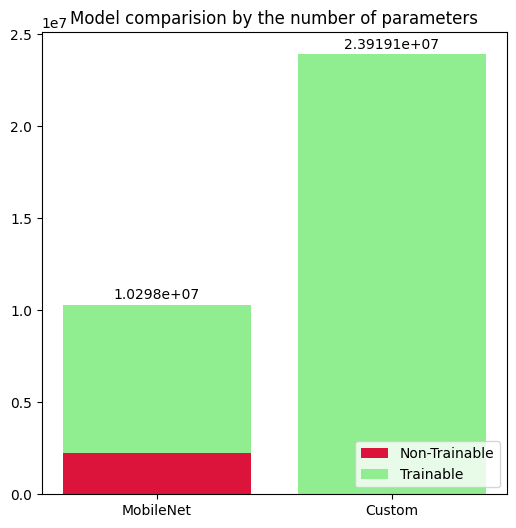

In [ ]:
inputy = tf.keras.layers.Input(shape=(SIZE, SIZE, 3))
y = MobileNet(inputy)
y = tf.keras.layers.Flatten()(y)
y = tf.keras.layers.Dense(128, activation='relu')(y)
y = tf.keras.layers.Dense(64, activation='relu')(y)
outputy = tf.keras.layers.Dense(CLASSES, activation='softmax')(y)
mn_fc = tf.keras.Model(inputs=inputy, outputs=outputy)
inputc = tf.keras.layers.Input(shape=(SIZE, SIZE, 3))
y = tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(224, 224, 3))(inputc)
y = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(y)
y = tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu')(y)
y = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(y)
y = tf.keras.layers.Flatten()(y)
y = tf.keras.layers.Dense(128, activation='relu')(y)
y = tf.keras.layers.Dense(64, activation='relu')(y)
outputc = tf.keras.layers.Dense(CLASSES, activation='softmax')(y)
model_fc = tf.keras.Model(inputs=inputc, outputs=outputc)

trainable_params_cfc = np.sum([np.prod(variable.shape) for variable in mn_fc.trainable_variables])
non_trainable_params_cfc = np.sum([np.prod(variable.shape) for variable in mn_fc.non_trainable_variables])
trainable_params_csq = np.sum([np.prod(variable.shape) for variable in mn_sq.trainable_variables])
non_trainable_params_csq = np.sum([np.prod(variable.shape) for variable in mn_sq.non_trainable_variables])
if trainable_params_cfc == trainable_params_csq and non_trainable_params_cfc == non_trainable_params_csq:
    print('MobileNet model OK')
trainable_params_customfc = np.sum([np.prod(variable.shape) for variable in model_fc.trainable_variables])
non_trainable_params_customfc = np.sum([np.prod(variable.shape) for variable in model_fc.non_trainable_variables])
trainable_params_customsq = np.sum([np.prod(variable.shape) for variable in model_sq.trainable_variables])
non_trainable_params_customsq = np.sum([np.prod(variable.shape) for variable in model_sq.non_trainable_variables])
if trainable_params_customfc == trainable_params_customsq and non_trainable_params_customfc == non_trainable_params_customsq:
    print('Convolutional model OK')

fig = plt.figure(figsize=(6, 6))
axis_x = ['MobileNet', 'Custom']
ax = plt.subplot(1, 1, 1)
ax.bar(axis_x, [non_trainable_params_cfc, non_trainable_params_customfc], color='crimson', label='Non-Trainable')
b = ax.bar(axis_x, [trainable_params_cfc, trainable_params_customfc], bottom=[non_trainable_params_cfc, non_trainable_params_customfc], color='lightgreen', label='Trainable')
ax.bar_label(b, padding=2)
ax.set_title('Model comparision by the number of parameters')
ax.legend(loc='lower right')
plt.show()


### 1.3. Datos y entrenamiento inicial

In [ ]:
train_dataset_ffd, valid_dataset_ffd, test_dataset_ffd = generadores_referencia(DATOS_BASE, {'rotation_range': 10, 'horizontal_flip': True})


Found 7624 images belonging to 53 classes.
Found 265 images belonging to 53 classes.
Found 265 images belonging to 53 classes.


#### Entrenamiento de MobileNetV2

Epoch 1/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 711ms/step - accuracy: 0.1055 - loss: 4.3404

120/120 ━━━━━━━━━━━━━━━━━━━━ 107s 784ms/step - accuracy: 0.1860 - loss: 3.4204 - val_accuracy: 0.3887 - val_loss: 2.3070
Epoch 2/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.4317 - loss: 2.0962

120/120 ━━━━━━━━━━━━━━━━━━━━ 88s 730ms/step - accuracy: 0.4512 - loss: 1.9854 - val_accuracy: 0.5585 - val_loss: 1.6627
Epoch 3/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 693ms/step - accuracy: 0.5779 - loss: 1.4734

120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 703ms/step - accuracy: 0.5921 - loss: 1.4087 - val_accuracy: 0.5623 - val_loss: 1.5441
Epoch 4/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 707ms/step - accuracy: 0.6809 - loss: 1.1081

120/120 ━━━━━━━━━━━━━━━━━━━━ 86s 717ms/step - accuracy: 0.6739 - loss: 1.1137 - val_accuracy: 0.5962 - val_loss: 1.3765
Epoch 5/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 669ms/step - accuracy: 0.7170 - loss: 0.9401

120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 680ms/step - accuracy: 0.7133 - loss: 0.9554 - val_accuracy: 0.6302 - val_loss: 1.4221
Epoch 6/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 725ms/step - accuracy: 0.7549 - loss: 0.7870 - val_accuracy: 0.5962 - val_loss: 1.4718
Epoch 7/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.7883 - loss: 0.6887

120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 729ms/step - accuracy: 0.7813 - loss: 0.6995 - val_accuracy: 0.6377 - val_loss: 1.3640
Epoch 8/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 719ms/step - accuracy: 0.8259 - loss: 0.5621

120/120 ━━━━━━━━━━━━━━━━━━━━ 88s 729ms/step - accuracy: 0.8089 - loss: 0.6179 - val_accuracy: 0.6604 - val_loss: 1.5462
Epoch 9/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 701ms/step - accuracy: 0.8315 - loss: 0.5264 - val_accuracy: 0.6340 - val_loss: 1.6873
Epoch 10/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 669ms/step - accuracy: 0.8630 - loss: 0.4380

120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 679ms/step - accuracy: 0.8611 - loss: 0.4453 - val_accuracy: 0.6792 - val_loss: 1.5290
Epoch 11/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 79s 661ms/step - accuracy: 0.8742 - loss: 0.4102 - val_accuracy: 0.6038 - val_loss: 1.7686
Epoch 12/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 78s 647ms/step - accuracy: 0.8810 - loss: 0.3693 - val_accuracy: 0.6453 - val_loss: 1.5455
Epoch 13/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 703ms/step - accuracy: 0.8961 - loss: 0.3204 - val_accuracy: 0.6679 - val_loss: 1.7267
Epoch 14/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 683ms/step - accuracy: 0.9098 - loss: 0.2792 - val_accuracy: 0.6642 - val_loss: 1.6781
Epoch 15/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 712ms/step - accuracy: 0.9094 - loss: 0.2700 - val_accuracy: 0.6075 - val_loss: 1.9120
Epoch 16/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 81s 676ms/step - accuracy: 0.9096 - loss: 0.2809 - val_accuracy: 0.6604 - val_loss: 1.5529
Epoch 17/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 697ms/step - accuracy: 0.9246 - loss: 0.228

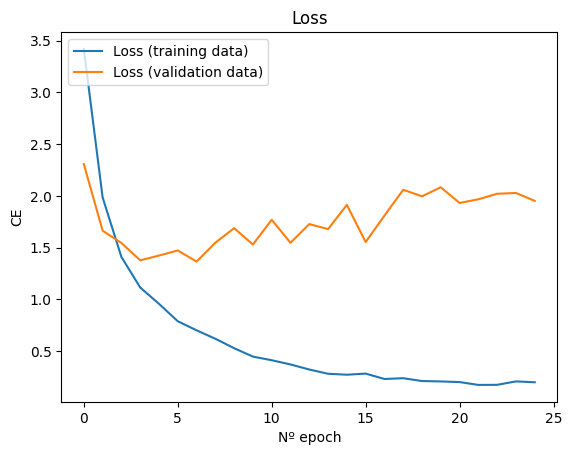

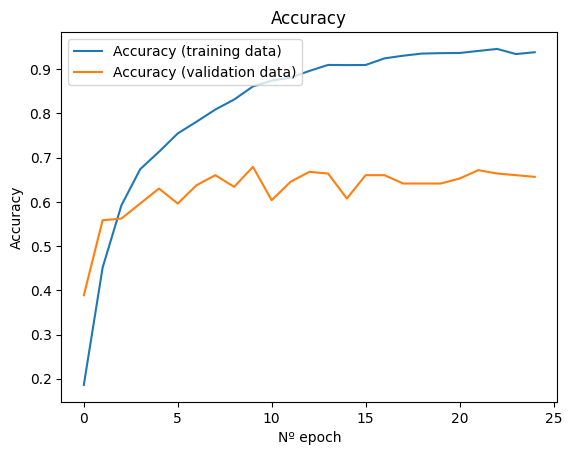

In [ ]:
name = 'MobileNet'
checkpoint, stop = callbacks_referencia(name, 0.01)

mn_sq.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

def plot_and_save(h, name):
    history = pd.DataFrame(h.history)
    history['epoch'] = list(range(0, len(history.index)))
    plt.figure()
    plt.plot(history['epoch'], history['loss'], label='Loss (training data)')
    plt.plot(history['epoch'], history['val_loss'], label='Loss (validation data)')
    plt.title('Loss')
    plt.ylabel('CE')
    plt.xlabel('Nº epoch')
    plt.legend(loc='upper left')
    plt.show()
    plt.figure()
    plt.plot(history['epoch'], history['accuracy'], label='Accuracy (training data)')
    plt.plot(history['epoch'], history['val_accuracy'], label='Accuracy (validation data)')
    plt.title('Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Nº epoch')
    plt.legend(loc='upper left')
    plt.show()

EPOCHS = 25
h = mn_sq.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS, callbacks=[checkpoint, stop])

plot_and_save(h, name)


#### Entrenamiento de Custom

Epoch 1/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 701ms/step - accuracy: 0.0361 - loss: 5.8606

120/120 ━━━━━━━━━━━━━━━━━━━━ 97s 734ms/step - accuracy: 0.0712 - loss: 4.2524 - val_accuracy: 0.1962 - val_loss: 2.9353
Epoch 2/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - accuracy: 0.2714 - loss: 2.7480

120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 685ms/step - accuracy: 0.3190 - loss: 2.5340 - val_accuracy: 0.4377 - val_loss: 1.8288
Epoch 3/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 673ms/step - accuracy: 0.4475 - loss: 2.0046

120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 685ms/step - accuracy: 0.4612 - loss: 1.9720 - val_accuracy: 0.5245 - val_loss: 1.5317
Epoch 4/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 676ms/step - accuracy: 0.5467 - loss: 1.7032

120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 688ms/step - accuracy: 0.5515 - loss: 1.6788 - val_accuracy: 0.5736 - val_loss: 1.3736
Epoch 5/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 675ms/step - accuracy: 0.6045 - loss: 1.4590

120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 687ms/step - accuracy: 0.6136 - loss: 1.4310 - val_accuracy: 0.6264 - val_loss: 1.2912
Epoch 6/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 655ms/step - accuracy: 0.6653 - loss: 1.2627

... (3 outputs left out)

120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 684ms/step - accuracy: 0.8324 - loss: 0.5958 - val_accuracy: 0.7208 - val_loss: 1.2187
Epoch 13/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.8376 - loss: 0.5862

120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 689ms/step - accuracy: 0.8425 - loss: 0.5734 - val_accuracy: 0.7321 - val_loss: 1.1940
Epoch 14/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 685ms/step - accuracy: 0.8667 - loss: 0.4862 - val_accuracy: 0.7170 - val_loss: 1.4087
Epoch 15/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 686ms/step - accuracy: 0.8767 - loss: 0.4384

120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 697ms/step - accuracy: 0.8745 - loss: 0.4543 - val_accuracy: 0.7358 - val_loss: 1.3410
Epoch 16/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 81s 674ms/step - accuracy: 0.8893 - loss: 0.4162 - val_accuracy: 0.7358 - val_loss: 1.1394
Epoch 17/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 680ms/step - accuracy: 0.9033 - loss: 0.3537 - val_accuracy: 0.7283 - val_loss: 1.2722
Epoch 18/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 666ms/step - accuracy: 0.9101 - loss: 0.3324

120/120 ━━━━━━━━━━━━━━━━━━━━ 82s 679ms/step - accuracy: 0.9075 - loss: 0.3359 - val_accuracy: 0.7585 - val_loss: 1.3571
Epoch 19/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 81s 675ms/step - accuracy: 0.9128 - loss: 0.3259 - val_accuracy: 0.7321 - val_loss: 1.3766
Epoch 20/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 697ms/step - accuracy: 0.9175 - loss: 0.2823 - val_accuracy: 0.7509 - val_loss: 1.3624
Epoch 21/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 79s 659ms/step - accuracy: 0.9230 - loss: 0.2855 - val_accuracy: 0.7321 - val_loss: 1.5832
Epoch 22/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 687ms/step - accuracy: 0.9336 - loss: 0.2605 - val_accuracy: 0.7396 - val_loss: 1.3787
Epoch 23/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 725ms/step - accuracy: 0.9418 - loss: 0.2148 - val_accuracy: 0.7547 - val_loss: 1.2938
Epoch 24/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 695ms/step - accuracy: 0.9338 - loss: 0.2460 - val_accuracy: 0.7472 - val_loss: 1.2423
Epoch 25/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 707ms/step - accuracy: 0.9479 - loss: 0.202

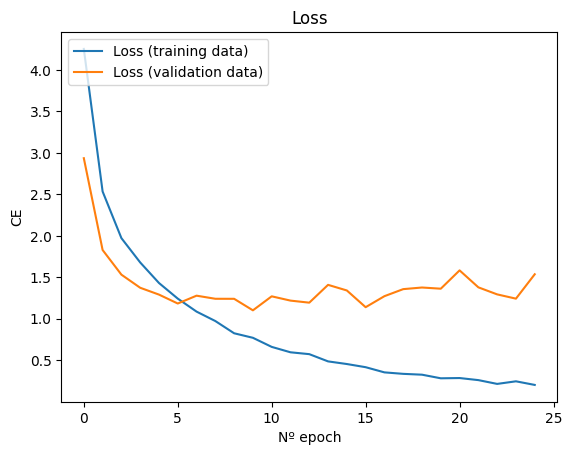

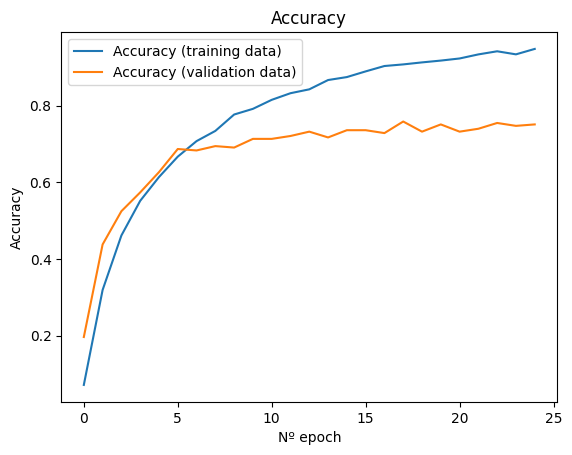

In [ ]:
model_sq.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

name = 'Custom'
checkpoint, stop = callbacks_referencia(name, 0.01)
h = model_sq.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS, callbacks=[checkpoint, stop])

plot_and_save(h, name)


This model is overfitted

### 1.4. Aumento de datos y ajuste fino

#### Segunda fase de MobileNetV2

Found 7624 images belonging to 53 classes.
Found 265 images belonging to 53 classes.
Found 265 images belonging to 53 classes.


Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 771ms/step - accuracy: 0.3979 - loss: 2.4009

120/120 ━━━━━━━━━━━━━━━━━━━━ 115s 830ms/step - accuracy: 0.4652 - loss: 1.9939 - val_accuracy: 0.2151 - val_loss: 14.3994
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 736ms/step - accuracy: 0.6116 - loss: 1.3586

120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 746ms/step - accuracy: 0.6133 - loss: 1.3540 - val_accuracy: 0.2491 - val_loss: 9.8243
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 93s 770ms/step - accuracy: 0.6724 - loss: 1.1364 - val_accuracy: 0.1623 - val_loss: 17.7664
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 747ms/step - accuracy: 0.7325 - loss: 0.8997

120/120 ━━━━━━━━━━━━━━━━━━━━ 91s 758ms/step - accuracy: 0.7284 - loss: 0.9017 - val_accuracy: 0.2642 - val_loss: 10.0081
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 91s 757ms/step - accuracy: 0.7492 - loss: 0.8377 - val_accuracy: 0.2075 - val_loss: 11.6570
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - accuracy: 0.7718 - loss: 0.7583

120/120 ━━━━━━━━━━━━━━━━━━━━ 92s 764ms/step - accuracy: 0.7730 - loss: 0.7548 - val_accuracy: 0.3962 - val_loss: 5.7649
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 91s 755ms/step - accuracy: 0.7876 - loss: 0.6926 - val_accuracy: 0.3208 - val_loss: 9.2585
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 728ms/step - accuracy: 0.8019 - loss: 0.6538 - val_accuracy: 0.1736 - val_loss: 8.5541
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 93s 773ms/step - accuracy: 0.8099 - loss: 0.6172 - val_accuracy: 0.3208 - val_loss: 7.9309
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 797ms/step - accuracy: 0.7946 - loss: 0.6992

... (10 outputs left out)

120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 750ms/step - accuracy: 0.9592 - loss: 0.1281 - val_accuracy: 0.8604 - val_loss: 1.1138
Epoch 59/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 709ms/step - accuracy: 0.9587 - loss: 0.1205 - val_accuracy: 0.8453 - val_loss: 1.0759
Epoch 60/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 89s 741ms/step - accuracy: 0.9667 - loss: 0.1051 - val_accuracy: 0.8491 - val_loss: 1.2127
Epoch 61/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 751ms/step - accuracy: 0.9656 - loss: 0.1039 - val_accuracy: 0.8302 - val_loss: 1.1745
Epoch 62/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 712ms/step - accuracy: 0.9702 - loss: 0.0981

120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 722ms/step - accuracy: 0.9677 - loss: 0.1054 - val_accuracy: 0.8906 - val_loss: 0.8350
Epoch 63/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 748ms/step - accuracy: 0.9588 - loss: 0.1292 - val_accuracy: 0.8566 - val_loss: 0.8288
Epoch 64/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 749ms/step - accuracy: 0.9641 - loss: 0.1168 - val_accuracy: 0.8642 - val_loss: 1.0036
Epoch 65/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 725ms/step - accuracy: 0.9584 - loss: 0.1332 - val_accuracy: 0.8377 - val_loss: 1.2174
Epoch 66/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 752ms/step - accuracy: 0.9567 - loss: 0.1524 - val_accuracy: 0.8264 - val_loss: 1.1982
Epoch 67/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 90s 748ms/step - accuracy: 0.9446 - loss: 0.2059 - val_accuracy: 0.8189 - val_loss: 1.2300
Epoch 68/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 88s 730ms/step - accuracy: 0.9567 - loss: 0.1504 - val_accuracy: 0.7472 - val_loss: 2.3322
Epoch 69/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 92s 763ms/step - accuracy: 0.9546 - loss

120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 707ms/step - accuracy: 0.9697 - loss: 0.1041 - val_accuracy: 0.8943 - val_loss: 0.8967
Epoch 81/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 725ms/step - accuracy: 0.9689 - loss: 0.1070 - val_accuracy: 0.8792 - val_loss: 0.8530
Epoch 82/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 87s 726ms/step - accuracy: 0.9708 - loss: 0.1016 - val_accuracy: 0.8642 - val_loss: 0.8159
Epoch 83/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 708ms/step - accuracy: 0.9723 - loss: 0.0925 - val_accuracy: 0.8906 - val_loss: 0.7240
Epoch 84/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 722ms/step - accuracy: 0.9749 - loss: 0.0793

120/120 ━━━━━━━━━━━━━━━━━━━━ 88s 734ms/step - accuracy: 0.9732 - loss: 0.0844 - val_accuracy: 0.9057 - val_loss: 0.5783
Epoch 85/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 88s 734ms/step - accuracy: 0.9732 - loss: 0.0833 - val_accuracy: 0.8717 - val_loss: 0.8451
Epoch 86/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 701ms/step - accuracy: 0.9709 - loss: 0.1032 - val_accuracy: 0.8604 - val_loss: 1.2612
Epoch 87/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 707ms/step - accuracy: 0.9673 - loss: 0.1020 - val_accuracy: 0.8717 - val_loss: 0.8729
Epoch 88/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 86s 718ms/step - accuracy: 0.9658 - loss: 0.1132 - val_accuracy: 0.8792 - val_loss: 0.8121
Epoch 89/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 84s 698ms/step - accuracy: 0.9739 - loss: 0.0859 - val_accuracy: 0.8302 - val_loss: 1.1332
Epoch 90/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 85s 708ms/step - accuracy: 0.9587 - loss: 0.1438 - val_accuracy: 0.8226 - val_loss: 1.3382
Epoch 91/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 86s 713ms/step - accuracy: 0.9744 - loss

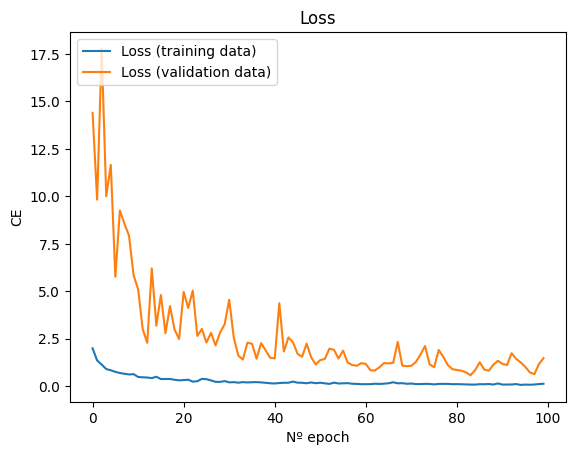

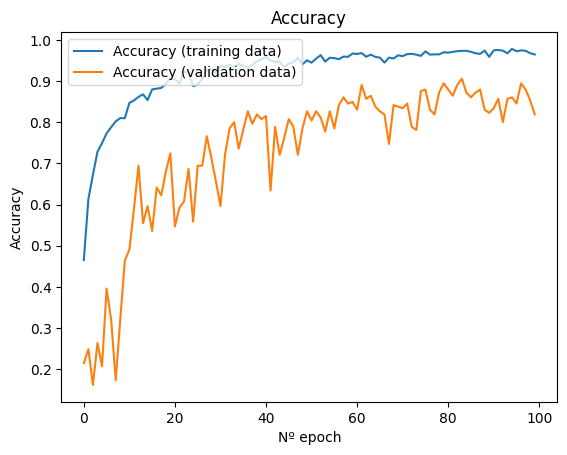

In [ ]:
train_dataset_ffd, valid_dataset_ffd, test_dataset_ffd = generadores_referencia(DATOS_BASE, {'rotation_range': 15, 'horizontal_flip': True, 'vertical_flip': True, 'zoom_range': 0.1, 'fill_mode': 'reflect'})

name = 'MobileNet_2'
checkpoint, stop = callbacks_referencia(name, 0.001)

mn_train_1 = tf.keras.models.load_model(path_models + '/MobileNet.h5')
weights = mn_train_1.get_weights()
base_net = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(SIZE, SIZE, 3))
for layer in base_net.layers[:130]:
    layer.trainable = False
mn_ft = tf.keras.Sequential([base_net, tf.keras.layers.Flatten(), tf.keras.layers.Dense(128, activation='relu'), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.Dense(CLASSES, activation='softmax')])

EPOCHS = 100
mn_ft.set_weights(weights)
mn_ft.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = mn_ft.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS, callbacks=[checkpoint, stop])
plot_and_save(h, name)


#### Segunda fase de Custom

In [ ]:
train_dataset_ffd, valid_dataset_ffd, test_dataset_ffd = generadores_referencia(DATOS_BASE, {'rotation_range': 15, 'horizontal_flip': True, 'vertical_flip': True, 'zoom_range': 0.1, 'fill_mode': 'reflect'})

name = 'Custom_2'
checkpoint, stop = callbacks_referencia(name, 0.001)

model_ft = tf.keras.models.load_model(path_models + '/Custom.h5')

model_ft.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_ft.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS, callbacks=[checkpoint, stop])
plot_and_save(h, name)


Found 7624 images belonging to 53 classes.
Found 265 images belonging to 53 classes.
Found 265 images belonging to 53 classes.


#### Tercera fase de Custom: aumento de datos más intenso

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 968ms/step - accuracy: 0.5969 - loss: 1.5287

120/120 ━━━━━━━━━━━━━━━━━━━━ 122s 992ms/step - accuracy: 0.6174 - loss: 1.4000 - val_accuracy: 0.8113 - val_loss: 0.8762
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.6592 - loss: 1.1964 - val_accuracy: 0.8038 - val_loss: 0.7386
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 118s 986ms/step - accuracy: 0.6836 - loss: 1.1157 - val_accuracy: 0.7849 - val_loss: 0.8404
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - accuracy: 0.6881 - loss: 1.0640

120/120 ━━━━━━━━━━━━━━━━━━━━ 117s 976ms/step - accuracy: 0.6915 - loss: 1.0728 - val_accuracy: 0.8189 - val_loss: 0.7133
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 118s 984ms/step - accuracy: 0.6995 - loss: 1.0441 - val_accuracy: 0.7925 - val_loss: 0.7441
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.7158 - loss: 0.9934 - val_accuracy: 0.8075 - val_loss: 0.7709
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 119s 994ms/step - accuracy: 0.7221 - loss: 0.9639 - val_accuracy: 0.8113 - val_loss: 0.7159
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.7260 - loss: 0.9477 - val_accuracy: 0.8000 - val_loss: 0.7467
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 996ms/step - accuracy: 0.7360 - loss: 0.9105 - val_accuracy: 0.7962 - val_loss: 0.7906
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 118s 983ms/step - accuracy: 0.7377 - loss: 0.9095 - val_accuracy: 0.7962 - val_loss: 0.7496
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 117s 976ms/step - accuracy: 0.7400 - loss: 0

120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 1000ms/step - accuracy: 0.7692 - loss: 0.7870 - val_accuracy: 0.8415 - val_loss: 0.6854
Epoch 18/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.7727 - loss: 0.7754 - val_accuracy: 0.8264 - val_loss: 0.7377
Epoch 19/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 119s 987ms/step - accuracy: 0.7726 - loss: 0.7459 - val_accuracy: 0.7887 - val_loss: 0.8087
Epoch 20/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 118s 981ms/step - accuracy: 0.7779 - loss: 0.7526 - val_accuracy: 0.8000 - val_loss: 0.7648
Epoch 21/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 115s 958ms/step - accuracy: 0.7817 - loss: 0.7190 - val_accuracy: 0.8226 - val_loss: 0.7350
Epoch 22/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 117s 978ms/step - accuracy: 0.7813 - loss: 0.7280 - val_accuracy: 0.8189 - val_loss: 0.7194
Epoch 23/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.7855 - loss: 0.7103 - val_accuracy: 0.8113 - val_loss: 0.7845
Epoch 24/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 119s 989ms/step - accuracy: 0.7892 - l

120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 999ms/step - accuracy: 0.8060 - loss: 0.6428 - val_accuracy: 0.8528 - val_loss: 0.7649
Epoch 34/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.8071 - loss: 0.6270 - val_accuracy: 0.8075 - val_loss: 0.7833
Epoch 35/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.8160 - loss: 0.6051 - val_accuracy: 0.8113 - val_loss: 0.7379
Epoch 36/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 119s 993ms/step - accuracy: 0.8158 - loss: 0.6113 - val_accuracy: 0.8377 - val_loss: 0.6778
Epoch 37/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 119s 989ms/step - accuracy: 0.8185 - loss: 0.5900 - val_accuracy: 0.8302 - val_loss: 0.6894
Epoch 38/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.8200 - loss: 0.5857 - val_accuracy: 0.8075 - val_loss: 0.9103
Epoch 39/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.8254 - loss: 0.5703 - val_accuracy: 0.8226 - val_loss: 0.8778
Epoch 40/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.8238 - loss: 0.577

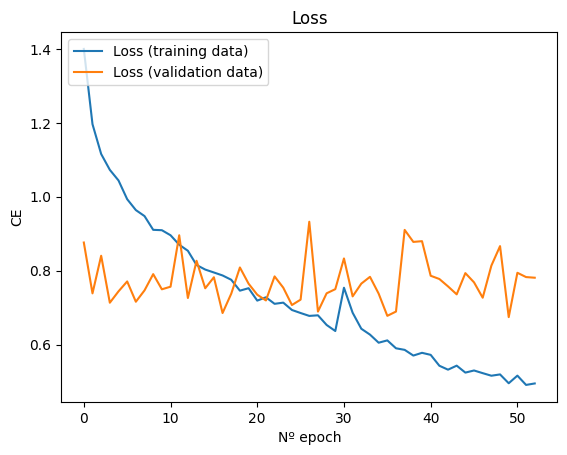

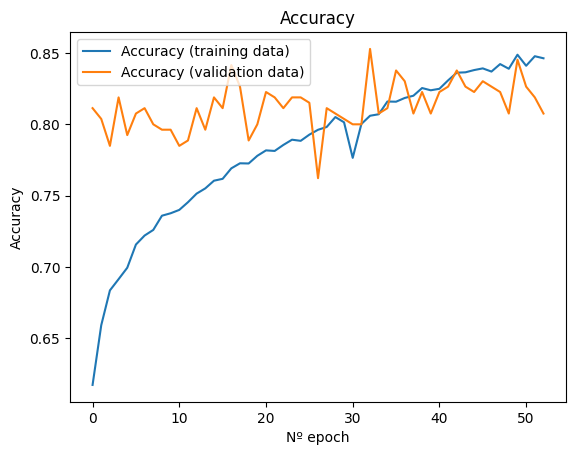

In [ ]:
train_dataset_ffd, valid_dataset_ffd, test_dataset_ffd = generadores_referencia(DATOS_BASE, {'rotation_range': 10, 'horizontal_flip': True, 'vertical_flip': True, 'zoom_range': 0.1, 'fill_mode': 'reflect', 'width_shift_range': 0.1, 'shear_range': 0.1, 'brightness_range': (0.95, 1.05)})

name = 'Custom_3'
checkpoint, stop = callbacks_referencia(name, 0.001)

model_ft2 = tf.keras.models.load_model(path_models + '/Custom_2.h5')
model_ft2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_ft2.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS, callbacks=[checkpoint, stop])
plot_and_save(h, name)


### 1.5. Evaluación de referencia en el test original

5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 760ms/step - accuracy: 0.8642 - loss: 0.8965
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 219ms/step - accuracy: 0.7472 - loss: 1.3452


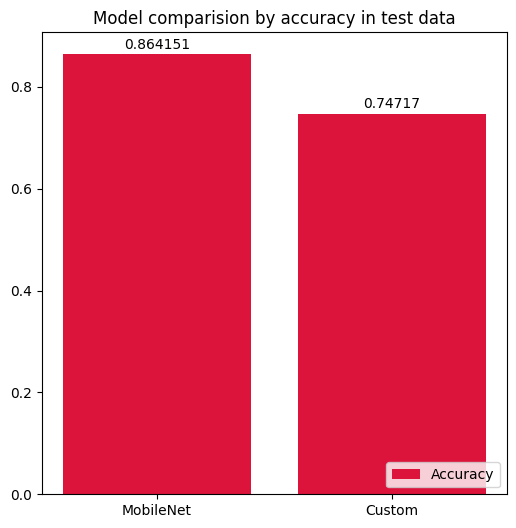

In [ ]:
custom3 = tf.keras.models.load_model(path_models + '/Custom_3.h5')
conv2 = tf.keras.models.load_model(path_models + '/MobileNet_2.h5')

_, conv_acc2 = conv2.evaluate(test_dataset_ffd)
_, custom_acc3 = custom3.evaluate(test_dataset_ffd)

fig = plt.figure(figsize=(6, 6))
axis_x = ['MobileNet', 'Custom']
b = plt.bar(axis_x, [conv_acc2, custom_acc3], color='crimson', label='Accuracy')
plt.bar_label(b, padding=2)
plt.title('Model comparision by accuracy in test data')
plt.legend(loc='lower right')
plt.show()


#### Informe por clase

In [ ]:
def show_report(model, dataframe):
    labels = dataframe.class_indices
    true_labels = dataframe.labels
    pred_labels = model.predict(dataframe, verbose=0).argmax(axis=1)
    keys_array = np.array(list(labels.keys()))
    true_text = [keys_array[value] for value in true_labels]
    pred_text = [keys_array[value] for value in pred_labels]
    print(classification_report(true_text, pred_text))

def show_matrix(model, dataframe):
    labels = dataframe.class_indices
    true_labels = dataframe.labels
    pred_labels = model.predict(dataframe, verbose=0).argmax(axis=1)
    keys_array = np.array(list(labels.keys()))
    true_text = [keys_array[value] for value in true_labels]
    pred_text = [keys_array[value] for value in pred_labels]
    cf = confusion_matrix(true_text, pred_text, labels=keys_array)
    fig, ax = plt.subplots(figsize=(12, 12))
    sns.heatmap(cf, annot=True, fmt='', square=True, cbar=False, cmap=plt.cm.Blues, xticklabels=keys_array, yticklabels=keys_array, ax=ax)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')
    ax.set_title('Confusion Matrix')
    plt.show()

show_report(conv2, test_dataset_ffd)


                   precision    recall  f1-score   support

     ace of clubs       0.71      1.00      0.83         5
  ace of diamonds       0.83      1.00      0.91         5
    ace of hearts       1.00      1.00      1.00         5
    ace of spades       1.00      1.00      1.00         5
   eight of clubs       1.00      0.80      0.89         5
eight of diamonds       0.83      1.00      0.91         5
  eight of hearts       1.00      1.00      1.00         5
  eight of spades       0.75      0.60      0.67         5
    five of clubs       0.80      0.80      0.80         5
 five of diamonds       1.00      0.80      0.89         5
   five of hearts       1.00      0.80      0.89         5
   five of spades       0.56      1.00      0.71         5
    four of clubs       1.00      1.00      1.00         5
 four of diamonds       1.00      1.00      1.00         5
   four of hearts       1.00      1.00      1.00         5
   four of spades       1.00      0.80      0.89       

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#### Matriz de confusión

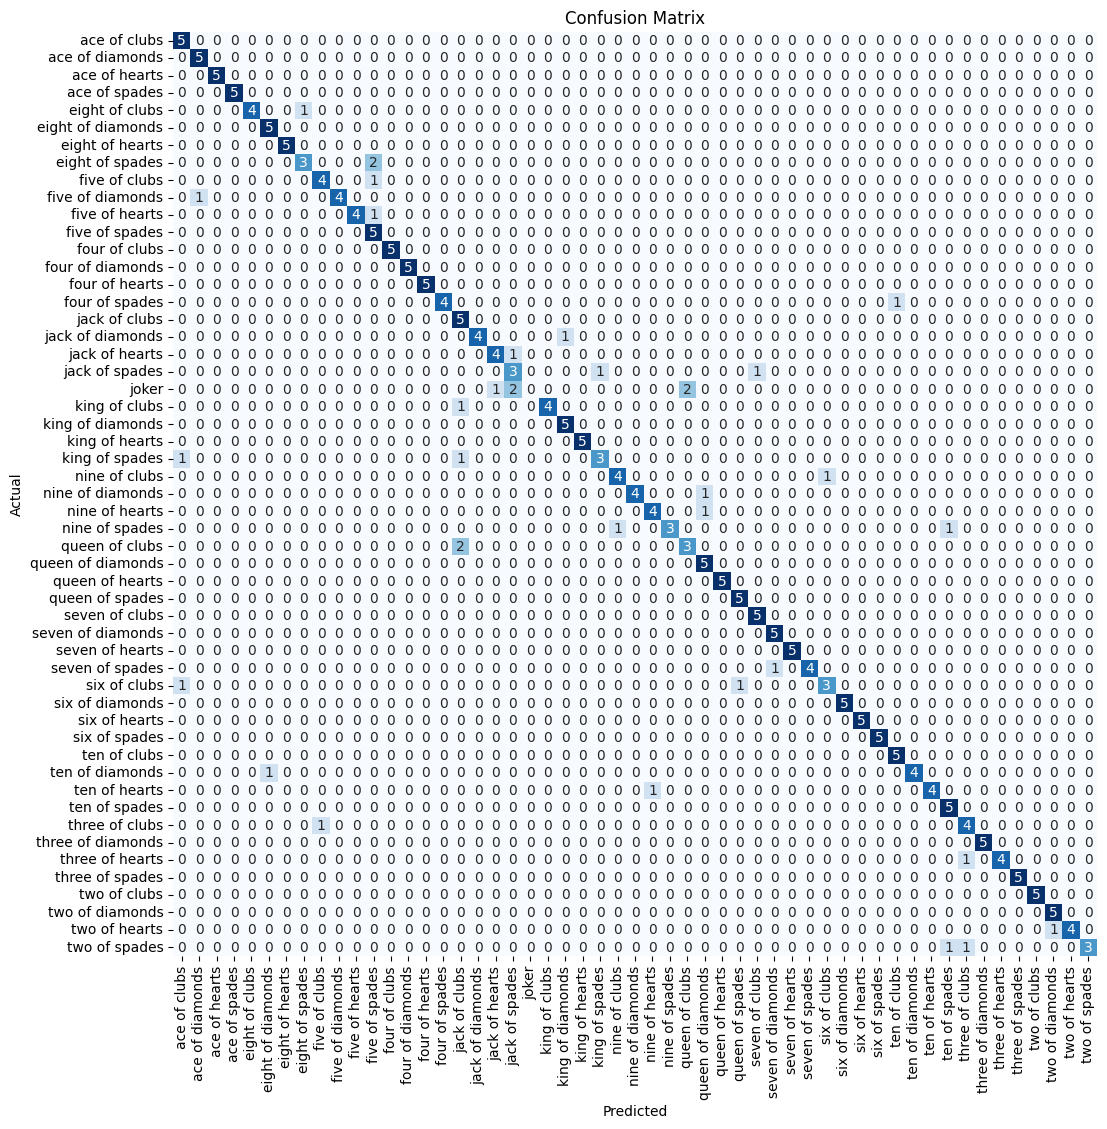

In [ ]:
show_matrix(conv2, test_dataset_ffd)


## 2. Primera hipótesis: más datos y nuevas arquitecturas

**Pregunta:** ¿añadir ejemplos y probar otros extractores preentrenados mejora las clases difíciles?

Se incorporan 15 imágenes de joker creadas sinteticamente(12 train y 3 valid) y un ZIP externo publico con 27.300 imágenes de entrenamiento y 11.700 de validación. Esto produce 34.936 train / 11.968 valid / 265 test. El test permanece como referencia original; lo que cambia aquí es la distribución de entrenamiento y validación.

Los jokers han sido creados por mi utilizando canvas cojiendo plantillas de jokers normales y modificandolas, añadiendo imagenes...

El link del resto de las imagenes añadidad es este: https://helix.imperial.ac.uk/records/2q13m-kb120

Fuente de las imágenes externas: [Card arithmetic dataset, Imperial College London](https://helix.imperial.ac.uk/records/2q13m-kb120), archivo `images.zip`. Su MD5 coincidió con el ZIP local. La variante ampliada se crea sin modificar la carpeta de originales.

In [ ]:
folder_path = str(PROYECTO / 'Nuevos_Jokers')
image_extensions = ('.png', '.jpg', '.jpeg', '.webp', '.bmp')
image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(image_extensions)]
print(f'Se encontraron {len(image_files)} imágenes en la carpeta.')
loaded_images = []
for img_name in image_files:
    img_path = os.path.join(folder_path, img_name)
    img = cv2.imread(img_path)
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        loaded_images.append((img_name, img_rgb))
print(f'Se cargaron con éxito {len(loaded_images)} imágenes.')


Se encontraron 15 imágenes en la carpeta.
Se cargaron con éxito 15 imágenes.


### FASE 1.1: Descompresión y Extracción de Imágenes Adicionales

In [ ]:
liberar_modelos_y_datasets()
preparar_ampliados()
with zipfile.ZipFile(PROYECTO / 'images (1).zip') as archivo:
    archivo.extractall(DATOS_AMPLIADOS)
print('Dataset externo extraído en la variante ampliada:', DATOS_AMPLIADOS)


Descomprimiendo con sobreescritura forzada... Por favor, espera.
¡Extracción completada con éxito!

Contenido de Datasets tras la extracción:
['valid', 'images', 'test', 'train']


### FASE 1.2: Unificación del Dataset (Imagenes sinteticas + ZIP Adicional)

Este script consolida la ampliación realizando las siguientes tareas:
1. Distribuye de forma balanceada las nuevas imágenes de **Jokers** (80% a entrenamiento y 20% a validación).
2. Mapea la nomenclatura abreviada de las nuevas imágenes del ZIP adicional a los nombres largos de clase del modelo (ej. `7c` $\rightarrow$ `seven of clubs`).
3. Copia automáticamente las nuevas imágenes clasificándolas de forma limpia en los directorios de `train` y `valid` correspondientes.

In [ ]:
jokers_src_dir = str(PROYECTO / 'Nuevos_Jokers')
zip_extracted_dir = str(DATOS_AMPLIADOS / 'images')
target_train_dir = str(DATOS_AMPLIADOS / 'train')
target_valid_dir = str(DATOS_AMPLIADOS / 'valid')
print('=== INICIANDO PROCESAMIENTO UNIFICADO ===')
print('\n--- Paso A: Copiando nuevos Jokers a la estructura existente ---')
os.makedirs(os.path.join(target_train_dir, 'joker'), exist_ok=True)
os.makedirs(os.path.join(target_valid_dir, 'joker'), exist_ok=True)
if os.path.exists(jokers_src_dir):
    joker_files = [f for f in os.listdir(jokers_src_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp', '.bmp'))]
    for idx, f in enumerate(joker_files):
        src_path = os.path.join(jokers_src_dir, f)
        if idx % 5 == 0:
            dst_path = os.path.join(target_valid_dir, 'joker', f'nuevo_joker_{idx}.png')
        else:
            dst_path = os.path.join(target_train_dir, 'joker', f'nuevo_joker_{idx}.png')
        shutil.copy(src_path, dst_path)
    print(f"¡Completado! Copiados {len(joker_files)} jokers a las carpetas 'joker'.")
else:
    print(f'Advertencia: No se encontró la ruta de origen de los Jokers: {jokers_src_dir}')
print('\n--- Paso B: Procesando el dataset del ZIP adicional ---')
suits_map = {'s': 'spades', 'h': 'hearts', 'd': 'diamonds', 'c': 'clubs'}
values_map = {'2': 'two', '3': 'three', '4': 'four', '5': 'five', '6': 'six', '7': 'seven', '8': 'eight', '9': 'nine', '10': 'ten', 'j': 'jack', 'q': 'queen', 'k': 'king', 'a': 'ace'}

def get_full_label_name(abbrev):
    abbrev = str(abbrev).strip().lower()
    if abbrev == 'joker':
        return 'joker'
    val_part = abbrev[:-1]
    suit_part = abbrev[-1]
    val_full = values_map.get(val_part, val_part)
    suit_full = suits_map.get(suit_part, suit_part)
    return f'{val_full} of {suit_full}'
csv_files = []
if os.path.exists(zip_extracted_dir):
    for root, dirs, files in os.walk(zip_extracted_dir):
        if 'playing_card_labels.csv' in files:
            csv_files.append(os.path.join(root, 'playing_card_labels.csv'))
else:
    print(f'Advertencia: No existe el directorio de extracción {zip_extracted_dir}')
print(f'Archivos CSV encontrados para procesar: {csv_files}')
for csv_path in csv_files:
    print(f'\nProcesando archivo: {csv_path}')
    df_labels = pd.read_csv(csv_path)
    if 'img' in df_labels.columns and 'label' in df_labels.columns:
        count_train = 0
        count_valid = 0
        base_images_dir = os.path.dirname(csv_path)
        is_test_set = 'images_test' in csv_path
        for _, row in df_labels.iterrows():
            img_id = str(row['img'])
            img_filename = img_id if img_id.lower().endswith('.jpg') else img_id + '.jpg'
            label_abbrev = row['label']
            full_label = get_full_label_name(label_abbrev)
            src_img_path = os.path.join(base_images_dir, img_filename)
            if os.path.exists(src_img_path):
                if is_test_set:
                    dest_folder = os.path.join(target_valid_dir, full_label)
                    os.makedirs(dest_folder, exist_ok=True)
                    shutil.copy(src_img_path, os.path.join(dest_folder, f'zip_test_{img_filename}'))
                    count_valid += 1
                else:
                    dest_folder = os.path.join(target_train_dir, full_label)
                    os.makedirs(dest_folder, exist_ok=True)
                    shutil.copy(src_img_path, os.path.join(dest_folder, f'zip_train_{img_filename}'))
                    count_train += 1
        print(f'Completado para este archivo. Copiadas {count_train} imágenes a train y {count_valid} a valid/test.')
    else:
        print("Las columnas del CSV no coinciden con las esperadas ('img', 'label').")
print('\n=== PROCESO UNIFICADO FINALIZADO CON ÉXITO ===')


=== INICIANDO PROCESAMIENTO UNIFICADO ===

--- Paso A: Copiando nuevos Jokers a la estructura existente ---
¡Completado! Copiados 15 jokers a las carpetas 'joker'.

--- Paso B: Procesando el dataset del ZIP adicional ---
Archivos CSV encontrados para procesar: ['/content/sample_data/Datasets/images/images_train/playing_card_labels.csv', '/content/sample_data/Datasets/images/images_test/playing_card_labels.csv']

Procesando archivo: /content/sample_data/Datasets/images/images_train/playing_card_labels.csv
Completado para este archivo. Copiadas 27300 imágenes a train y 0 a valid/test.

Procesando archivo: /content/sample_data/Datasets/images/images_test/playing_card_labels.csv
Completado para este archivo. Copiadas 0 imágenes a train y 11700 a valid/test.

=== PROCESO UNIFICADO FINALIZADO CON ÉXITO ===


### Recuento, clases y lectura de imágenes

Se comprueban las 53 clases y el número de archivos para ver si todo se ha subido correctamente.

In [ ]:
train_dir = str(DATOS_AMPLIADOS / 'train')
valid_dir = str(DATOS_AMPLIADOS / 'valid')
test_dir = str(DATOS_AMPLIADOS / 'test')

def audit_dataset(dataset_path, name):
    print(f'\n=== AUDITANDO CONJUNTO: {name.upper()} ===')
    if not os.path.exists(dataset_path):
        print(f'La ruta {dataset_path} no existe.')
        return ({}, 0)
    classes = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
    print(f'Número de clases detectadas: {len(classes)}')
    class_counts = {}
    total_images = 0
    corrupt_files = []
    for c in classes:
        class_path = os.path.join(dataset_path, c)
        files = [f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))]
        class_counts[c] = len(files)
        total_images += len(files)
        for f in files:
            file_path = os.path.join(class_path, f)
            try:
                with Image.open(file_path) as img:
                    img.verify()
            except Exception:
                corrupt_files.append(file_path)
    print(f'Total de imágenes legibles: {total_images}')
    if corrupt_files:
        print(f'¡ALERTA! Se encontraron {len(corrupt_files)} imágenes corruptas:')
        for cf in corrupt_files[:5]:
            print(f' - {cf}')
    else:
        print('No se detectaron imágenes corruptas.')
    return (class_counts, total_images)
train_counts, total_train = audit_dataset(train_dir, 'train')
valid_counts, total_valid = audit_dataset(valid_dir, 'valid')
test_counts, total_test = audit_dataset(test_dir, 'test')



=== AUDITANDO CONJUNTO: TRAIN ===
Número de clases detectadas: 53
Total de imágenes legibles: 34936
No se detectaron imágenes corruptas.

=== AUDITANDO CONJUNTO: VALID ===
Número de clases detectadas: 53
Total de imágenes legibles: 11968
No se detectaron imágenes corruptas.

=== AUDITANDO CONJUNTO: TEST ===
Número de clases detectadas: 53
Total de imágenes legibles: 265
No se detectaron imágenes corruptas.


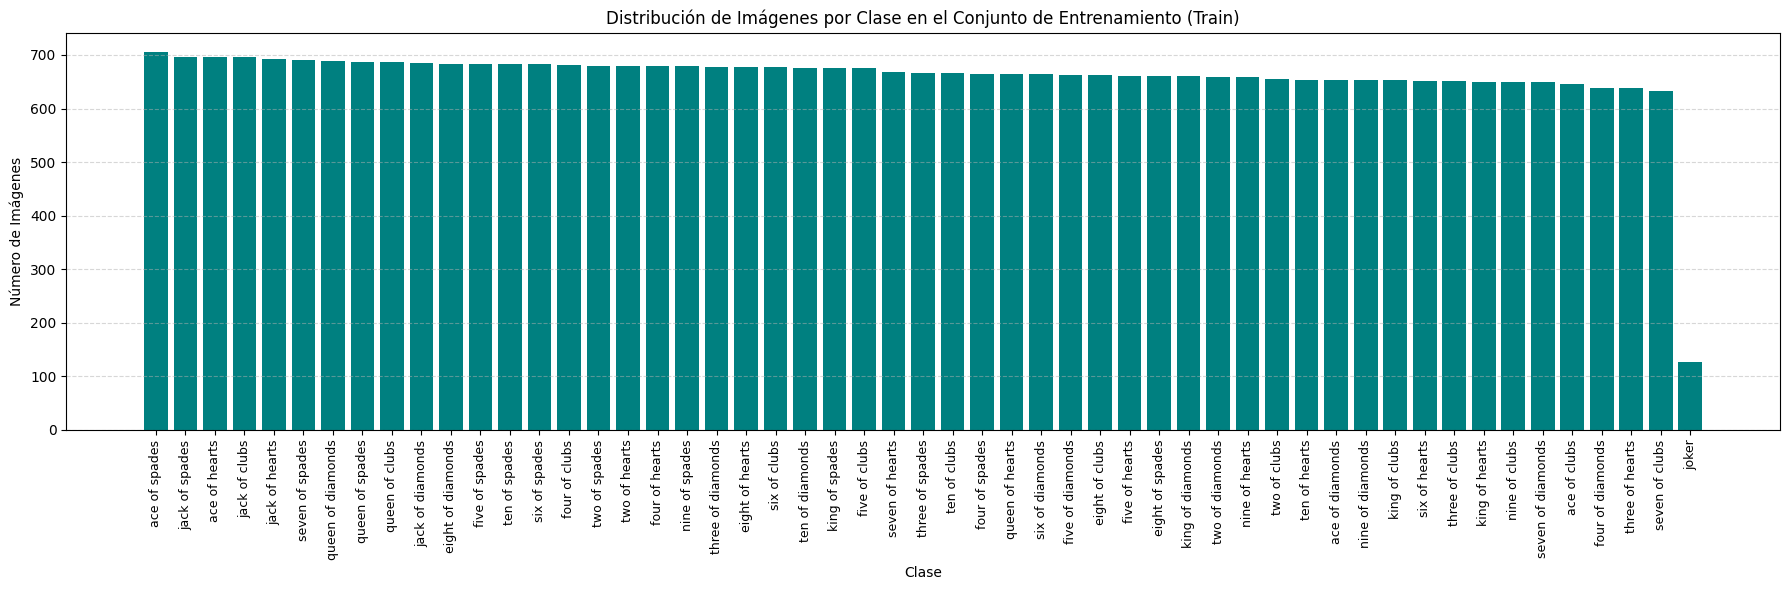


Estadísticas de distribución en Entrenamiento:
Clase con MÁS imágenes: ace of spades (706)
Clase con MENOS imágenes: joker (127)


In [ ]:
if train_counts:
    df_train = pd.DataFrame(list(train_counts.items()), columns=['Clase', 'Cantidad']).sort_values(by='Cantidad', ascending=False)
    plt.figure(figsize=(18, 6))
    plt.bar(df_train['Clase'], df_train['Cantidad'], color='teal')
    plt.xticks(rotation=90, fontsize=9)
    plt.title('Distribución de Imágenes por Clase en el Conjunto de Entrenamiento (Train)')
    plt.ylabel('Número de Imágenes')
    plt.xlabel('Clase')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    print('\nEstadísticas de distribución en Entrenamiento:')
    print(f"Clase con MÁS imágenes: {df_train.iloc[0]['Clase']} ({df_train.iloc[0]['Cantidad']})")
    print(f"Clase con MENOS imágenes: {df_train.iloc[-1]['Clase']} ({df_train.iloc[-1]['Cantidad']})")


### Entrenamiento con el dataset ampliado

Se preparan MobileNetV2, EfficientNetB0 y ResNet50V2; el modelo Custom no se reentrena en este bloque.

In [ ]:
SIZE = 224
CLASSES = 53
train_generator_opt = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255, rotation_range=15, horizontal_flip=True, vertical_flip=True, zoom_range=0.1, fill_mode='reflect')
valid_generator_opt = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
test_generator_opt = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
print('Cargando los nuevos conjuntos de datos...')
train_dataset_ffd = train_generator_opt.flow_from_directory(train_dir, target_size=(SIZE, SIZE), class_mode='categorical', batch_size=64, shuffle=True)
valid_dataset_ffd = valid_generator_opt.flow_from_directory(valid_dir, target_size=(SIZE, SIZE), class_mode='categorical', batch_size=64, shuffle=False)
test_dataset_ffd = test_generator_opt.flow_from_directory(test_dir, target_size=(SIZE, SIZE), class_mode='categorical', batch_size=64, shuffle=False)

SIZE = 224
CLASSES = 53
base_mobilenet = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(SIZE, SIZE, 3))
base_mobilenet.trainable = False
x1 = base_mobilenet.output
x1 = GlobalAveragePooling2D()(x1)
x1 = Dense(128, activation='relu')(x1)
x1 = Dropout(0.3)(x1)
outputs_mobilenet = Dense(CLASSES, activation='softmax')(x1)
model_mobilenet = Model(inputs=base_mobilenet.input, outputs=outputs_mobilenet, name='MobileNetV2_Classifier')
base_efficientnet = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(SIZE, SIZE, 3))
base_efficientnet.trainable = False
x2 = base_efficientnet.output
x2 = GlobalAveragePooling2D()(x2)
x2 = Dense(128, activation='relu')(x2)
x2 = Dropout(0.3)(x2)
outputs_efficientnet = Dense(CLASSES, activation='softmax')(x2)
model_efficientnet = Model(inputs=base_efficientnet.input, outputs=outputs_efficientnet, name='EfficientNetB0_Classifier')
base_resnet = tf.keras.applications.ResNet50V2(include_top=False, weights='imagenet', input_shape=(SIZE, SIZE, 3))
base_resnet.trainable = False
x3 = base_resnet.output
x3 = GlobalAveragePooling2D()(x3)
x3 = Dense(128, activation='relu')(x3)
x3 = Dropout(0.3)(x3)
outputs_resnet = Dense(CLASSES, activation='softmax')(x3)
model_resnet = Model(inputs=base_resnet.input, outputs=outputs_resnet, name='ResNet50V2_Classifier')
print('Arquitecturas preparadas; cada una se compila al iniciar su entrenamiento.')

path_models = str(RESULTADOS / '02_Dataset_Ampliado')
Path(path_models).mkdir(parents=True, exist_ok=True)

def get_callbacks(model_name):
    checkpoint_path = os.path.join(path_models, f'{model_name}_best.keras')
    checkpoint = tf.keras.callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1)
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=1e-06, verbose=1)
    return [checkpoint, early_stop, reduce_lr]


Cargando los nuevos conjuntos de datos...
Found 34936 images belonging to 53 classes.
Found 11968 images belonging to 53 classes.
Found 265 images belonging to 53 classes.


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Modelos definidos y compilados exitosamente con variables locales aseguradas.


## FASE 2.1: Definición y Compilación de las Tres Arquitecturas

Definimos los tres modelos pre-entrenados con pesos de ImageNet de forma simultánea. Inicialmente congelamos las capas base para realizar un entrenamiento del clasificador superior con una tasa de aprendizaje estándar. Añadimos regularización mediante Dropout.

## FASE 2.2: Configuración de Callbacks Especializados para Cada Modelo

Para asegurar un entrenamiento robusto y evitar perder los mejores pesos, utilizaremos callbacks independientes de early stopping y de guardado para cada una de las arquitecturas.

## FASE 2.3: Entrenamiento Comparativo (Feature Extraction)

Entrenamos los modelos de forma secuencial por un máximo de 15 épocas.

In [ ]:
EPOCHS_FE = 15
model_mobilenet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history_mobilenet = model_mobilenet.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS_FE, callbacks=get_callbacks('MobileNetV2'))


=== Iniciando Entrenamiento de MobileNetV2 ===
Epoch 1/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 747ms/step - accuracy: 0.4688 - loss: 1.9099
Epoch 1: val_accuracy improved from None to 0.94343, saving model to /content/sample_data/Datasets/Models/MobileNetV2_best.keras

Epoch 1: finished saving model to /content/sample_data/Datasets/Models/MobileNetV2_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 442s 787ms/step - accuracy: 0.6344 - loss: 1.2629 - val_accuracy: 0.9434 - val_loss: 0.2525 - learning_rate: 0.0010
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 767ms/step - accuracy: 0.7989 - loss: 0.6939
Epoch 2: val_accuracy improved from 0.94343 to 0.95805, saving model to /content/sample_data/Datasets/Models/MobileNetV2_best.keras

Epoch 2: finished saving model to /content/sample_data/Datasets/Models/MobileNetV2_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 435s 797ms/step - accuracy: 0.8086 - loss: 0.6678 - val_accuracy: 0.9581 - val_loss: 0.1658 - learning_rate: 0.0010
Epoch 3/15
546/546 ━━━━━━━━━━━━━━━━━

In [ ]:
model_efficientnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history_efficientnet = model_efficientnet.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS_FE, callbacks=get_callbacks('EfficientNetB0'))


=== Re-compilando EfficientNetB0 con un optimizador limpio ===
=== Iniciando Entrenamiento de EfficientNetB0 ===
Epoch 1/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 722ms/step - accuracy: 0.0175 - loss: 3.9647
Epoch 1: val_accuracy improved from None to 0.01922, saving model to /content/sample_data/Datasets/Models/EfficientNetB0_best.keras

Epoch 1: finished saving model to /content/sample_data/Datasets/Models/EfficientNetB0_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 441s 771ms/step - accuracy: 0.0177 - loss: 3.9641 - val_accuracy: 0.0192 - val_loss: 3.9609 - learning_rate: 0.0010
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 725ms/step - accuracy: 0.0203 - loss: 3.9623
Epoch 2: val_accuracy did not improve from 0.01922
546/546 ━━━━━━━━━━━━━━━━━━━━ 411s 753ms/step - accuracy: 0.0193 - loss: 3.9625 - val_accuracy: 0.0192 - val_loss: 3.9592 - learning_rate: 0.0010
Epoch 3/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 768ms/step - accuracy: 0.0199 - loss: 3.9619
Epoch 3: val_accuracy did not improve from 0.01922
5

In [ ]:
model_resnet.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
history_resnet = model_resnet.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=EPOCHS_FE, callbacks=get_callbacks('ResNet50V2'))


=== Re-compilando ResNet50V2 con un optimizador limpio para evitar colisiones ===
=== Iniciando Entrenamiento de ResNet50V2 ===
Epoch 1/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 745ms/step - accuracy: 0.4646 - loss: 1.9143
Epoch 1: val_accuracy improved from None to 0.94159, saving model to /content/sample_data/Datasets/Models/ResNet50V2_best.keras

Epoch 1: finished saving model to /content/sample_data/Datasets/Models/ResNet50V2_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 448s 786ms/step - accuracy: 0.6260 - loss: 1.2835 - val_accuracy: 0.9416 - val_loss: 0.2695 - learning_rate: 0.0010
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 718ms/step - accuracy: 0.7906 - loss: 0.7131
Epoch 2: val_accuracy improved from 0.94159 to 0.96006, saving model to /content/sample_data/Datasets/Models/ResNet50V2_best.keras

Epoch 2: finished saving model to /content/sample_data/Datasets/Models/ResNet50V2_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 408s 747ms/step - accuracy: 0.8035 - loss: 0.6788 - val_accuracy: 0.9601 - 

### Evaluación de las Tres Arquitecturas en el Conjunto de Test

### 2.1. Primer resultado negativo y diagnóstico

Aunque la validación ampliada ronda el 98–99 % para algunos modelos, el test original obtiene 51,70 % en MobileNet y 56,98 % en ResNet. EfficientNet queda en 1,89 %, cercano al azar entre 53 clases.

La discrepancia es compatible con un cambio de distribución y una validación poco representativa del test original; no demuestra por sí sola duplicación de imágenes. Además, EfficientNet recibía datos divididos entre 255 pese a incorporar su propio escalado: esa ejecución no permite concluir que la arquitectura sea mala. En las fases posteriores se proporciona RGB 0..255 y se corrige el preprocesamiento.

In [ ]:
path_models = str(RESULTADOS / '02_Dataset_Ampliado')
modelos_a_evaluar = {'MobileNetV2': os.path.join(path_models, 'MobileNetV2_best.keras'), 'EfficientNetB0': os.path.join(path_models, 'EfficientNetB0_best.keras'), 'ResNet50V2': os.path.join(path_models, 'ResNet50V2_best.keras')}
print('=== INICIANDO EVALUACIÓN DE MODELOS EN EL TEST SET ===\n')
for nombre_modelo, ruta_modelo in modelos_a_evaluar.items():
    print(f'--- Evaluando {nombre_modelo} ---')
    if os.path.exists(ruta_modelo):
        try:
            modelo = tf.keras.models.load_model(ruta_modelo)
            eval_results = modelo.evaluate(test_dataset_ffd, verbose=1)
            loss = eval_results[0]
            accuracy = eval_results[1]
            print(f'\n[RESULTADO] {nombre_modelo} -> Loss: {loss:.4f} | Accuracy: {accuracy * 100:.2f}%\n')
        except Exception as e:
            print(f'Ocurrió un error al cargar o evaluar {nombre_modelo}: {e}\n')
    else:
        print(f'El archivo de pesos no fue encontrado en: {ruta_modelo}')
        print('Asegúrate de haber completado el entrenamiento del modelo correspondiente para generar el archivo.\n')


=== INICIANDO EVALUACIÓN DE MODELOS EN EL TEST SET ===

--- Evaluando MobileNetV2 ---
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5170 - loss: 1.5974

[RESULTADO] MobileNetV2 -> Loss: 1.5974 | Accuracy: 51.70%

--- Evaluando EfficientNetB0 ---
5/5 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.0189 - loss: 3.9747

[RESULTADO] EfficientNetB0 -> Loss: 3.9747 | Accuracy: 1.89%

--- Evaluando ResNet50V2 ---
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5698 - loss: 1.4684

[RESULTADO] ResNet50V2 -> Loss: 1.4684 | Accuracy: 56.98%



### 2.2. Recuperar una validación comparable

Se retiran de validación las 11.700 imágenes identificadas por el prefijo `zip_test_`, conservando las 265 originales y 3 nuevos jokers. El entrenamiento ampliado se mantiene todavía.

In [ ]:
print('=== INICIANDO SANEAMIENTO DE LA CARPETA DE VALIDACIÓN ===')
valid_dir = str(DATOS_AMPLIADOS / 'valid')
cleaned_count = 0
kept_original = 0
kept_jokers = 0
for clase in os.listdir(valid_dir):
    clase_path = os.path.join(valid_dir, clase)
    if os.path.isdir(clase_path):
        for archivo in os.listdir(clase_path):
            file_path = os.path.join(clase_path, archivo)
            if archivo.startswith('zip_test_'):
                os.remove(file_path)
                cleaned_count += 1
            elif 'nuevo_joker_' in archivo:
                kept_jokers += 1
            else:
                kept_original += 1
print(f'✓ Eliminadas {cleaned_count} imágenes duplicadas/filtradas del ZIP adicional.')
print(f'✓ Conservadas {kept_original} imágenes de validación originales.')
print(f'✓ Conservados {kept_jokers} nuevos Jokers de validación.')
print('\n--- Re-inicializando los generadores de datos con el set saneado ---')
train_generator_opt = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255, rotation_range=15, horizontal_flip=True, vertical_flip=True, zoom_range=0.1, fill_mode='reflect')
valid_generator_opt = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1.0 / 255)
train_dataset_ffd = train_generator_opt.flow_from_directory(str(DATOS_AMPLIADOS / 'train'), target_size=(224, 224), class_mode='categorical', batch_size=64, shuffle=True)
valid_dataset_ffd = valid_generator_opt.flow_from_directory(str(DATOS_AMPLIADOS / 'valid'), target_size=(224, 224), class_mode='categorical', batch_size=64, shuffle=False)
print(f'Total de imágenes en entrenamiento actual: {train_dataset_ffd.n}')
print(f'Total de imágenes en validación saneada: {valid_dataset_ffd.n}')


=== INICIANDO SANEAMIENTO DE LA CARPETA DE VALIDACIÓN ===
✓ Eliminadas 11700 imágenes duplicadas/filtradas del ZIP adicional.
✓ Conservadas 265 imágenes de validación originales.
✓ Conservados 3 nuevos Jokers de validación.

--- Re-inicializando los generadores de datos con el set saneado ---
Found 34936 images belonging to 53 classes.
Found 268 images belonging to 53 classes.
Total de imágenes en entrenamiento actual: 34936
Total de imágenes en validación saneada: 268


In [ ]:
print('=== PREPARANDO FINE-TUNING PARA RESNET50V2 (MÉTODO ROBUSTO) ===')
ruta_mejor_resnet = str(RESULTADOS / '02_Dataset_Ampliado' / 'ResNet50V2_best.keras')
if os.path.exists(ruta_mejor_resnet):
    model_resnet_ft = load_model(ruta_mejor_resnet)
    model_resnet_ft.trainable = True
    all_layers = model_resnet_ft.layers
    num_layers = len(all_layers)
    num_to_freeze = max(0, num_layers - 35)
    for idx, layer in enumerate(all_layers):
        if idx < num_to_freeze:
            layer.trainable = False
        else:
            layer.trainable = True
    print(f'Total de capas en el modelo cargado: {num_layers}')
    print(f'Capas congeladas: {num_to_freeze} | Capas entrenables para Fine-Tuning: {num_layers - num_to_freeze}')
    model_resnet_ft.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-05), loss='categorical_crossentropy', metrics=['accuracy'])
    checkpoint_path_ft = str(RESULTADOS / '02_Dataset_Ampliado' / 'ResNet50V2_FineTuning_best.keras')
    checkpoint_ft = tf.keras.callbacks.ModelCheckpoint(checkpoint_path_ft, monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
    early_stop_ft = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1)
    print('\n--- Iniciando Entrenamiento de Fine-Tuning ---')
    history_resnet_ft = model_resnet_ft.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=15, callbacks=[checkpoint_ft, early_stop_ft])
else:
    print(f'No se pudo localizar el archivo de base en {ruta_mejor_resnet}. Asegúrate de haber completado la fase anterior primero.')


=== PREPARANDO FINE-TUNING PARA RESNET50V2 (MÉTODO ROBUSTO) ===
Total de capas en el modelo cargado: 194
Capas congeladas: 159 | Capas entrenables para Fine-Tuning: 35

--- Iniciando Entrenamiento de Fine-Tuning ---
Epoch 1/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 717ms/step - accuracy: 0.6921 - loss: 1.0208
Epoch 1: val_accuracy improved from None to 0.62313, saving model to /content/sample_data/Datasets/Models/ResNet50V2_FineTuning_best.keras

Epoch 1: finished saving model to /content/sample_data/Datasets/Models/ResNet50V2_FineTuning_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 426s 743ms/step - accuracy: 0.7888 - loss: 0.6972 - val_accuracy: 0.6231 - val_loss: 1.2778
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 744ms/step - accuracy: 0.8916 - loss: 0.3598
Epoch 2: val_accuracy improved from 0.62313 to 0.65299, saving model to /content/sample_data/Datasets/Models/ResNet50V2_FineTuning_best.keras

Epoch 2: finished saving model to /content/sample_data/Datasets/Models/ResNet50V2_FineTuning_best.ke

### Ajuste fino de MobileNet sobre el train ampliado

Se utiliza una tasa menor con el entrenamiento ampliado y la validación reducida a originales+jokers. Haber filtrado validación no significa haber retirado el ZIP externo de train.

In [ ]:
print('=== PREPARANDO FINE-TUNING PARA MOBILENETV2 ===')
ruta_mejor_mobilenet = str(RESULTADOS / '02_Dataset_Ampliado' / 'MobileNetV2_best.keras')
if os.path.exists(ruta_mejor_mobilenet):
    model_mobilenet_ft = load_model(ruta_mejor_mobilenet)
    model_mobilenet_ft.trainable = True
    all_layers_mn = model_mobilenet_ft.layers
    num_layers_mn = len(all_layers_mn)
    num_to_freeze_mn = max(0, num_layers_mn - 35)
    for idx, layer in enumerate(all_layers_mn):
        if idx < num_to_freeze_mn:
            layer.trainable = False
        else:
            layer.trainable = True
    print(f'Total de capas en MobileNetV2: {num_layers_mn}')
    print(f'Capas congeladas: {num_to_freeze_mn} | Capas entrenables: {num_layers_mn - num_to_freeze_mn}')
    model_mobilenet_ft.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-05), loss='categorical_crossentropy', metrics=['accuracy'])
    checkpoint_path_mn_ft = str(RESULTADOS / '02_Dataset_Ampliado' / 'MobileNetV2_FineTuning_best.keras')
    checkpoint_mn_ft = tf.keras.callbacks.ModelCheckpoint(checkpoint_path_mn_ft, monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')
    early_stop_mn_ft = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1)
    print('\n--- Iniciando Entrenamiento de Fine-Tuning en MobileNetV2 ---')
    history_mobilenet_ft = model_mobilenet_ft.fit(train_dataset_ffd, validation_data=valid_dataset_ffd, epochs=15, callbacks=[checkpoint_mn_ft, early_stop_mn_ft])
else:
    print(f'No se encontró el modelo base en {ruta_mejor_mobilenet}')


=== PREPARANDO FINE-TUNING PARA MOBILENETV2 ===
Total de capas en MobileNetV2: 158
Capas congeladas: 123 | Capas entrenables: 35

--- Iniciando Entrenamiento de Fine-Tuning en MobileNetV2 ---
Epoch 1/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 722ms/step - accuracy: 0.5466 - loss: 1.5066
Epoch 1: val_accuracy improved from None to 0.50373, saving model to /content/sample_data/Datasets/Models/MobileNetV2_FineTuning_best.keras

Epoch 1: finished saving model to /content/sample_data/Datasets/Models/MobileNetV2_FineTuning_best.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 423s 744ms/step - accuracy: 0.6777 - loss: 1.0415 - val_accuracy: 0.5037 - val_loss: 1.8668
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 743ms/step - accuracy: 0.8264 - loss: 0.5644
Epoch 2: val_accuracy improved from 0.50373 to 0.51119, saving model to /content/sample_data/Datasets/Models/MobileNetV2_FineTuning_best.keras

Epoch 2: finished saving model to /content/sample_data/Datasets/Models/MobileNetV2_FineTuning_best.keras
546/546 ━━━━━━━━

## FASE 4: Evaluación y Comparativa en el Conjunto de Test Real

Cargamos las versiones definitivas con Fine-Tuning de **ResNet50V2** y **MobileNetV2**, evaluamos su precisión general en el conjunto de prueba (`test_dataset_ffd`) y visualizamos su reporte detallado y matriz de confusión.

In [ ]:
ruta_resnet_final = str(RESULTADOS / '02_Dataset_Ampliado' / 'ResNet50V2_FineTuning_best.keras')
ruta_mobilenet_final = str(RESULTADOS / '02_Dataset_Ampliado' / 'MobileNetV2_FineTuning_best.keras')
print('=== EVALUACIÓN COMPARATIVA EN EL SET DE TEST ===\n')
for nombre, ruta in [('ResNet50V2 Fine-Tuned', ruta_resnet_final), ('MobileNetV2 Fine-Tuned', ruta_mobilenet_final)]:
    if os.path.exists(ruta):
        model_eval = tf.keras.models.load_model(ruta)
        loss, acc = model_eval.evaluate(test_dataset_ffd, verbose=0)
        print(f'[TEST METRICS] {nombre} -> Accuracy: {acc * 100:.2f}% | Loss: {loss:.4f}')
    else:
        print(f'Archivo no encontrado para {nombre} en: {ruta}')


=== EVALUACIÓN COMPARATIVA EN EL SET DE TEST ===

[TEST METRICS] ResNet50V2 Fine-Tuned -> Accuracy: 76.23% | Loss: 1.0548
[TEST METRICS] MobileNetV2 Fine-Tuned -> Accuracy: 69.43% | Loss: 1.1296


### Informe del mejor modelo de esta fase ampliada

Se analiza ResNet50V2 con 76,23 % frente al 69,43 % de MobileNet. Es el ganador local de esta fase y sigue por debajo de la referencia inicial.

Cargando el modelo ganador para la evaluación detallada: /content/sample_data/Datasets/Models/ResNet50V2_FineTuning_best.keras

=== REPORTE DE CLASIFICACIÓN DEL MODELO OPTIMIZADO ===
                   precision    recall  f1-score   support

     ace of clubs       1.00      1.00      1.00         5
  ace of diamonds       1.00      1.00      1.00         5
    ace of hearts       0.71      1.00      0.83         5
    ace of spades       1.00      1.00      1.00         5
   eight of clubs       0.80      0.80      0.80         5
eight of diamonds       0.56      1.00      0.71         5
  eight of hearts       0.80      0.80      0.80         5
  eight of spades       1.00      0.40      0.57         5
    five of clubs       0.60      0.60      0.60         5
 five of diamonds       1.00      0.60      0.75         5
   five of hearts       0.80      0.80      0.80         5
   five of spades       1.00      0.80      0.89         5
    four of clubs       0.60      0.60      0.60 

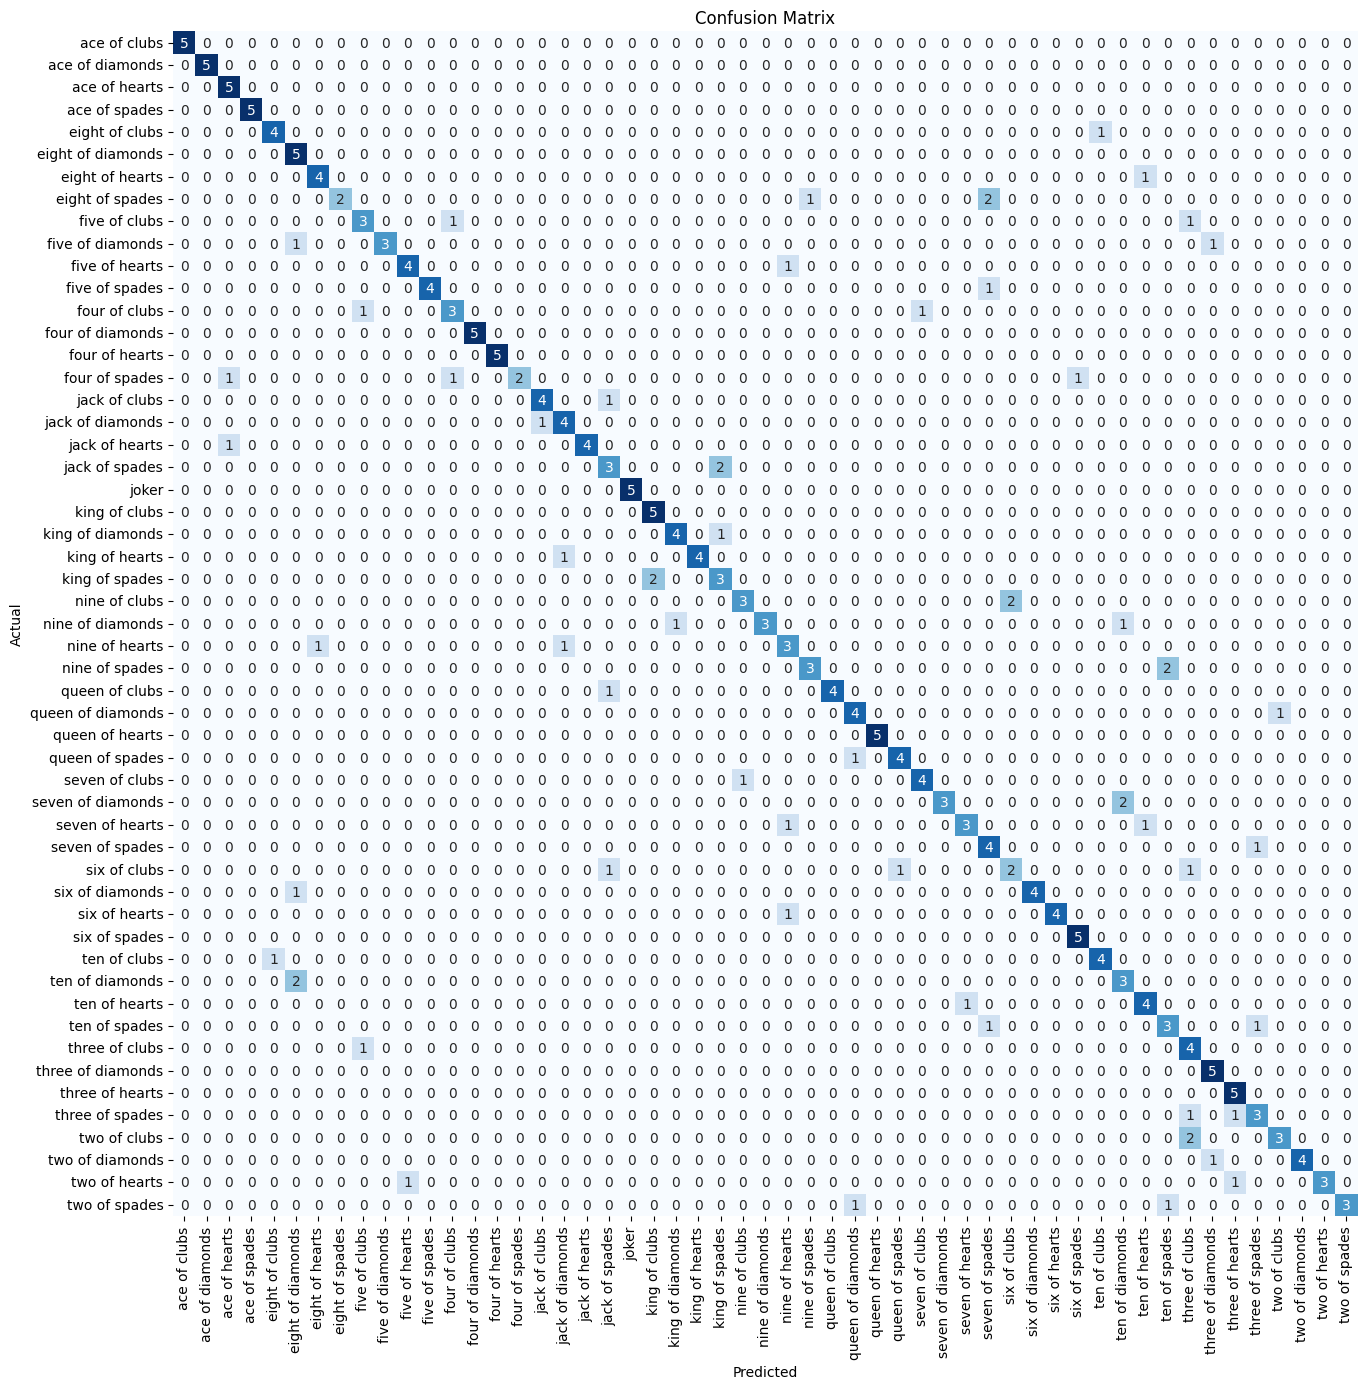

In [ ]:
def show_report_local(model, dataframe):
    labels = dataframe.class_indices
    true_labels = dataframe.labels
    pred_labels = model.predict(dataframe, verbose=0).argmax(axis=1)
    keys_array = np.array(list(labels.keys()))
    true_text = [keys_array[value] for value in true_labels]
    pred_text = [keys_array[value] for value in pred_labels]
    print(classification_report(true_text, pred_text))

def show_matrix_local(model, dataframe):
    labels = dataframe.class_indices
    true_labels = dataframe.labels
    pred_labels = model.predict(dataframe, verbose=0).argmax(axis=1)
    keys_array = np.array(list(labels.keys()))
    true_text = [keys_array[value] for value in true_labels]
    pred_text = [keys_array[value] for value in pred_labels]
    cf = confusion_matrix(true_text, pred_text, labels=keys_array)
    fig, ax = plt.subplots(figsize=(14, 14))
    sns.heatmap(cf, annot=True, fmt='d', square=True, cbar=False, cmap=plt.cm.Blues, xticklabels=keys_array, yticklabels=keys_array, ax=ax)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')
    ax.set_title('Confusion Matrix')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
path_ganador = str(RESULTADOS / '02_Dataset_Ampliado' / 'ResNet50V2_FineTuning_best.keras')
if os.path.exists(path_ganador):
    print(f'Cargando el modelo ganador para la evaluación detallada: {path_ganador}\n')
    modelo_ganador = tf.keras.models.load_model(path_ganador)
    print('=== REPORTE DE CLASIFICACIÓN DEL MODELO OPTIMIZADO ===')
    show_report_local(modelo_ganador, test_dataset_ffd)
    print('\n=== MATRIZ DE CONFUSIÓN DEL MODELO OPTIMIZADO ===')
    show_matrix_local(modelo_ganador, test_dataset_ffd)
else:
    print(f'No se encontró el modelo en {path_ganador}. Por favor verifica el entrenamiento.')


### 2.3. Conclusión de la ampliación y primer prototipo con originales

Tras el ajuste fino con train ampliado y validación original+jokers, ResNet obtiene 76,23 % y MobileNet 69,43 % en test, por debajo de MobileNet_2 (86,42 %). Se decide recuperar los originales y conservar solo el refuerzo específico de jokers.

El primer prototipo cambia simultáneamente cabeza, optimizador, escala, aumento de datos y carga de imágenes. Obtiene 53,58 %; train y valid quedan bajos, de modo que no es el mismo patrón que un entrenamiento casi perfecto con validación estancada. El `shuffle(512)` sobre un listado ordenado por clases puede limitar la mezcla, pero no se aisló su efecto. No sería correcto culpar únicamente al dropout ni presentar este prototipo como una mejora demostrada.

In [ ]:
liberar_modelos_y_datasets()
datos = preparar_jokers()
tf.keras.utils.set_random_seed(2026)

def cargar(conjunto):
    return tf.keras.utils.image_dataset_from_directory(datos / conjunto, image_size=(224, 224), batch_size=64, label_mode='int', shuffle=False)
train = cargar('train')
clases = train.class_names
valid = cargar('valid')
test = cargar('test')
assert len(clases) == 53
assert valid.class_names == clases == test.class_names
train = train.unbatch().cache().shuffle(512, seed=2026).batch(64).prefetch(tf.data.AUTOTUNE)
valid = valid.cache().prefetch(tf.data.AUTOTUNE)
test = test.cache().prefetch(tf.data.AUTOTUNE)
base = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base.trainable = False
entrada = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.layers.RandomRotation(15 / 360, fill_mode='reflect')(entrada)
x = tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode='reflect')(x)
x = tf.keras.layers.RandomZoom(0.1, fill_mode='reflect')(x)
x = tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255))(x)
x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)
x = base(x, training=False)
x = tf.keras.layers.Conv2D(64, 1, activation='relu')(x)
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
salida = tf.keras.layers.Dense(53, activation='softmax')(x)
modelo = tf.keras.Model(entrada, salida)
carpeta_modelo = RESULTADOS / '02_Prototipo_Descartado' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
carpeta_modelo.mkdir(parents=True)
ruta_modelo = str(carpeta_modelo / 'mejor_modelo.keras')

def callbacks(umbral=None):
    return [tf.keras.callbacks.ModelCheckpoint(ruta_modelo, monitor='val_accuracy', mode='max', save_best_only=True, initial_value_threshold=umbral), tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=5), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-07)]
print('\nFASE 1: entrenando el clasificador')
modelo.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
historia = modelo.fit(train, validation_data=valid, epochs=15, callbacks=callbacks(), verbose=2)
modelo.load_weights(ruta_modelo)
mejor_validacion = max(historia.history['val_accuracy'])
print('\nFASE 2: ajustando MobileNet')
base.trainable = True
corte = next((i for i, capa in enumerate(base.layers) if capa.name == 'block_13_expand'))
for i, capa in enumerate(base.layers):
    capa.trainable = i >= corte and (not isinstance(capa, tf.keras.layers.BatchNormalization))
modelo.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-05, weight_decay=1e-05), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
modelo.fit(train, validation_data=valid, epochs=30, callbacks=callbacks(mejor_validacion), verbose=2)
mejor_modelo = tf.keras.models.load_model(ruta_modelo, compile=False)
mejor_modelo.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
loss, accuracy = mejor_modelo.evaluate(test, verbose=0)
print(f'\nACCURACY FINAL: {accuracy * 100:.2f}%')
print('REFERENCIA ANTERIOR: 86.42%')
print(f'DIFERENCIA: {(accuracy - 229 / 265) * 100:+.2f} puntos')
print('MODELO GUARDADO EN:', ruta_modelo)


Datos preparados: originales + 15 Jokers nuevos.
Found 7636 files belonging to 53 classes.
Found 268 files belonging to 53 classes.
Found 265 files belonging to 53 classes.

FASE 1: entrenando el clasificador
Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


120/120 - 21s - 177ms/step - accuracy: 0.0616 - loss: 3.8614 - val_accuracy: 0.0336 - val_loss: 3.9625 - learning_rate: 0.0010
Epoch 2/15
120/120 - 9s - 75ms/step - accuracy: 0.0613 - loss: 3.7880 - val_accuracy: 0.0410 - val_loss: 3.8631 - learning_rate: 0.0010
Epoch 3/15
120/120 - 8s - 71ms/step - accuracy: 0.1134 - loss: 3.5314 - val_accuracy: 0.0336 - val_loss: 5.4619 - learning_rate: 0.0010
Epoch 4/15
120/120 - 9s - 75ms/step - accuracy: 0.2241 - loss: 2.8523 - val_accuracy: 0.0597 - val_loss: 5.4534 - learning_rate: 0.0010
Epoch 5/15
120/120 - 9s - 75ms/step - accuracy: 0.2427 - loss: 2.6631 - val_accuracy: 0.0709 - val_loss: 5.9492 - learning_rate: 5.0000e-04
Epoch 6/15
120/120 - 9s - 74ms/step - accuracy: 0.3055 - loss: 2.3886 - val_accuracy: 0.1082 - val_loss: 5.7876 - learning_rate: 5.0000e-04
Epoch 7/15
120/120 - 9s - 75ms/step - accuracy: 0.2901 - loss: 2.4920 - val_accuracy: 0.1679 - val_loss: 4.8505 - learning_rate: 2.5000e-04
Epoch 8/15
120/120 - 8s - 70ms/step - accurac

## 3. Recuperar la configuración original con los nuevos jokers

**Decisión:** antes de modificar más piezas, recuperar una referencia interpretable: MobileNetV2 → Flatten → Dense128 → Dense64 → 53 clases; primera fase de 25 épocas y ajuste fino de hasta 100, congelando las primeras 130 capas.

Se reconstruye un directorio limpio desde `Cards.zip`, se añaden 12 jokers a train y 3 a valid, y se conserva test. Los recuentos definitivos son **7.636 / 268 / 265**. Los 265 ejemplos de test incluyen los mismos 5 jokers originales; no se les añaden imágenes nuevas.

**Resultado:** 87,92 % (233/265), frente a 86,42 % (229/265).

**Asi logramos la primera mejora respecto al modelo base**

In [ ]:
liberar_modelos_y_datasets()
datos = preparar_jokers()
guardado = RESULTADOS / '03_MobileNet_Original_Jokers' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
guardado.mkdir(parents=True)
print('Modelos guardados en:', guardado)
ImageDataGenerator = tf.keras.preprocessing.image.ImageDataGenerator
generador_inicial = ImageDataGenerator(rescale=1.0 / 255, rotation_range=10, horizontal_flip=True)
generador_evaluacion = ImageDataGenerator(rescale=1.0 / 255)

def crear_dataset(generador, conjunto, shuffle):
    return generador.flow_from_directory(str(datos / conjunto), target_size=(224, 224), class_mode='categorical', batch_size=64, shuffle=shuffle)
train_original_jokers = crear_dataset(generador_inicial, 'train', True)
valid_original_jokers = crear_dataset(generador_evaluacion, 'valid', False)
test_original = crear_dataset(generador_evaluacion, 'test', False)
assert train_original_jokers.samples == 7636
assert valid_original_jokers.samples == 268
assert test_original.samples == 265
assert train_original_jokers.class_indices == valid_original_jokers.class_indices == test_original.class_indices
assert train_original_jokers.num_classes == 53
base_original = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base_original.trainable = False
modelo_original_jokers = tf.keras.Sequential([base_original, tf.keras.layers.Flatten(), tf.keras.layers.Dense(128, activation='relu'), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.Dense(53, activation='softmax')])

def callbacks_originales(ruta, min_delta):
    return [tf.keras.callbacks.ModelCheckpoint(str(ruta), monitor='val_accuracy', mode='max', save_best_only=True), tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', min_delta=min_delta, patience=20, restore_best_weights=True)]
ruta_inicial = guardado / 'MobileNet_inicial_jokers.keras'
modelo_original_jokers.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
print('\nFASE 1: configuración original, originales + Jokers')
historia_inicial_jokers = modelo_original_jokers.fit(train_original_jokers, validation_data=valid_original_jokers, epochs=25, callbacks=callbacks_originales(ruta_inicial, min_delta=0.01))
generador_ajuste = ImageDataGenerator(rescale=1.0 / 255, rotation_range=15, horizontal_flip=True, vertical_flip=True, zoom_range=0.1, fill_mode='reflect')
train_ajuste_jokers = crear_dataset(generador_ajuste, 'train', True)
modelo_mn2_jokers = tf.keras.models.load_model(str(ruta_inicial), compile=False)
base_ajuste = next((capa for capa in modelo_mn2_jokers.layers if isinstance(capa, tf.keras.Model)))
base_ajuste.trainable = True
for i, capa in enumerate(base_ajuste.layers):
    capa.trainable = i >= 130
ruta_final = guardado / 'MobileNet_2_jokers.keras'
modelo_mn2_jokers.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
print('\nFASE 2: ajuste fino original de MobileNet_2')
historia_ajuste_jokers = modelo_mn2_jokers.fit(train_ajuste_jokers, validation_data=valid_original_jokers, epochs=100, callbacks=callbacks_originales(ruta_final, min_delta=0.001))
mejor_mn2_jokers = tf.keras.models.load_model(str(ruta_final), compile=False)
mejor_mn2_jokers.compile(loss='categorical_crossentropy', metrics=['accuracy'])
test_original.reset()
loss, accuracy = mejor_mn2_jokers.evaluate(test_original)
print(f'\nACCURACY FINAL: {accuracy * 100:.2f}%')
print('REFERENCIA HISTÓRICA: 86.42%')
print(f'DIFERENCIA: {(accuracy - 229 / 265) * 100:+.2f} puntos')
print('MODELO GUARDADO EN:', ruta_final)
RUTA_MOBILE_JOKERS = Path(ruta_final)


Modelos guardados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/MobileNet_Configuracion_Original_Jokers/20261114_180802_747119
Found 7636 images belonging to 53 classes.
Found 268 images belonging to 53 classes.
Found 265 images belonging to 53 classes.

FASE 1: configuración original, originales + Jokers
Epoch 1/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 110s 797ms/step - accuracy: 0.2177 - loss: 3.3466 - val_accuracy: 0.4142 - val_loss: 2.2169
Epoch 2/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 81s 674ms/step - accuracy: 0.4984 - loss: 1.8372 - val_accuracy: 0.5037 - val_loss: 1.7253
Epoch 3/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 77s 643ms/step - accuracy: 0.6146 - loss: 1.4016 - val_accuracy: 0.5299 - val_loss: 1.5711
Epoch 4/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 78s 651ms/step - accuracy: 0.6769 - loss: 1.1165 - val_accuracy: 0.5597 - val_loss: 1.5099
Epoch 5/25
120/120 ━━━━━━━━━━━━━━━━━━━━ 83s 688ms/step - accuracy: 0.7304 - loss: 0.9102 - val_accuracy: 0.6045 - val_loss: 1.4591
Epoch 6/25
120/

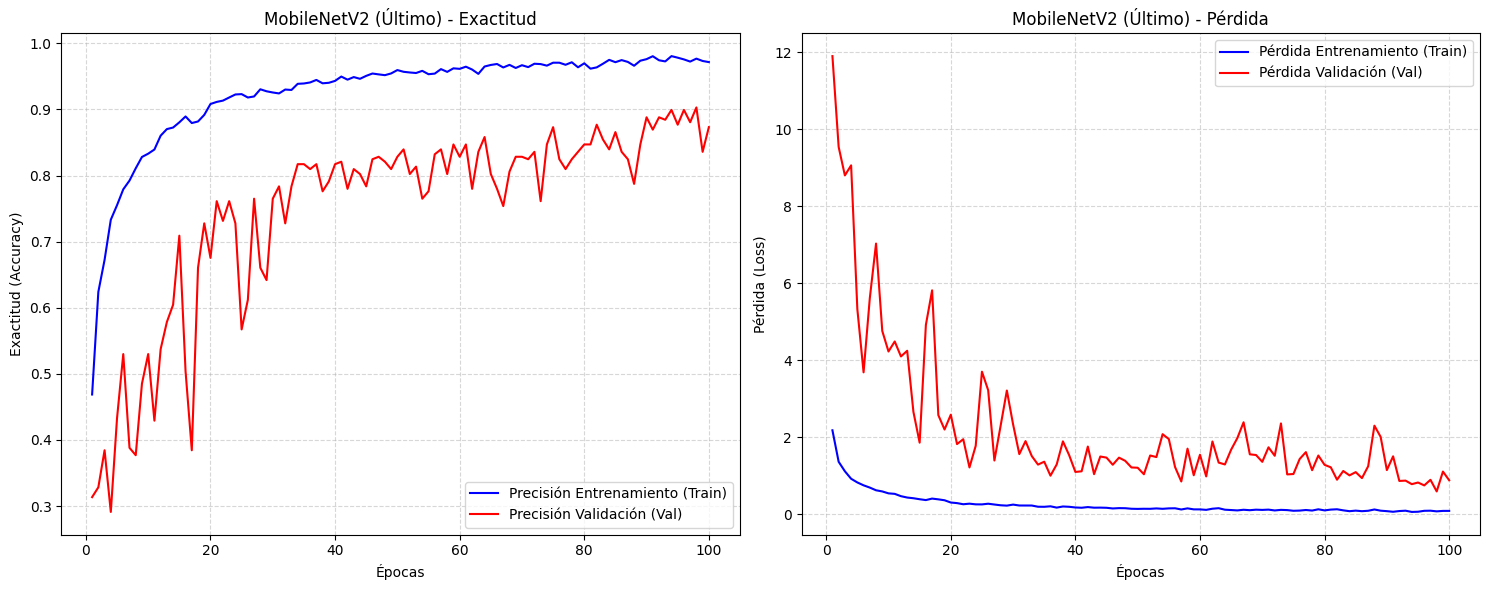

In [ ]:
history = historia_ajuste_jokers.history
epochs = range(1, len(history['accuracy']) + 1)
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['accuracy'], 'b-', label='Precisión Entrenamiento (Train)')
plt.plot(epochs, history['val_accuracy'], 'r-', label='Precisión Validación (Val)')
plt.title('MobileNetV2 (Último) - Exactitud')
plt.xlabel('Épocas')
plt.ylabel('Exactitud (Accuracy)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.subplot(1, 2, 2)
plt.plot(epochs, history['loss'], 'b-', label='Pérdida Entrenamiento (Train)')
plt.plot(epochs, history['val_loss'], 'r-', label='Pérdida Validación (Val)')
plt.title('MobileNetV2 (Último) - Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step

=== INFORME DE CLASIFICACIÓN ===

                   precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      1.000     1.000     1.000         5
    ace of hearts      0.833     1.000     0.909         5
    ace of spades      1.000     1.000     1.000         5
   eight of clubs      1.000     0.800     0.889         5
eight of diamonds      0.833     1.000     0.909         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      0.833     1.000     0.909         5
    five of clubs      1.000     0.800     0.889         5
 five of diamonds      1.000     0.800     0.889         5
   five of hearts      1.000     1.000     1.000         5
   five of spades      1.000     1.000     1.000         5
    four of clubs      1.000     1.000     1.000         5
 four of diamonds      1.000     1.000     1.000         5
   four of hearts      0.833     1.000     

,Imagen,Real,Predicha,Confianza,Correcta
0,joker/1.jpg,joker,ten of clubs,0.730476,False
1,joker/2.jpg,joker,joker,0.999998,True
2,joker/3.jpg,joker,joker,0.994622,True
3,joker/4.jpg,joker,joker,1.000000,True
4,joker/5.jpg,joker,joker,0.996981,True


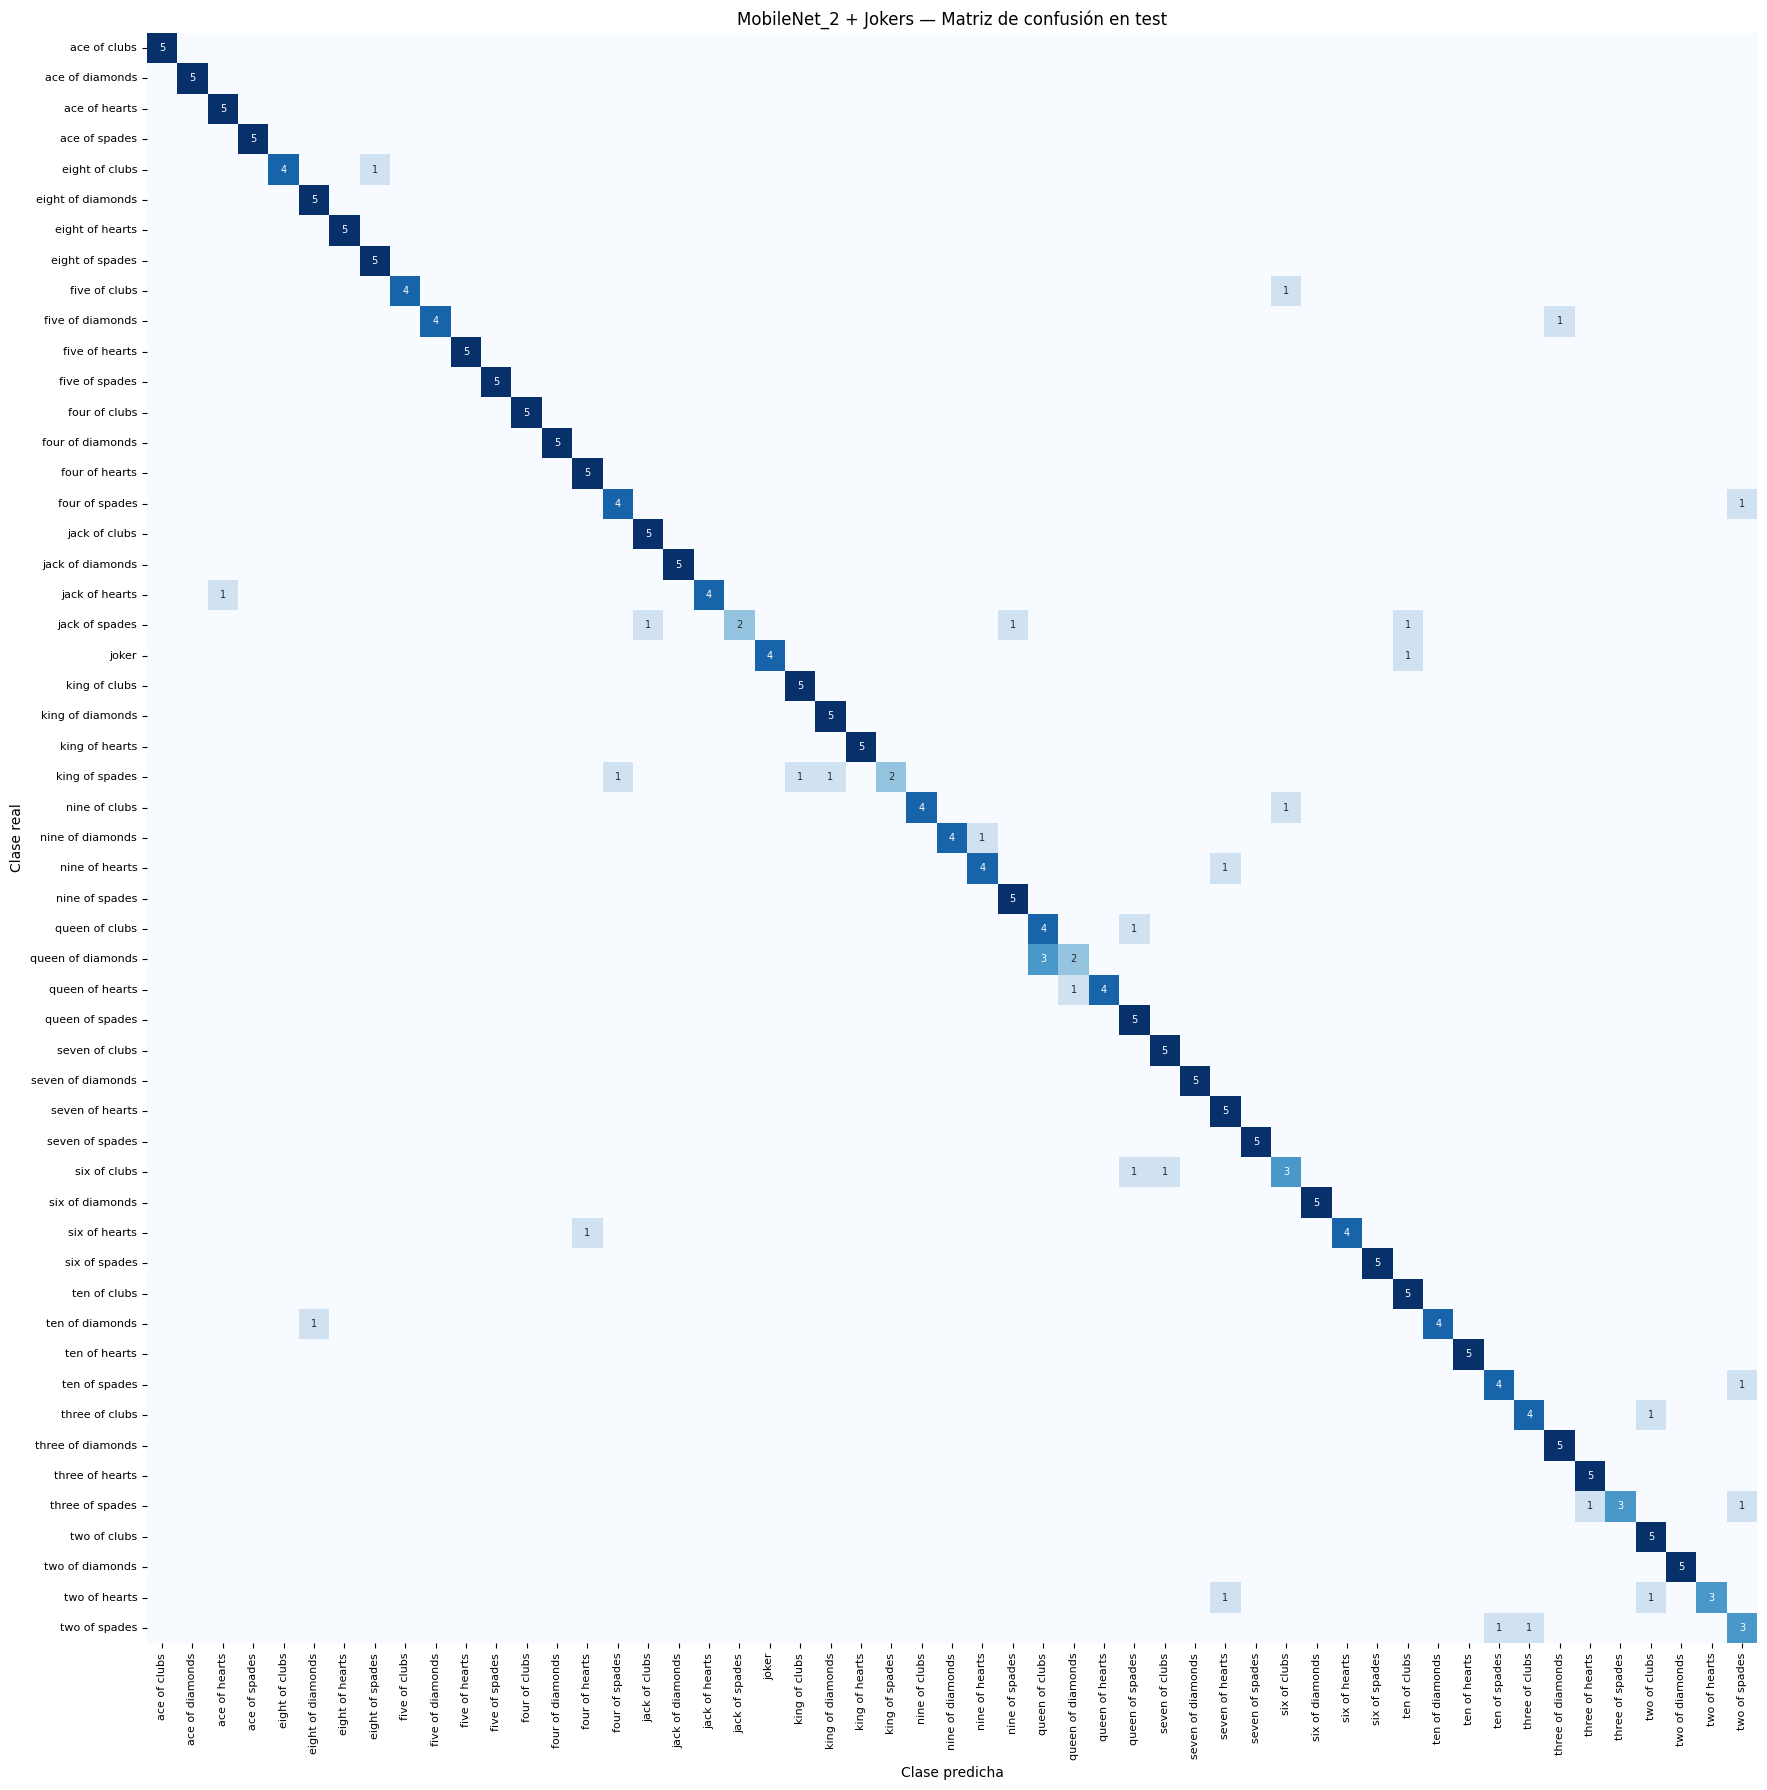


=== CONFUSIONES MÁS FRECUENTES: 32 ERRORES ===


,Real,Predicha,Cantidad
0,queen of diamonds,queen of clubs,3
1,eight of clubs,eight of spades,1
2,five of diamonds,three of diamonds,1
3,four of spades,two of spades,1
4,jack of hearts,ace of hearts,1
5,five of clubs,six of clubs,1
6,jack of spades,nine of spades,1
7,jack of spades,ten of clubs,1
8,joker,ten of clubs,1
9,king of spades,four of spades,1



=== DETALLE DE CADA IMAGEN MAL CLASIFICADA ===


,Imagen,Real,Predicha,Confianza
0,two of hearts/4.jpg,two of hearts,seven of hearts,0.996486
1,three of clubs/4.jpg,three of clubs,two of clubs,0.994391
2,three of spades/5.jpg,three of spades,two of spades,0.990666
3,jack of spades/4.jpg,jack of spades,jack of clubs,0.985650
4,king of spades/2.jpg,king of spades,four of spades,0.981368
5,six of hearts/1.jpg,six of hearts,four of hearts,0.905726
6,eight of clubs/3.jpg,eight of clubs,eight of spades,0.887249
7,king of spades/4.jpg,king of spades,king of clubs,0.864460
8,two of hearts/2.jpg,two of hearts,two of clubs,0.857066
9,ten of diamonds/2.jpg,ten of diamonds,eight of diamonds,0.848622


In [ ]:
assert not test_original.shuffle, 'El test debe tener shuffle=False.'
test_original.reset()
probabilidades = mejor_mn2_jokers.predict(test_original, verbose=1)
reales = np.asarray(test_original.classes)
predichas = probabilidades.argmax(axis=1)
assert len(predichas) == len(reales)
clases = [nombre for nombre, indice in sorted(test_original.class_indices.items(), key=lambda elemento: elemento[1])]
print('\n=== INFORME DE CLASIFICACIÓN ===\n')
print(classification_report(reales, predichas, labels=np.arange(len(clases)), target_names=clases, digits=3, zero_division=0))
resultados = pd.DataFrame({'Imagen': test_original.filenames, 'Real': [clases[i] for i in reales], 'Predicha': [clases[i] for i in predichas], 'Confianza': probabilidades.max(axis=1)})
resultados['Correcta'] = reales == predichas
indice_joker = test_original.class_indices['joker']
joker_real = reales == indice_joker
joker_predicho = predichas == indice_joker
aciertos_joker = np.sum(joker_real & joker_predicho)
falsos_jokers = np.sum(~joker_real & joker_predicho)
print('\n=== RESULTADOS DEL JOKER ===')
print(f'Jokers reconocidos: {aciertos_joker}/{joker_real.sum()}')
print(f'Otras cartas confundidas con Joker: {falsos_jokers}')
print('Modelo anterior: 0/5 Jokers reconocidos.\n')
display(resultados.loc[joker_real | joker_predicho, ['Imagen', 'Real', 'Predicha', 'Confianza', 'Correcta']].reset_index(drop=True))
matriz = confusion_matrix(reales, predichas, labels=np.arange(len(clases)))
anotaciones = np.where(matriz > 0, matriz.astype(str), '')
plt.figure(figsize=(20, 18))
sns.heatmap(matriz, annot=anotaciones, fmt='', cmap='Blues', cbar=False, square=True, xticklabels=clases, yticklabels=clases, annot_kws={'size': 7})
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('MobileNet_2 + Jokers — Matriz de confusión en test')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()
errores = resultados.loc[~resultados['Correcta']].copy()
print(f'\n=== CONFUSIONES MÁS FRECUENTES: {len(errores)} ERRORES ===')
if errores.empty:
    print('Todas las cartas se han clasificado correctamente.')
else:
    confusiones = errores.groupby(['Real', 'Predicha']).size().reset_index(name='Cantidad').sort_values('Cantidad', ascending=False)
    display(confusiones.reset_index(drop=True))
    print('\n=== DETALLE DE CADA IMAGEN MAL CLASIFICADA ===')
    display(errores[['Imagen', 'Real', 'Predicha', 'Confianza']].sort_values('Confianza', ascending=False).reset_index(drop=True))


## 4. Regularización y comparación a 224

Las curvas anteriores muestran un entrenamiento alto y una validación más baja e inestable. Se prueba continuar el checkpoint con una tasa menor y se contrastan MobileNet con dropout, ResNet50V2 y EfficientNetB0 con preprocesamientos adecuados.

La continuación de MobileNet llega a 90,19 % en test. El nuevo MobileNet con dropout obtiene 73,96 %, ResNet 77,74 % y EfficientNet 86,04 %. La variante con dropout modifica también el entrenamiento y el aumento de datos: **no es una comparación que aísle el efecto del dropout**.

Se prueban medias de probabilidades: MobileNet+ResNet alcanza 90,94 % observado en test. La media de tres arquitecturas fue la elegida por validación (92,16 %) y obtiene 89,43 % en test.

In [ ]:
liberar_modelos_y_datasets()
RUTA_BASE = RUTA_MOBILE_JOKERS
SEED, BATCH = (2026, 64)
tf.keras.utils.set_random_seed(SEED)
SALIDA = RESULTADOS / '04_Comparativa_224'
SALIDA.mkdir(parents=True, exist_ok=True)
DATOS = preparar_jokers()
CLASES = CLASES_CARTAS
archivos = RUTAS_CARTAS
etiquetas = ETIQUETAS_CARTAS

def leer_imagen(path):
    with Image.open(path.numpy().decode()) as im:
        return np.asarray(im.convert('RGB').resize((224, 224), Image.Resampling.NEAREST), dtype=np.uint8)

def decodificar(path, y):
    x = tf.py_function(leer_imagen, [path], Tout=tf.uint8)
    x.set_shape((224, 224, 3))
    return (x, tf.one_hot(y, 53))

def construir_dataset(split):
    ds = tf.data.Dataset.from_tensor_slices((archivos[split], etiquetas[split]))
    ds = ds.map(decodificar, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if split == 'train':
        ds = ds.shuffle(len(archivos[split]), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
TRAIN, VALID, TEST = [construir_dataset(s) for s in ['train', 'valid', 'test']]
RUTAS = {'MobileNet_actual': str(RUTA_BASE)}
(SALIDA / 'clases.json').write_text(json.dumps(CLASES, indent=2))
print('Datos: 7636 train / 268 valid / 265 test')
print('Resultados y modelos:', SALIDA)

def envolver(red, escala, nombre):
    entrada = tf.keras.Input((224, 224, 3), name='rgb_0_255')
    x = tf.keras.layers.RandomRotation(15 / 360, fill_mode='reflect', seed=SEED)(entrada)
    x = tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED + 1)(x)
    x = tf.keras.layers.RandomZoom(0.1, fill_mode='reflect', seed=SEED + 2)(x)
    if escala == '0_1':
        x = tf.keras.layers.Rescaling(1 / 255)(x)
    elif escala == '-1_1':
        x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)
    return tf.keras.Model(entrada, red(x), name=nombre)

class MejorValidacion(tf.keras.callbacks.Callback):

    def __init__(self, ruta, loss, acc):
        super().__init__()
        self.ruta = str(ruta)
        self.loss = float(loss)
        self.acc = float(acc)

    def on_epoch_end(self, epoch, logs=None):
        acc = float(logs['val_accuracy'])
        loss = float(logs['val_loss'])
        mejora = acc > self.acc + 1e-08
        empate_mejor_loss = abs(acc - self.acc) <= 1e-08 and loss < self.loss
        if mejora or empate_mejor_loss:
            self.acc, self.loss = (acc, loss)
            self.model.save(self.ruta)
            print(f'  Mejor checkpoint: valid={acc:.2%}; loss={loss:.4f}', flush=True)

def entrenar(modelo, nombre, epochs, lr, paciencia=10):
    ruta = SALIDA / f'{nombre}.keras'
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    loss, acc = modelo.evaluate(VALID, verbose=0)
    modelo.save(str(ruta))
    modelo.fit(TRAIN, validation_data=VALID, epochs=epochs, callbacks=[MejorValidacion(ruta, loss, acc), tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=paciencia), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-06), tf.keras.callbacks.CSVLogger(str(SALIDA / f'{nombre}.csv'))], verbose=2)
    modelo.load_weights(str(ruta))
    return str(ruta)

def modelo_nuevo(tipo):
    tf.keras.utils.set_random_seed(SEED)
    if tipo == 'mobilenet':
        base = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
        red = tf.keras.Sequential([base, tf.keras.layers.Flatten(), tf.keras.layers.Dense(128, activation='relu'), tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.Dense(53, activation='softmax')])
        escala = '0_1'
    else:
        constructor = tf.keras.applications.ResNet50V2 if tipo == 'resnet' else tf.keras.applications.EfficientNetB0
        base = constructor(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
        red = tf.keras.Sequential([base, tf.keras.layers.GlobalAveragePooling2D(), tf.keras.layers.Dense(256, activation='relu'), tf.keras.layers.Dropout(0.2), tf.keras.layers.Dense(53, activation='softmax')])
        escala = '-1_1' if tipo == 'resnet' else '0_255'
    base.trainable = False
    return (envolver(red, escala, f'{tipo}_cartas'), base)

def descongelar(base, tipo):
    base.trainable = True
    for i, capa in enumerate(base.layers):
        if tipo == 'mobilenet':
            capa.trainable = i >= 130
        else:
            ultimo_bloque = capa.name.startswith('conv5_') if tipo == 'resnet' else capa.name.startswith(('block6', 'block7', 'top_'))
            capa.trainable = ultimo_bloque and (not isinstance(capa, tf.keras.layers.BatchNormalization))
    assert len(base.trainable_weights) > 0
print('Funciones listas. La siguiente celda empieza a entrenar.')


Datos: 7636 train / 268 valid / 265 test
Resultados y modelos: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Comparativa_Originales_Jokers/20261114_213020_894635


Funciones listas. La siguiente celda empieza a entrenar.


In [ ]:
tf.keras.utils.set_random_seed(SEED)
red_continuacion = tf.keras.models.load_model(str(RUTA_BASE), compile=False)
modelo_continuacion = envolver(red_continuacion, '0_1', 'mobilenet_continuacion')
RUTAS['MobileNet_continuacion'] = entrenar(modelo_continuacion, 'MobileNet_continuacion', epochs=30, lr=0.0001)
del modelo_continuacion, red_continuacion
gc.collect()
print('Continuación terminada y guardada.')


Epoch 1/30
  Mejor checkpoint: valid=90.30%; loss=0.5732
120/120 - 30s - 252ms/step - accuracy: 0.9746 - loss: 0.0761 - val_accuracy: 0.9030 - val_loss: 0.5732 - learning_rate: 1.0000e-04
Epoch 2/30
120/120 - 9s - 77ms/step - accuracy: 0.9828 - loss: 0.0565 - val_accuracy: 0.9030 - val_loss: 0.5759 - learning_rate: 1.0000e-04
Epoch 3/30
120/120 - 9s - 77ms/step - accuracy: 0.9861 - loss: 0.0472 - val_accuracy: 0.8955 - val_loss: 0.5596 - learning_rate: 1.0000e-04
Epoch 4/30
120/120 - 9s - 77ms/step - accuracy: 0.9897 - loss: 0.0376 - val_accuracy: 0.8993 - val_loss: 0.5537 - learning_rate: 1.0000e-04
Epoch 5/30
  Mejor checkpoint: valid=90.30%; loss=0.5316
120/120 - 10s - 84ms/step - accuracy: 0.9911 - loss: 0.0284 - val_accuracy: 0.9030 - val_loss: 0.5316 - learning_rate: 1.0000e-04
Epoch 6/30
  Mejor checkpoint: valid=90.67%; loss=0.5236
120/120 - 11s - 91ms/step - accuracy: 0.9907 - loss: 0.0319 - val_accuracy: 0.9067 - val_loss: 0.5236 - learning_rate: 1.0000e-04
Epoch 7/30
  Mejor

In [ ]:
modelo_dropout, base_dropout = modelo_nuevo('mobilenet')
print('FASE 1: clasificador con Dropout')
entrenar(modelo_dropout, 'MobileNet_dropout_cabeza', epochs=25, lr=0.001)
descongelar(base_dropout, 'mobilenet')
print('FASE 2: ajuste fino')
RUTAS['MobileNet_dropout'] = entrenar(modelo_dropout, 'MobileNet_dropout_final', epochs=100, lr=0.0001, paciencia=15)
del modelo_dropout, base_dropout
gc.collect()
print('MobileNet con Dropout terminada y guardada.')


FASE 1: clasificador con Dropout
Epoch 1/25
  Mejor checkpoint: valid=8.58%; loss=3.3595
120/120 - 13s - 111ms/step - accuracy: 0.0625 - loss: 4.0396 - val_accuracy: 0.0858 - val_loss: 3.3595 - learning_rate: 0.0010
Epoch 2/25
  Mejor checkpoint: valid=14.55%; loss=2.8577
120/120 - 9s - 72ms/step - accuracy: 0.1003 - loss: 3.3122 - val_accuracy: 0.1455 - val_loss: 2.8577 - learning_rate: 0.0010
Epoch 3/25
  Mejor checkpoint: valid=19.40%; loss=2.5571
120/120 - 10s - 85ms/step - accuracy: 0.1310 - loss: 3.0062 - val_accuracy: 0.1940 - val_loss: 2.5571 - learning_rate: 0.0010
Epoch 4/25
  Mejor checkpoint: valid=21.64%; loss=2.4524
120/120 - 10s - 84ms/step - accuracy: 0.1674 - loss: 2.8238 - val_accuracy: 0.2164 - val_loss: 2.4524 - learning_rate: 0.0010
Epoch 5/25
  Mejor checkpoint: valid=25.37%; loss=2.2352
120/120 - 10s - 84ms/step - accuracy: 0.1850 - loss: 2.7093 - val_accuracy: 0.2537 - val_loss: 2.2352 - learning_rate: 0.0010
Epoch 6/25
  Mejor checkpoint: valid=28.73%; loss=2.0

In [ ]:
modelo_resnet, base_resnet_nueva = modelo_nuevo('resnet')
print('FASE 1: clasificador de ResNet')
entrenar(modelo_resnet, 'ResNet50V2_cabeza', epochs=25, lr=0.001)
descongelar(base_resnet_nueva, 'resnet')
print('FASE 2: ajuste fino del último bloque')
RUTAS['ResNet50V2'] = entrenar(modelo_resnet, 'ResNet50V2_final', epochs=60, lr=3e-05, paciencia=12)
del modelo_resnet, base_resnet_nueva
gc.collect()
print('ResNet terminada y guardada.')


FASE 1: clasificador de ResNet
Epoch 1/25
  Mejor checkpoint: valid=41.04%; loss=1.9969
120/120 - 20s - 167ms/step - accuracy: 0.2245 - loss: 2.8932 - val_accuracy: 0.4104 - val_loss: 1.9969 - learning_rate: 0.0010
Epoch 2/25
  Mejor checkpoint: valid=44.78%; loss=1.7519
120/120 - 14s - 118ms/step - accuracy: 0.4023 - loss: 2.0376 - val_accuracy: 0.4478 - val_loss: 1.7519 - learning_rate: 0.0010
Epoch 3/25
  Mejor checkpoint: valid=50.75%; loss=1.5825
120/120 - 14s - 118ms/step - accuracy: 0.4713 - loss: 1.7568 - val_accuracy: 0.5075 - val_loss: 1.5825 - learning_rate: 0.0010
Epoch 4/25
120/120 - 13s - 111ms/step - accuracy: 0.5234 - loss: 1.5570 - val_accuracy: 0.4664 - val_loss: 1.5167 - learning_rate: 0.0010
Epoch 5/25
  Mejor checkpoint: valid=54.48%; loss=1.4196
120/120 - 14s - 117ms/step - accuracy: 0.5722 - loss: 1.4033 - val_accuracy: 0.5448 - val_loss: 1.4196 - learning_rate: 0.0010
Epoch 6/25
120/120 - 13s - 110ms/step - accuracy: 0.5948 - loss: 1.3134 - val_accuracy: 0.5410 

In [ ]:
modelo_efficient, base_efficient_nueva = modelo_nuevo('efficientnet')
print('FASE 1: clasificador de EfficientNet')
entrenar(modelo_efficient, 'EfficientNetB0_cabeza', epochs=25, lr=0.001)
descongelar(base_efficient_nueva, 'efficientnet')
print('FASE 2: ajuste fino de los últimos bloques')
RUTAS['EfficientNetB0'] = entrenar(modelo_efficient, 'EfficientNetB0_final', epochs=60, lr=0.0001, paciencia=12)
del modelo_efficient, base_efficient_nueva
gc.collect()
(SALIDA / 'rutas_modelos.json').write_text(json.dumps(RUTAS, indent=2))
print('EfficientNet terminada. Todos los modelos están guardados.')


FASE 1: clasificador de EfficientNet
Epoch 1/25
  Mejor checkpoint: valid=35.82%; loss=2.0676
120/120 - 21s - 171ms/step - accuracy: 0.2102 - loss: 2.8823 - val_accuracy: 0.3582 - val_loss: 2.0676 - learning_rate: 0.0010
Epoch 2/25
  Mejor checkpoint: valid=43.66%; loss=1.7528
120/120 - 12s - 96ms/step - accuracy: 0.3909 - loss: 2.0586 - val_accuracy: 0.4366 - val_loss: 1.7528 - learning_rate: 0.0010
Epoch 3/25
  Mejor checkpoint: valid=45.90%; loss=1.6456
120/120 - 12s - 97ms/step - accuracy: 0.4724 - loss: 1.7531 - val_accuracy: 0.4590 - val_loss: 1.6456 - learning_rate: 0.0010
Epoch 4/25
  Mejor checkpoint: valid=50.37%; loss=1.6073
120/120 - 12s - 98ms/step - accuracy: 0.5327 - loss: 1.5607 - val_accuracy: 0.5037 - val_loss: 1.6073 - learning_rate: 0.0010
Epoch 5/25
  Mejor checkpoint: valid=52.24%; loss=1.5519
120/120 - 12s - 96ms/step - accuracy: 0.5655 - loss: 1.4294 - val_accuracy: 0.5224 - val_loss: 1.5519 - learning_rate: 0.0010
Epoch 6/25
  Mejor checkpoint: valid=53.73%; lo

In [ ]:
def predecir_guardado(nombre, ds):
    modelo = tf.keras.models.load_model(RUTAS[nombre], compile=False)
    if nombre == 'MobileNet_actual':
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255, y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    p = modelo.predict(ds, verbose=0)
    del modelo
    gc.collect()
    return p

def medir(p, y):
    acc = float(np.mean(p.argmax(axis=1) == y))
    loss = float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-07, 1)).mean())
    return (acc, loss)
P_VALID = {nombre: predecir_guardado(nombre, VALID) for nombre in RUTAS}
moviles = [nombre for nombre in RUTAS if nombre.startswith('MobileNet')]
mejor_movil = max(moviles, key=lambda nombre: (medir(P_VALID[nombre], etiquetas['valid'])[0], -medir(P_VALID[nombre], etiquetas['valid'])[1]))
COMBINACIONES = {nombre: [nombre] for nombre in RUTAS}
COMBINACIONES.update({'MobileNet_ResNet': [mejor_movil, 'ResNet50V2'], 'MobileNet_EfficientNet': [mejor_movil, 'EfficientNetB0'], 'ResNet_EfficientNet': ['ResNet50V2', 'EfficientNetB0'], 'Tres_arquitecturas': [mejor_movil, 'ResNet50V2', 'EfficientNetB0']})
filas_valid = []
for nombre, miembros in COMBINACIONES.items():
    p = np.mean([P_VALID[m] for m in miembros], axis=0)
    acc, loss = medir(p, etiquetas['valid'])
    filas_valid.append({'Modelo': nombre, 'Accuracy_valid': acc, 'Loss_valid': loss})
tabla_valid = pd.DataFrame(filas_valid).sort_values(['Accuracy_valid', 'Loss_valid'], ascending=[False, True])
GANADOR = tabla_valid.iloc[0]['Modelo']
tabla_valid.to_csv(SALIDA / 'comparacion_validacion.csv', index=False)
(SALIDA / 'seleccion.json').write_text(json.dumps({'ganador_validacion': GANADOR, 'miembros': COMBINACIONES[GANADOR], 'combinaciones': COMBINACIONES, 'rutas': RUTAS}, indent=2))
display(tabla_valid.style.format({'Accuracy_valid': '{:.2%}', 'Loss_valid': '{:.4f}'}))
print('Seleccionado mediante validación:', GANADOR)


,Modelo,Accuracy_valid,Loss_valid
8,Tres_arquitecturas,92.16%,0.3192
5,MobileNet_ResNet,91.79%,0.4087
1,MobileNet_continuacion,91.79%,0.5302
6,MobileNet_EfficientNet,91.42%,0.3299
0,MobileNet_actual,90.30%,0.5810
7,ResNet_EfficientNet,89.93%,0.4731
4,EfficientNetB0,88.43%,0.5616
3,ResNet50V2,84.33%,0.7664
2,MobileNet_dropout,73.51%,0.9207


Seleccionado mediante validación: Tres_arquitecturas


,Modelo,Accuracy_test,Loss_test,Aciertos
0,MobileNet_actual,87.92%,0.6311,233
1,MobileNet_continuacion,90.19%,0.5165,239
2,MobileNet_dropout,73.96%,0.9156,196
3,ResNet50V2,77.74%,1.0768,206
4,EfficientNetB0,86.04%,0.4981,228
5,MobileNet_ResNet,90.94%,0.4888,241
6,MobileNet_EfficientNet,89.43%,0.3179,237
7,ResNet_EfficientNet,84.91%,0.5242,225
8,Tres_arquitecturas,89.43%,0.3722,237



GANADOR SELECCIONADO EN VALIDACIÓN: Tres_arquitecturas
Accuracy test: 89.43%
Referencia actual: 87,92 % — 233/265
Diferencia: +1.51 puntos porcentuales
Jokers: 5/5
                   precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      1.000     1.000     1.000         5
    ace of hearts      0.833     1.000     0.909         5
    ace of spades      1.000     1.000     1.000         5
   eight of clubs      1.000     1.000     1.000         5
eight of diamonds      0.833     1.000     0.909         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      1.000     1.000     1.000         5
    five of clubs      0.667     0.800     0.727         5
 five of diamonds      1.000     0.800     0.889         5
   five of hearts      1.000     0.800     0.889         5
   five of spades      1.000     1.000     1.000         5
    four of clubs      1.000     1.000     1.000         5
 four of

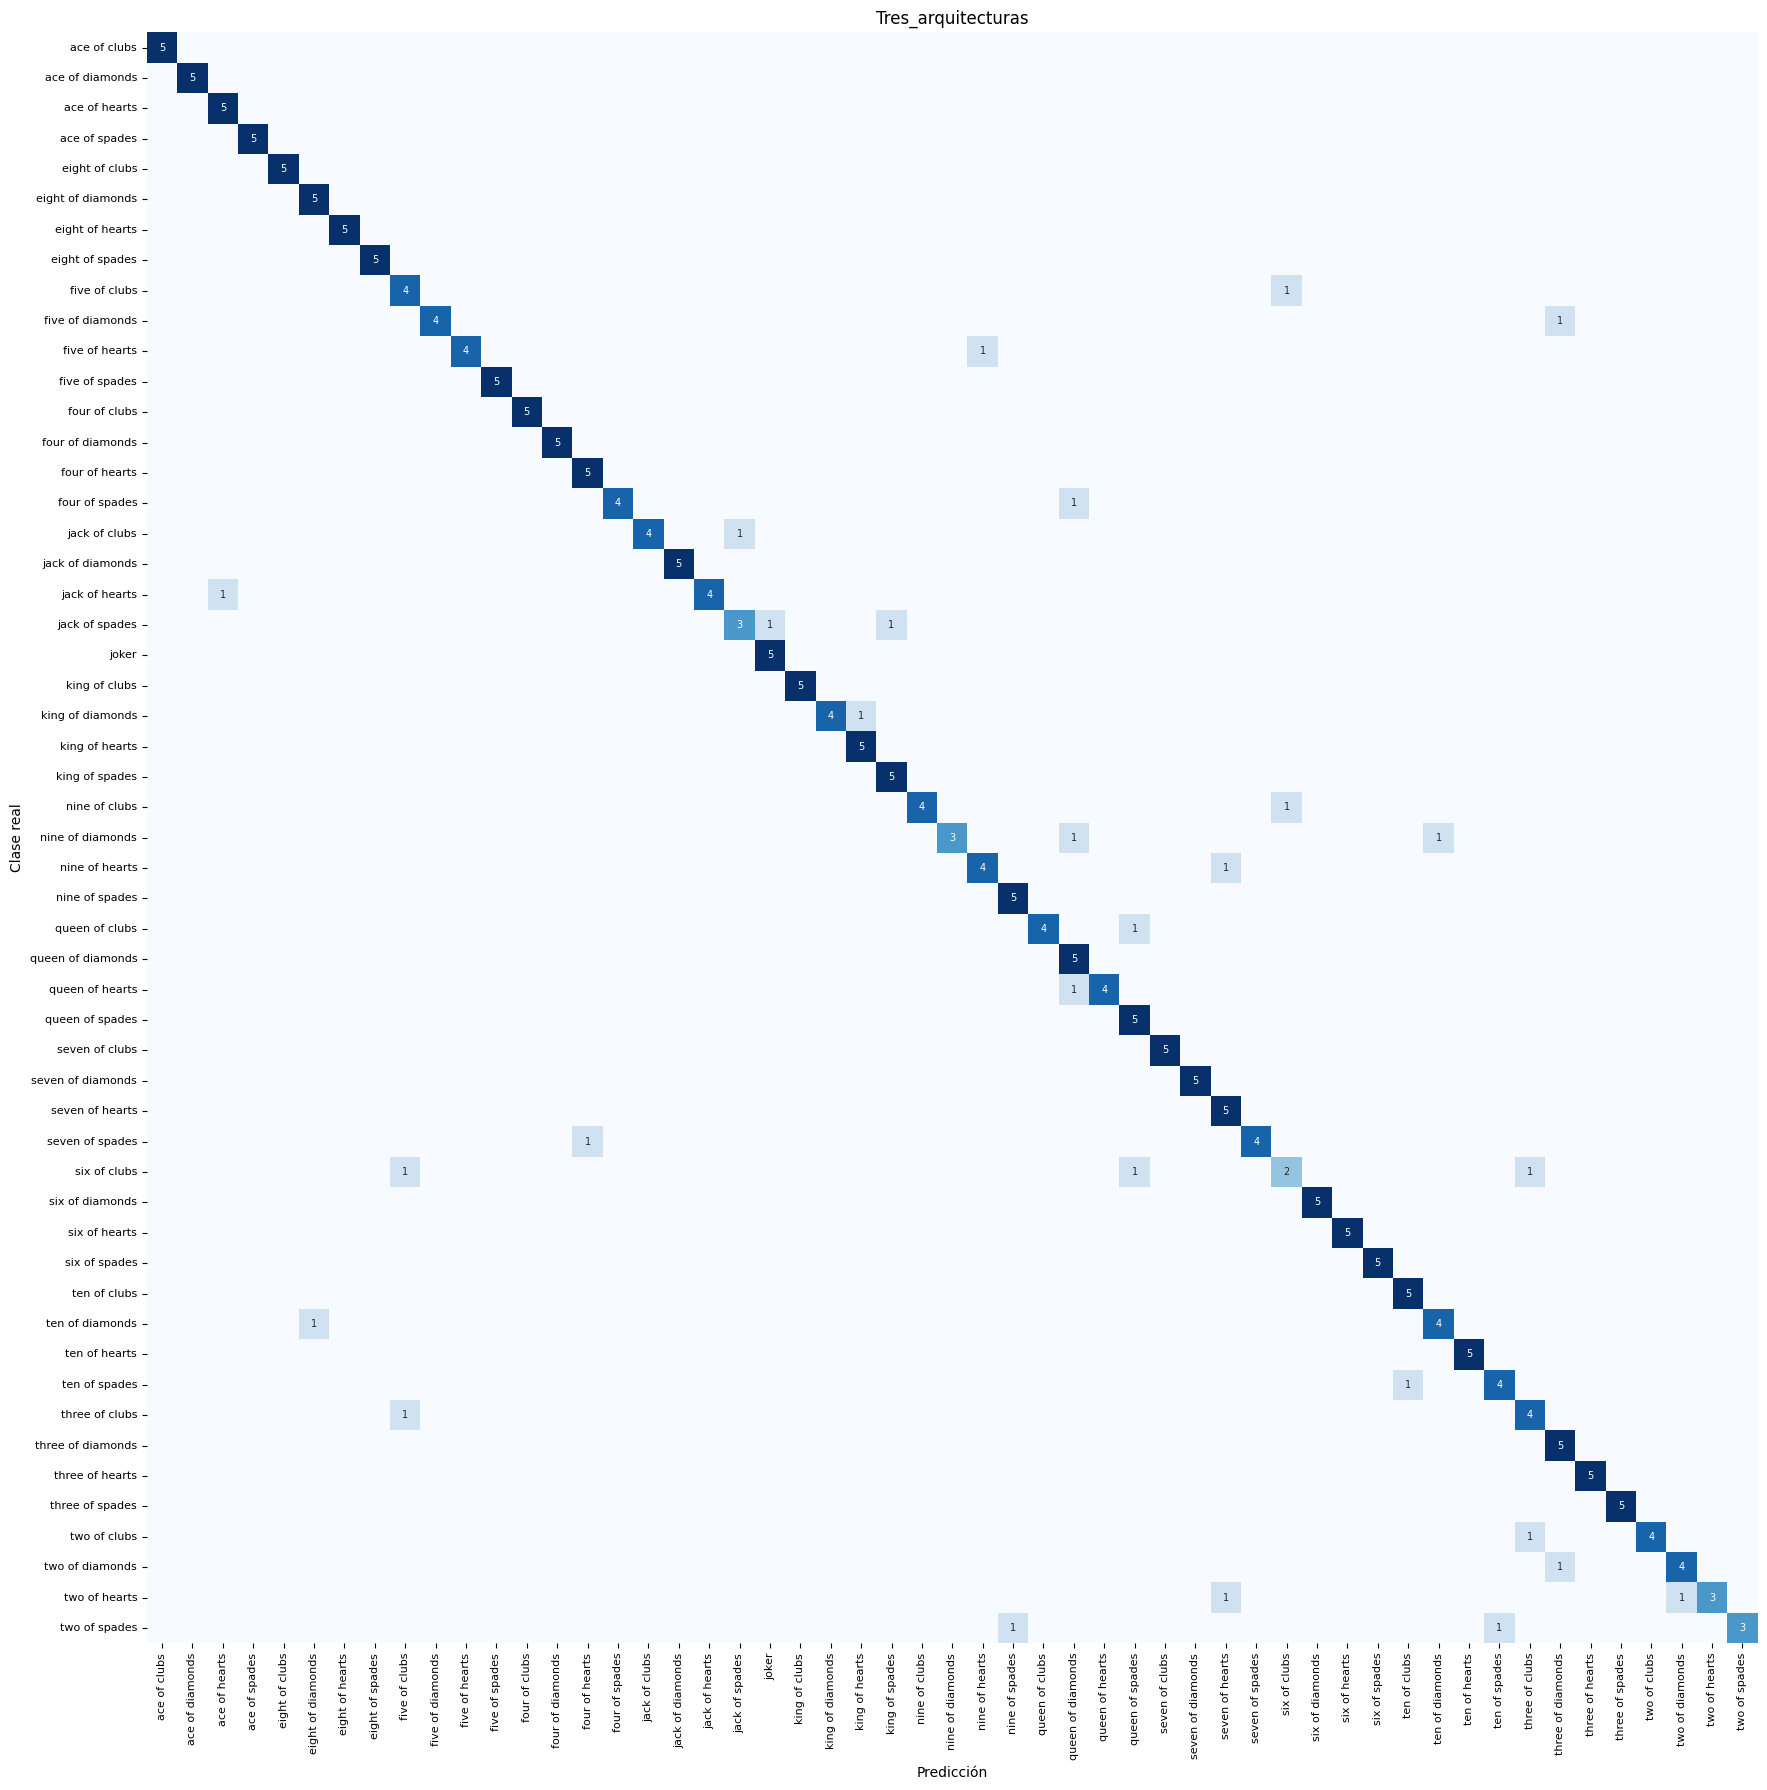

Todos los resultados guardados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Comparativa_Originales_Jokers/20261114_213020_894635


In [ ]:
P_TEST = {nombre: predecir_guardado(nombre, TEST) for nombre in RUTAS}
filas_test = []
for nombre, miembros in COMBINACIONES.items():
    p = np.mean([P_TEST[m] for m in miembros], axis=0)
    acc, loss = medir(p, etiquetas['test'])
    filas_test.append({'Modelo': nombre, 'Accuracy_test': acc, 'Loss_test': loss, 'Aciertos': int(np.sum(p.argmax(axis=1) == etiquetas['test']))})
tabla_test = pd.DataFrame(filas_test)
tabla_test.to_csv(SALIDA / 'comparacion_test.csv', index=False)
display(tabla_test.style.format({'Accuracy_test': '{:.2%}', 'Loss_test': '{:.4f}'}))
p_final = np.mean([P_TEST[m] for m in COMBINACIONES[GANADOR]], axis=0)
pred_final = p_final.argmax(axis=1)
y_test = etiquetas['test']
acc_final, _ = medir(p_final, y_test)
indice_joker = CLASES.index('joker')
mascara = y_test == indice_joker
print('\nGANADOR SELECCIONADO EN VALIDACIÓN:', GANADOR)
print(f'Accuracy test: {acc_final:.2%}')
print('Referencia actual: 87,92 % — 233/265')
print(f'Diferencia: {100 * (acc_final - 233 / 265):+.2f} puntos porcentuales')
print(f'Jokers: {np.sum(pred_final[mascara] == y_test[mascara])}/{mascara.sum()}')
reporte = classification_report(y_test, pred_final, labels=range(53), target_names=CLASES, digits=3, zero_division=0)
print(reporte)
(SALIDA / 'informe_ganador.txt').write_text(reporte)
matriz_final = confusion_matrix(y_test, pred_final, labels=range(53))
plt.figure(figsize=(20, 18))
sns.heatmap(matriz_final, annot=np.where(matriz_final > 0, matriz_final.astype(str), ''), fmt='', cmap='Blues', cbar=False, square=True, xticklabels=CLASES, yticklabels=CLASES, annot_kws={'size': 7})
plt.xlabel('Predicción')
plt.ylabel('Clase real')
plt.title(GANADOR)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA / 'matriz_ganador.png', dpi=150)
plt.show()
for nombre in RUTAS:
    np.savez_compressed(SALIDA / f'predicciones_{nombre}.npz', valid=P_VALID[nombre], test=P_TEST[nombre])
print('Todos los resultados guardados en:', SALIDA)


### 4.1. ¿Bastaba con entrenar más tiempo?

Las curvas y las últimas épocas muestran train cercano a 99 %, con validación alrededor de 82–84 % para ResNet y 85–88 % para EfficientNet. Alargar la misma receta no tenía una mejora clara asegurada: la separación train/valid justificaba revisar aumento de datos, regularización, capas entrenables y tasa de aprendizaje.

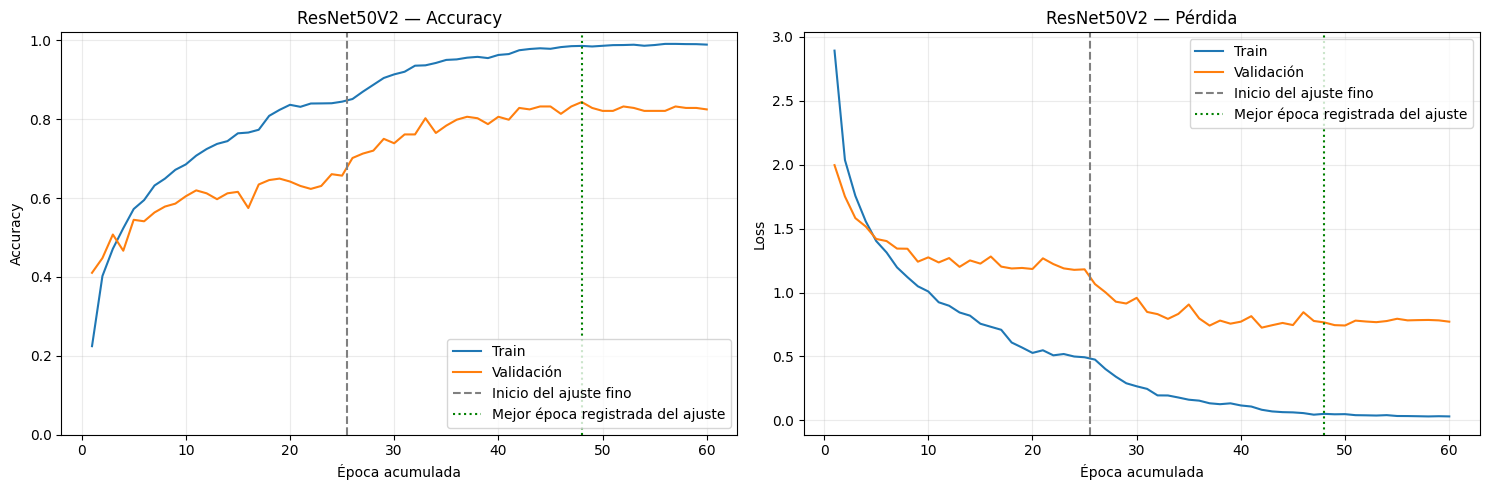

ResNet50V2: 35 épocas de ajuste fino; mejor registrada: 23; accuracy validación: 84.33%


,epoch,accuracy,val_accuracy,loss,val_loss
25,25,0.987559,0.820895,0.040630,0.780481
26,26,0.987821,0.832090,0.039474,0.773484
27,27,0.988607,0.828358,0.037714,0.768326
28,28,0.985987,0.820895,0.040832,0.777228
29,29,0.987821,0.820895,0.034109,0.795071
30,30,0.990702,0.820895,0.033592,0.782396
31,31,0.990702,0.832090,0.032284,0.784443
32,32,0.990178,0.828358,0.030720,0.785701
33,33,0.990047,0.828358,0.032436,0.782371
34,34,0.988869,0.824627,0.030882,0.772159


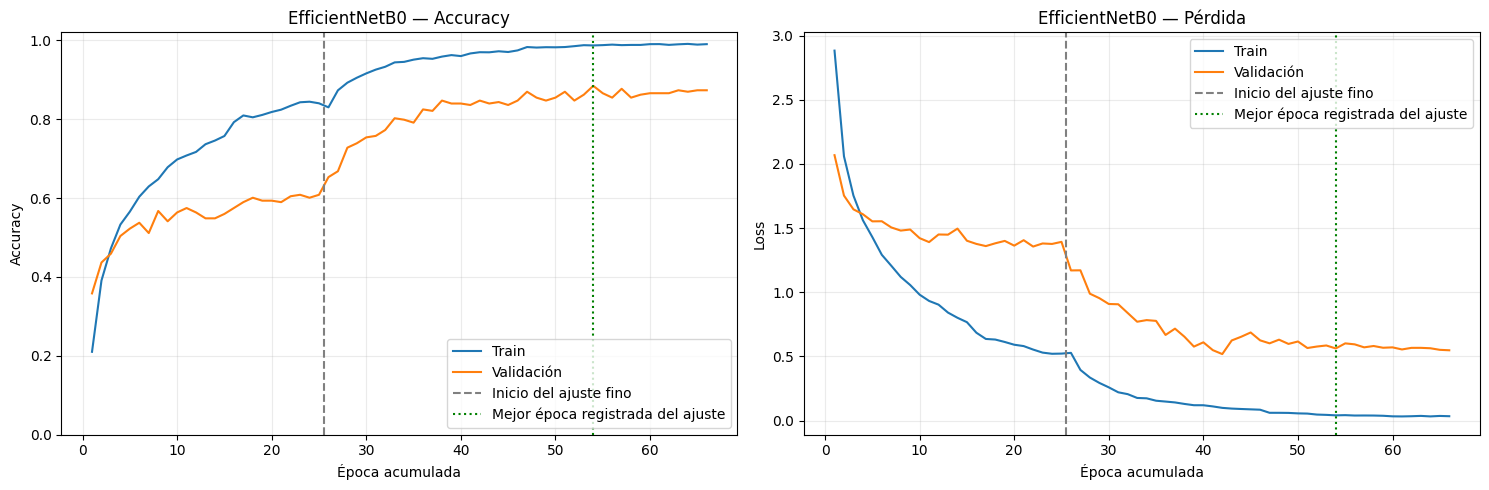

EfficientNetB0: 41 épocas de ajuste fino; mejor registrada: 29; accuracy validación: 88.43%


,epoch,accuracy,val_accuracy,loss,val_loss
31,31,0.987559,0.876866,0.039219,0.570191
32,32,0.988083,0.854478,0.038808,0.580677
33,33,0.988083,0.861940,0.037001,0.567055
34,34,0.990047,0.865672,0.032619,0.570022
35,35,0.990178,0.865672,0.031847,0.553800
36,36,0.988214,0.865672,0.033427,0.566165
37,37,0.989654,0.873134,0.036013,0.566297
38,38,0.990702,0.869403,0.032054,0.563130
39,39,0.988869,0.873134,0.035665,0.550846
40,40,0.990047,0.873134,0.033599,0.547319


In [ ]:
experimentos = {'ResNet50V2': ['ResNet50V2_cabeza', 'ResNet50V2_final'], 'EfficientNetB0': ['EfficientNetB0_cabeza', 'EfficientNetB0_final']}
for nombre, fases in experimentos.items():
    historiales = [pd.read_csv(SALIDA / f'{fase}.csv') for fase in fases]
    historial = pd.concat(historiales, ignore_index=True)
    epocas = range(1, len(historial) + 1)
    fin_cabeza = len(historiales[0])
    ajuste = historiales[1].reset_index(drop=True)
    mejor_indice = ajuste.sort_values(['val_accuracy', 'val_loss'], ascending=[False, True]).index[0]
    mejor_epoca = fin_cabeza + mejor_indice + 1
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    axes[0].plot(epocas, historial['accuracy'], label='Train')
    axes[0].plot(epocas, historial['val_accuracy'], label='Validación')
    axes[0].set_title(f'{nombre} — Accuracy')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_ylim(0, 1.02)
    axes[1].plot(epocas, historial['loss'], label='Train')
    axes[1].plot(epocas, historial['val_loss'], label='Validación')
    axes[1].set_title(f'{nombre} — Pérdida')
    axes[1].set_ylabel('Loss')
    for ax in axes:
        ax.axvline(fin_cabeza + 0.5, color='gray', linestyle='--', label='Inicio del ajuste fino')
        ax.axvline(mejor_epoca, color='green', linestyle=':', label='Mejor época registrada del ajuste')
        ax.set_xlabel('Época acumulada')
        ax.grid(alpha=0.25)
        ax.legend()
    plt.tight_layout()
    plt.show()
    print(f"{nombre}: {len(ajuste)} épocas de ajuste fino; mejor registrada: {mejor_indice + 1}; accuracy validación: {ajuste.loc[mejor_indice, 'val_accuracy']:.2%}")
    display(ajuste[['epoch', 'accuracy', 'val_accuracy', 'loss', 'val_loss']].tail(10))


## 5. Entrenamiento a 320: mejora del procedimiento completo

Se mantienen los originales+jokers, pero cambian conjuntamente la entrada a 320, la cabeza GAP → Dense256 → Dropout0,3, la mezcla completa de train, las transformaciones sin reflejos, el giro aleatorio 180°, el ajuste por bloques y BatchNormalization congelada. Se usan 15 épocas de cabeza y hasta 100 de ajuste fino, reducción de LR y parada anticipada.

**No se atribuye toda la mejora a 320:** las imágenes originales muestreadas son de 224 y ampliarlas no crea detalle nuevo. Puede cambiar cómo la red procesa los símbolos y las formas de las cartas, pero no podemos atribuir la mejora únicamente a ese tamaño, porque en esa etapa también cambiamos el entrenamiento, el aumento de datos, el dropout y las capas entrenables.

EfficientNetB0 semilla 2026 obtiene 95,52 % en validación y **95,85 % (254/265) en test**; la segunda semilla obtiene 92,83 % en test. ResNet llega a 91,70 %. La primera EfficientNet resulta elegida por validación, también frente a las combinaciones contrastadas. Se conserva su ejecución como referencia principal.

Se repite EfficientNet con semilla 2047, la arquitectura escogida en la ejecución histórica.

In [ ]:
liberar_modelos_y_datasets()
NOCHE = RESULTADOS / '05_Entrenamiento_320'
NOCHE.mkdir(parents=True, exist_ok=True)
SIZE_N, BATCH_N = (320, 32)
continuacion = Path(RUTAS['MobileNet_continuacion'])
MODELOS_N = {'MobileNet_continuacion': {'ruta': str(continuacion), 'size': 224, 'tipo': 'mobilenet'}, 'ResNet_anterior': {'ruta': RUTAS['ResNet50V2'], 'size': 224, 'tipo': 'resnet'}, 'EfficientNet_anterior': {'ruta': RUTAS['EfficientNetB0'], 'size': 224, 'tipo': 'efficientnet'}}
DATOS_N = preparar_jokers()
CLASES_N = CLASES_CARTAS
X_N, Y_N = (RUTAS_CARTAS, ETIQUETAS_CARTAS)
(NOCHE / 'clases.json').write_text(json.dumps(CLASES_N, indent=2))
for split, tabla in MANIFIESTOS.items():
    tabla.to_csv(NOCHE / f'particion_{split}.csv', index=False)
print('Datos: 7636 train / 268 valid / 265 test. Resultados:', NOCHE)

CACHE_N = {}

def dataset_n(split, size):
    clave = (split, size)
    if clave not in CACHE_N:

        def leer(p):
            with Image.open(p.numpy().decode()) as im:
                metodo = Image.Resampling.NEAREST if size == 224 else Image.Resampling.BILINEAR
                return np.asarray(im.convert('RGB').resize((size, size), metodo), dtype=np.uint8)

        def decodificar(p, y):
            x = tf.py_function(leer, [p], Tout=tf.uint8)
            x.set_shape((size, size, 3))
            return (x, tf.one_hot(y, 53))
        ds = tf.data.Dataset.from_tensor_slices((X_N[split], Y_N[split]))
        CACHE_N[clave] = ds.map(decodificar, num_parallel_calls=tf.data.AUTOTUNE).cache()
    return CACHE_N[clave]

def train_n(seed):
    ds = dataset_n('train', SIZE_N).shuffle(7636, seed=seed, reshuffle_each_iteration=True).batch(BATCH_N)

    def giro_180(x, y):
        mascara = tf.random.uniform([tf.shape(x)[0], 1, 1, 1], seed=seed + 17) < 0.5
        return (tf.where(mascara, tf.reverse(x, axis=[1, 2]), x), y)
    return ds.map(giro_180, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
VALID_N = dataset_n('valid', SIZE_N).batch(BATCH_N).prefetch(tf.data.AUTOTUNE)

class MejorNoche(tf.keras.callbacks.Callback):

    def __init__(self, ruta, loss, acc):
        super().__init__()
        self.ruta, self.loss, self.acc = (str(ruta), float(loss), float(acc))

    def on_epoch_end(self, epoch, logs=None):
        a, l = (float(logs['val_accuracy']), float(logs['val_loss']))
        if a > self.acc + 1e-08 or (abs(a - self.acc) <= 1e-08 and l < self.loss):
            self.acc, self.loss = (a, l)
            self.model.save(self.ruta)
            print(f'  Guardado: valid={a:.2%}, loss={l:.4f}', flush=True)

def fase_n(modelo, train, nombre, fase, epochs, lr):
    ruta = NOCHE / f'{nombre}_{fase}.keras'
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    loss, acc = modelo.evaluate(VALID_N, verbose=0)
    modelo.save(str(ruta))
    modelo.fit(train, validation_data=VALID_N, epochs=epochs, verbose=2, callbacks=[MejorNoche(ruta, loss, acc), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-07, verbose=1), tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, min_delta=0.0001, verbose=1), tf.keras.callbacks.CSVLogger(str(NOCHE / f'{nombre}_{fase}.csv')), tf.keras.callbacks.TerminateOnNaN()])
    modelo.load_weights(str(ruta))
    return str(ruta)

def ejecutar_n(tipo, nombre, seed):
    gc.collect()
    tf.keras.utils.set_random_seed(seed)
    constructor = tf.keras.applications.EfficientNetB0 if tipo == 'efficientnet' else tf.keras.applications.ResNet50V2
    base = constructor(include_top=False, weights='imagenet', input_shape=(SIZE_N, SIZE_N, 3))
    base.trainable = False
    entrada = tf.keras.Input((SIZE_N, SIZE_N, 3), name='rgb_0_255')
    x = tf.keras.layers.RandomRotation(15 / 360, fill_mode='reflect', seed=seed)(entrada)
    x = tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode='reflect', seed=seed + 1)(x)
    x = tf.keras.layers.RandomZoom(0.1, fill_mode='reflect', seed=seed + 2)(x)
    x = tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255), seed=seed + 3)(x)
    if tipo == 'resnet':
        x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    pred = tf.keras.layers.Dense(53, activation='softmax')(x)
    modelo = tf.keras.Model(entrada, pred, name=nombre)
    train = train_n(seed)
    print(f'\n{nombre}: FASE 1, clasificador; maximo 15 epocas.', flush=True)
    fase_n(modelo, train, nombre, 'cabeza', 15, 0.001)
    base.trainable = True
    for capa in base.layers:
        bloque = capa.name.startswith(('block6', 'block7', 'top_')) if tipo == 'efficientnet' else capa.name.startswith('conv5_')
        capa.trainable = bloque and (not isinstance(capa, tf.keras.layers.BatchNormalization))
    assert len(base.trainable_weights) > 0
    print(f'\n{nombre}: FASE 2, ajuste fino; maximo 100 epocas.', flush=True)
    lr = 0.0001 if tipo == 'efficientnet' else 3e-05
    ruta = fase_n(modelo, train, nombre, 'final', 100, lr)
    loss, acc = modelo.evaluate(VALID_N, verbose=0)
    MODELOS_N[nombre] = {'ruta': ruta, 'size': SIZE_N, 'tipo': tipo, 'seed': seed, 'val_accuracy': float(acc), 'val_loss': float(loss)}
    (NOCHE / 'modelos.json').write_text(json.dumps(MODELOS_N, indent=2))
    print(f'FINALIZADO {nombre}: valid={acc:.2%}; loss={loss:.4f}', flush=True)
    del modelo, base, train
    gc.collect()
    return (float(acc), float(loss))
print('Funciones listas. Las siguientes tres celdas entrenan secuencialmente.')


Modelos anteriores recuperados: {'MobileNet_continuacion': '/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Comparativa_Originales_Jokers/20261114_213020_894635/MobileNet_continuacion.keras', 'ResNet_anterior': '/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Comparativa_Originales_Jokers/20261114_213020_894635/ResNet50V2_final.keras', 'EfficientNet_anterior': '/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Comparativa_Originales_Jokers/20261114_213020_894635/EfficientNetB0_final.keras'}
Tamanos originales muestreados: [(224, 224)]
AVISO: 320 es una ampliacion; no crea informacion nueva en estos originales.
Train: 7636; valid: 268; test: 265. Resultados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Entrenamientos_Noche_320/20261114_223409_206691


Funciones listas. Las siguientes tres celdas entrenan secuencialmente.


In [ ]:
resultado_e = ejecutar_n('efficientnet', 'EfficientNetB0_320_s2026', seed=2026)



EfficientNetB0_320_s2026: FASE 1, clasificador; maximo 15 epocas.
Epoch 1/15
  Guardado: valid=38.43%, loss=1.9052
239/239 - 46s - 191ms/step - accuracy: 0.2093 - loss: 2.7804 - val_accuracy: 0.3843 - val_loss: 1.9052 - learning_rate: 0.0010
Epoch 2/15
  Guardado: valid=51.12%, loss=1.5741
239/239 - 23s - 97ms/step - accuracy: 0.3738 - loss: 2.0417 - val_accuracy: 0.5112 - val_loss: 1.5741 - learning_rate: 0.0010
Epoch 3/15
239/239 - 23s - 94ms/step - accuracy: 0.4646 - loss: 1.7521 - val_accuracy: 0.5000 - val_loss: 1.4631 - learning_rate: 0.0010
Epoch 4/15
  Guardado: valid=54.85%, loss=1.3947
239/239 - 23s - 97ms/step - accuracy: 0.5085 - loss: 1.5845 - val_accuracy: 0.5485 - val_loss: 1.3947 - learning_rate: 0.0010
Epoch 5/15
  Guardado: valid=57.84%, loss=1.2743
239/239 - 23s - 97ms/step - accuracy: 0.5401 - loss: 1.4625 - val_accuracy: 0.5784 - val_loss: 1.2743 - learning_rate: 0.0010
Epoch 6/15
  Guardado: valid=60.45%, loss=1.2573
239/239 - 23s - 97ms/step - accuracy: 0.5661 -

In [ ]:
resultado_r = ejecutar_n('resnet', 'ResNet50V2_320_s2026', seed=2026)



ResNet50V2_320_s2026: FASE 1, clasificador; maximo 15 epocas.
Epoch 1/15
  Guardado: valid=38.81%, loss=1.9686
239/239 - 35s - 145ms/step - accuracy: 0.2148 - loss: 2.8617 - val_accuracy: 0.3881 - val_loss: 1.9686 - learning_rate: 0.0010
Epoch 2/15
  Guardado: valid=46.64%, loss=1.6727
239/239 - 28s - 119ms/step - accuracy: 0.3749 - loss: 2.0820 - val_accuracy: 0.4664 - val_loss: 1.6727 - learning_rate: 0.0010
Epoch 3/15
  Guardado: valid=52.99%, loss=1.5131
239/239 - 28s - 118ms/step - accuracy: 0.4530 - loss: 1.7953 - val_accuracy: 0.5299 - val_loss: 1.5131 - learning_rate: 0.0010
Epoch 4/15
  Guardado: valid=53.36%, loss=1.3904
239/239 - 28s - 118ms/step - accuracy: 0.5021 - loss: 1.6358 - val_accuracy: 0.5336 - val_loss: 1.3904 - learning_rate: 0.0010
Epoch 5/15
  Guardado: valid=58.96%, loss=1.3375
239/239 - 28s - 119ms/step - accuracy: 0.5360 - loss: 1.4981 - val_accuracy: 0.5896 - val_loss: 1.3375 - learning_rate: 0.0010
Epoch 6/15
239/239 - 28s - 115ms/step - accuracy: 0.5606 

In [ ]:
tipo_repetir, nombre_repetir = ('efficientnet', 'EfficientNetB0_320_s2047')
print('Repetición de EfficientNet con segunda semilla:', nombre_repetir)
resultado_repeticion = ejecutar_n(tipo_repetir, nombre_repetir, seed=2047)


Se repetira desde ImageNet con otra semilla: EfficientNetB0_320_s2047

EfficientNetB0_320_s2047: FASE 1, clasificador; maximo 15 epocas.
Epoch 1/15
  Guardado: valid=35.82%, loss=1.9093
239/239 - 32s - 134ms/step - accuracy: 0.2199 - loss: 2.7803 - val_accuracy: 0.3582 - val_loss: 1.9093 - learning_rate: 0.0010
Epoch 2/15
  Guardado: valid=45.15%, loss=1.6219
239/239 - 23s - 97ms/step - accuracy: 0.3760 - loss: 2.0243 - val_accuracy: 0.4515 - val_loss: 1.6219 - learning_rate: 0.0010
Epoch 3/15
  Guardado: valid=50.75%, loss=1.4466
239/239 - 23s - 97ms/step - accuracy: 0.4573 - loss: 1.7363 - val_accuracy: 0.5075 - val_loss: 1.4466 - learning_rate: 0.0010
Epoch 4/15
  Guardado: valid=54.85%, loss=1.3486
239/239 - 23s - 96ms/step - accuracy: 0.5089 - loss: 1.5653 - val_accuracy: 0.5485 - val_loss: 1.3486 - learning_rate: 0.0010
Epoch 5/15
  Guardado: valid=56.34%, loss=1.3091
239/239 - 23s - 97ms/step - accuracy: 0.5543 - loss: 1.4312 - val_accuracy: 0.5634 - val_loss: 1.3091 - learning_

In [ ]:
def predecir_n(nombre, split):
    info = MODELOS_N[nombre]
    modelo = tf.keras.models.load_model(info['ruta'], compile=False)
    ds = dataset_n(split, info['size']).batch(BATCH_N).prefetch(tf.data.AUTOTUNE)
    p = modelo.predict(ds, verbose=0)
    assert p.shape == (len(Y_N[split]), 53)
    del modelo
    gc.collect()
    return p

def metricas_n(p, y):
    return (float(np.mean(p.argmax(axis=1) == y)), float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-07, 1)).mean()))
PV_N = {n: predecir_n(n, 'valid') for n in MODELOS_N}

def mejor_tipo_n(tipo):
    candidatos = [n for n, info in MODELOS_N.items() if info['tipo'] == tipo]
    return max(candidatos, key=lambda n: (metricas_n(PV_N[n], Y_N['valid'])[0], -metricas_n(PV_N[n], Y_N['valid'])[1]))
mejor_r, mejor_e = (mejor_tipo_n('resnet'), mejor_tipo_n('efficientnet'))
movil = 'MobileNet_continuacion'
COMB_N = {n: [n] for n in MODELOS_N}
for n in MODELOS_N:
    if n != movil:
        COMB_N['MobileNet_mas_' + n] = [movil, n]
COMB_N['Mejores_ResNet_EfficientNet'] = [mejor_r, mejor_e]
COMB_N['Mejores_tres_arquitecturas'] = [movil, mejor_r, mejor_e]
if 'ResNet_anterior' in MODELOS_N and 'EfficientNet_anterior' in MODELOS_N:
    COMB_N['Tres_arquitecturas_anteriores'] = [movil, 'ResNet_anterior', 'EfficientNet_anterior']
filas = []
for nombre, miembros in COMB_N.items():
    p = np.mean([PV_N[m] for m in miembros], axis=0)
    acc, loss = metricas_n(p, Y_N['valid'])
    filas.append({'Modelo': nombre, 'Accuracy_valid': acc, 'Loss_valid': loss})
VALIDACION_N = pd.DataFrame(filas).sort_values(['Accuracy_valid', 'Loss_valid'], ascending=[False, True])
GANADOR_N = VALIDACION_N.iloc[0]['Modelo']
VALIDACION_N.to_csv(NOCHE / 'validacion.csv', index=False)
(NOCHE / 'seleccion.json').write_text(json.dumps({'ganador': GANADOR_N, 'miembros': COMB_N[GANADOR_N], 'combinaciones': COMB_N, 'modelos': MODELOS_N}, indent=2))
display(VALIDACION_N.style.format({'Accuracy_valid': '{:.2%}', 'Loss_valid': '{:.4f}'}))
print('GANADOR SELECCIONADO EN VALIDACION:', GANADOR_N)


,Modelo,Accuracy_valid,Loss_valid
3,EfficientNetB0_320_s2026,95.52%,0.1995
12,Mejores_tres_arquitecturas,95.52%,0.2074
11,Mejores_ResNet_EfficientNet,95.52%,0.2079
5,EfficientNetB0_320_s2047,95.15%,0.2271
10,MobileNet_mas_EfficientNetB0_320_s2047,94.78%,0.2048
8,MobileNet_mas_EfficientNetB0_320_s2026,94.40%,0.2148
9,MobileNet_mas_ResNet50V2_320_s2026,94.03%,0.2912
4,ResNet50V2_320_s2026,93.66%,0.3148
13,Tres_arquitecturas_anteriores,92.16%,0.3192
6,MobileNet_mas_ResNet_anterior,91.79%,0.4087


GANADOR SELECCIONADO EN VALIDACION: EfficientNetB0_320_s2026


,Modelo,Accuracy_test,Loss_test,Aciertos
0,MobileNet_continuacion,90.19%,0.5164,239
1,ResNet_anterior,77.74%,1.0768,206
2,EfficientNet_anterior,86.04%,0.4982,228
3,EfficientNetB0_320_s2026,95.85%,0.2234,254
4,ResNet50V2_320_s2026,91.70%,0.4224,243
5,EfficientNetB0_320_s2047,92.83%,0.2970,246
6,MobileNet_mas_ResNet_anterior,90.94%,0.4887,241
7,MobileNet_mas_EfficientNet_anterior,89.43%,0.3179,237
8,MobileNet_mas_EfficientNetB0_320_s2026,93.58%,0.2122,248
9,MobileNet_mas_ResNet50V2_320_s2026,91.32%,0.2932,242



GANADOR ELEGIDO EN VALIDACION: EfficientNetB0_320_s2026
Test: 95.85% (254/265); loss=0.2234
Referencia historica del mejor conjunto: 90.94% (241/265).
Diferencia: +4.91 puntos porcentuales
Jokers: 5/5
                   precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      1.000     1.000     1.000         5
    ace of hearts      1.000     1.000     1.000         5
    ace of spades      0.833     1.000     0.909         5
   eight of clubs      1.000     1.000     1.000         5
eight of diamonds      1.000     1.000     1.000         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      1.000     1.000     1.000         5
    five of clubs      1.000     0.800     0.889         5
 five of diamonds      1.000     1.000     1.000         5
   five of hearts      1.000     1.000     1.000         5
   five of spades      1.000     1.000     1.000         5
    four of clubs      1.000  

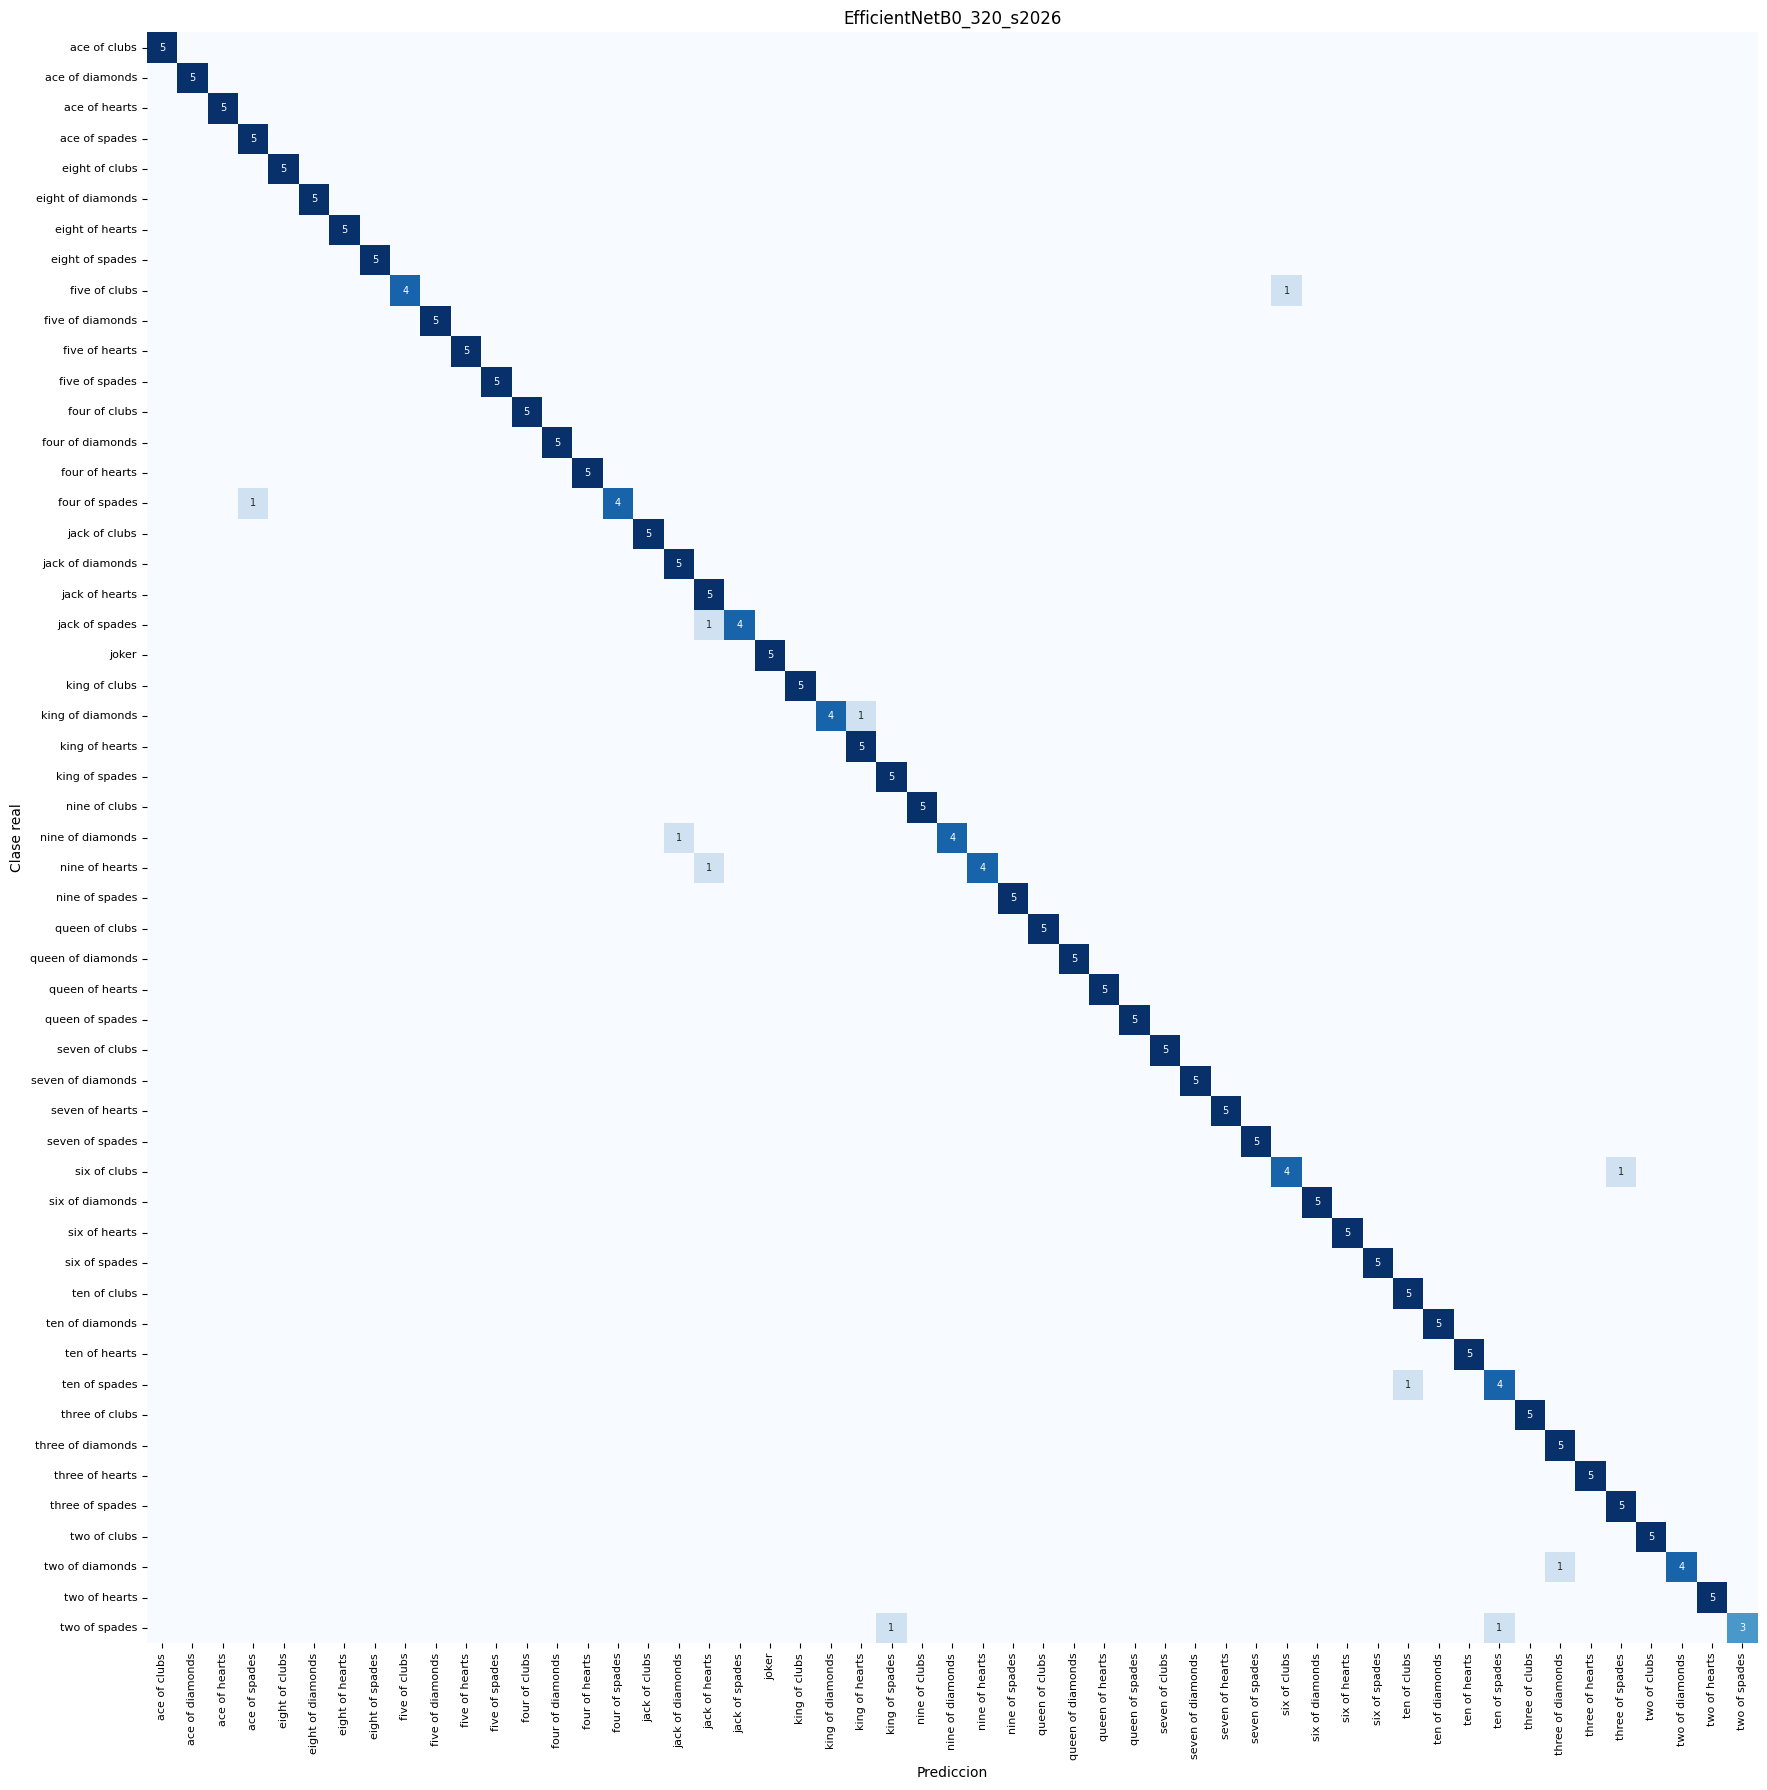

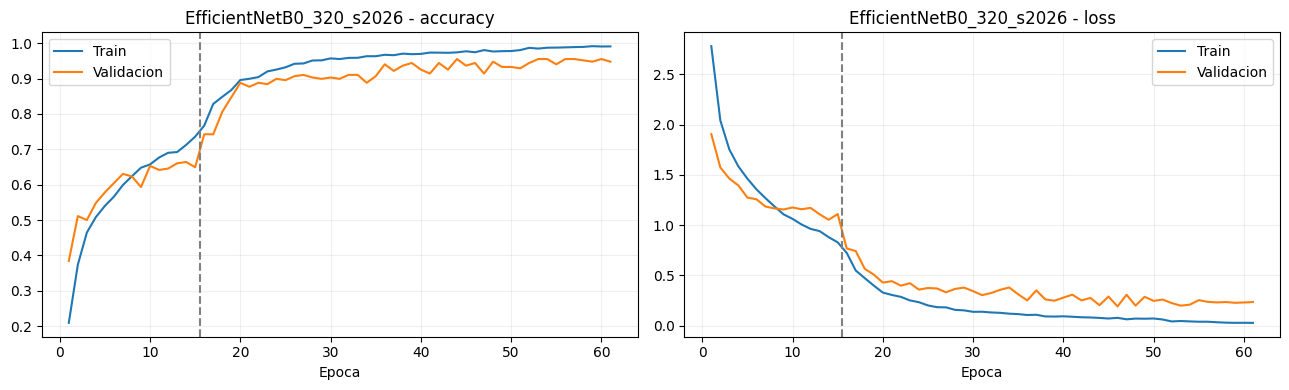

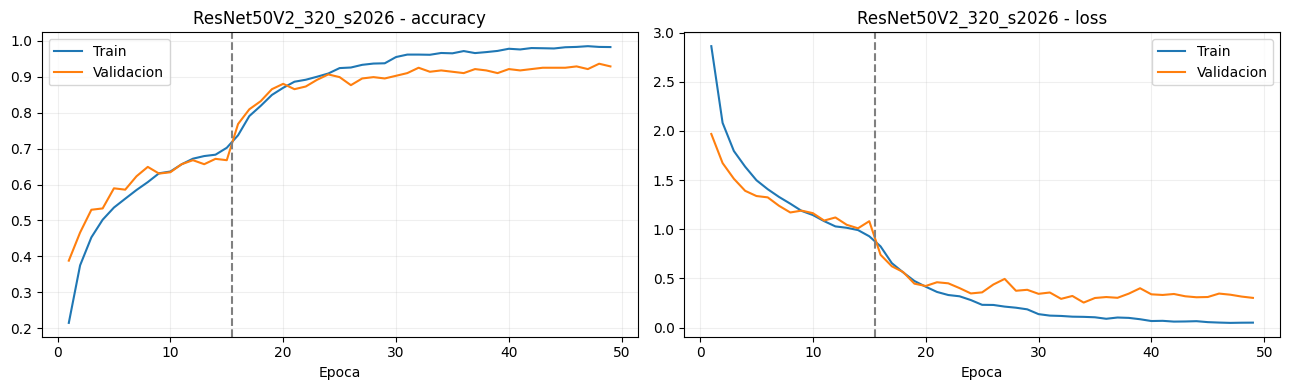

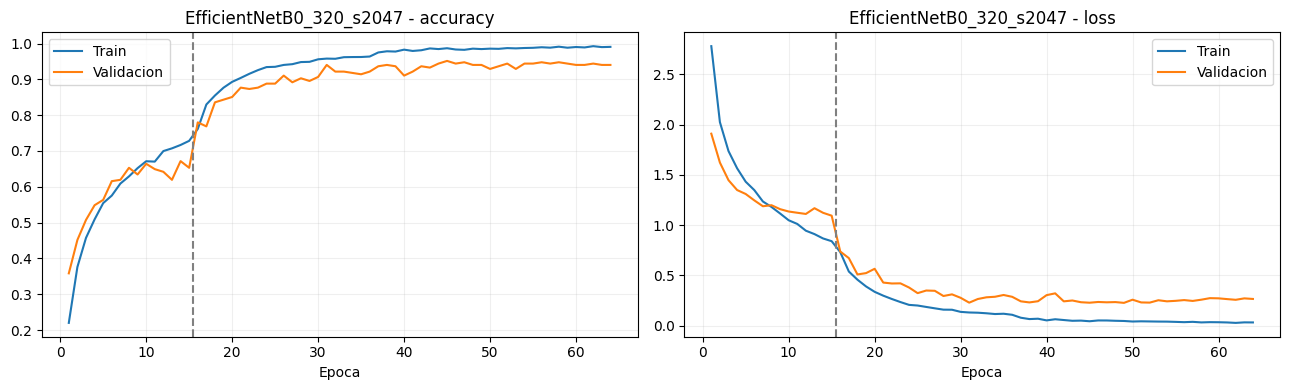

TODO TERMINADO. Modelos, predicciones e informes en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Entrenamientos_Noche_320/20261114_223409_206691


In [ ]:
PT_N = {n: predecir_n(n, 'test') for n in MODELOS_N}
filas = []
for nombre, miembros in COMB_N.items():
    p = np.mean([PT_N[m] for m in miembros], axis=0)
    acc, loss = metricas_n(p, Y_N['test'])
    filas.append({'Modelo': nombre, 'Accuracy_test': acc, 'Loss_test': loss, 'Aciertos': int(np.sum(p.argmax(axis=1) == Y_N['test']))})
TEST_N = pd.DataFrame(filas)
TEST_N.to_csv(NOCHE / 'test.csv', index=False)
display(TEST_N.style.format({'Accuracy_test': '{:.2%}', 'Loss_test': '{:.4f}'}))
p = np.mean([PT_N[m] for m in COMB_N[GANADOR_N]], axis=0)
pred = p.argmax(axis=1)
y = Y_N['test']
acc, loss = metricas_n(p, y)
es_joker = y == CLASES_N.index('joker')
print('\nGANADOR ELEGIDO EN VALIDACION:', GANADOR_N)
print(f'Test: {acc:.2%} ({np.sum(pred == y)}/265); loss={loss:.4f}')
print(f'Referencia historica del mejor conjunto: {241 / 265:.2%} (241/265).')
print(f'Diferencia: {100 * (acc - 241 / 265):+.2f} puntos porcentuales')
print(f'Jokers: {np.sum(pred[es_joker] == y[es_joker])}/{es_joker.sum()}')
reporte = classification_report(y, pred, labels=range(53), target_names=CLASES_N, digits=3, zero_division=0)
print(reporte)
(NOCHE / 'informe_ganador.txt').write_text(reporte)
matriz = confusion_matrix(y, pred, labels=range(53))
plt.figure(figsize=(20, 18))
sns.heatmap(matriz, annot=np.where(matriz > 0, matriz.astype(str), ''), fmt='', cmap='Blues', cbar=False, square=True, xticklabels=CLASES_N, yticklabels=CLASES_N, annot_kws={'size': 7})
plt.xlabel('Prediccion')
plt.ylabel('Clase real')
plt.title(GANADOR_N)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(NOCHE / 'matriz_ganador.png', dpi=150)
plt.show()
for n in MODELOS_N:
    np.savez_compressed(NOCHE / f'predicciones_{n}.npz', valid=PV_N[n], test=PT_N[n])
for nombre in ['EfficientNetB0_320_s2026', 'ResNet50V2_320_s2026', nombre_repetir]:
    a = pd.read_csv(NOCHE / f'{nombre}_cabeza.csv')
    b = pd.read_csv(NOCHE / f'{nombre}_final.csv')
    h = pd.concat([a, b], ignore_index=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metrica in zip(axes, ['accuracy', 'loss']):
        ax.plot(np.arange(1, len(h) + 1), h[metrica], label='Train')
        ax.plot(np.arange(1, len(h) + 1), h['val_' + metrica], label='Validacion')
        ax.axvline(len(a) + 0.5, color='gray', linestyle='--')
        ax.set_title(nombre + ' - ' + metrica)
        ax.set_xlabel('Epoca')
        ax.grid(alpha=0.2)
        ax.legend()
    fig.tight_layout()
    fig.savefig(NOCHE / f'curvas_{nombre}.png', dpi=150)
    plt.show()
print('TODO TERMINADO. Modelos, predicciones e informes en:', NOCHE)


## 6. Combinación de semillas y primer TTA

Se utilizan directamente las probabilidades de las dos EfficientNet calculadas en la etapa anterior. Validación elige75/25; el test mantiene95,85 %. El promedio entre vista original y giro180° eleva después el test a 96,23 %. No hay entrenamiento adicional en esta parte.

In [ ]:
liberar_modelos_y_datasets()
CARPETA = NOCHE
MODELO_A = 'EfficientNetB0_320_s2026'
MODELO_B = 'EfficientNetB0_320_s2047'
clases = CLASES_CARTAS
part_valid, part_test = (MANIFIESTOS['valid'], MANIFIESTOS['test'])
y_valid, y_test = (ETIQUETAS_CARTAS['valid'], ETIQUETAS_CARTAS['test'])
a_valid, a_test = (PV_N[MODELO_A].astype(np.float64), PT_N[MODELO_A].astype(np.float64))
b_valid, b_test = (PV_N[MODELO_B].astype(np.float64), PT_N[MODELO_B].astype(np.float64))
SALIDA = RESULTADOS / '06_Combinacion_Dos_EfficientNet'
SALIDA.mkdir(parents=True, exist_ok=True)
print('Se reutilizan las probabilidades calculadas en la etapa anterior.')

def metricas_probabilidades(y, probabilidades):
    pred = probabilidades.argmax(axis=1)
    aciertos = int(np.sum(pred == y))
    loss = float(-np.log(np.clip(probabilidades[np.arange(len(y)), y], 1e-12, 1.0)).mean())
    return {'accuracy': aciertos / len(y), 'loss': loss, 'aciertos': aciertos}
candidatos = {'EfficientNet_A': 1.0, 'A_75_B_25': 0.75, 'A_50_B_50': 0.5, 'A_25_B_75': 0.25, 'EfficientNet_B': 0.0}
filas = []
for nombre, peso_a in candidatos.items():
    probabilidades = peso_a * a_valid + (1 - peso_a) * b_valid
    filas.append({'modelo': nombre, 'peso_A': peso_a, 'peso_B': 1 - peso_a, **metricas_probabilidades(y_valid, probabilidades)})
tabla_valid = pd.DataFrame(filas).sort_values(['accuracy', 'loss'], ascending=[False, True], kind='stable').reset_index(drop=True)
elegido = tabla_valid.iloc[0]['modelo']
peso_a_elegido = float(candidatos[elegido])
display(tabla_valid.style.format({'accuracy': '{:.2%}', 'loss': '{:.4f}', 'peso_A': '{:.0%}', 'peso_B': '{:.0%}'}))
print(f'SELECCIONADO EN VALIDACIÓN: {elegido}')
print(f'Peso A: {peso_a_elegido:.0%}')
print(f'Peso B: {1 - peso_a_elegido:.0%}')
tabla_valid.to_csv(SALIDA / 'validacion.csv', index=False)
(SALIDA / 'seleccion.json').write_text(json.dumps({'elegido_en_validacion': elegido, 'modelo_A': MODELO_A, 'modelo_B': MODELO_B, 'peso_A': peso_a_elegido, 'peso_B': 1 - peso_a_elegido, 'carpeta_origen': str(CARPETA)}, indent=2), encoding='utf-8')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Predicciones cargadas. No se ha entrenado ningún modelo.
Validación: 268 imágenes.
Test original guardado: 265 imágenes, 5 por clase.


,modelo,peso_A,peso_B,accuracy,loss,aciertos
0,A_75_B_25,75%,25%,95.90%,0.1715,257
1,A_50_B_50,50%,50%,95.90%,0.1733,257
2,EfficientNet_A,100%,0%,95.52%,0.1995,256
3,A_25_B_75,25%,75%,95.15%,0.1844,255
4,EfficientNet_B,0%,100%,95.15%,0.2271,255


SELECCIONADO EN VALIDACIÓN: A_75_B_25
Peso A: 75%
Peso B: 25%


297

In [ ]:
filas = []
for nombre, peso_a in candidatos.items():
    probabilidades = peso_a * a_test + (1 - peso_a) * b_test
    filas.append({'modelo': nombre, 'seleccionado_en_validacion': nombre == elegido, **metricas_probabilidades(y_test, probabilidades)})
tabla_test = pd.DataFrame(filas)
referencia = metricas_probabilidades(y_test, a_test)
tabla_test['diferencia_pp_vs_A'] = (tabla_test['accuracy'] - referencia['accuracy']) * 100
display(tabla_test.style.format({'accuracy': '{:.2%}', 'loss': '{:.4f}', 'diferencia_pp_vs_A': '{:+.2f}'}))
p_elegido = peso_a_elegido * a_test + (1 - peso_a_elegido) * b_test
pred_elegido = p_elegido.argmax(axis=1)
resultado = metricas_probabilidades(y_test, p_elegido)
diferencia = resultado['aciertos'] - referencia['aciertos']
print(f'\nOPCIÓN ELEGIDA CON VALIDACIÓN: {elegido}')
print(f"EfficientNet A: {referencia['accuracy']:.2%} — {referencia['aciertos']}/{len(y_test)}")
print(f"Opción elegida: {resultado['accuracy']:.2%} — {resultado['aciertos']}/{len(y_test)}")
print(f"Diferencia: {100 * (resultado['accuracy'] - referencia['accuracy']):+.2f} puntos")
print(f'Cambio en aciertos: {diferencia:+d}')
if diferencia > 0:
    print('La opción seleccionada mejora el accuracy en este test.')
elif diferencia == 0:
    print('La opción seleccionada iguala el accuracy de A.')
else:
    print('La opción seleccionada no mejora a A en este test.')
tabla_test.to_csv(SALIDA / 'test.csv', index=False)
np.savez_compressed(SALIDA / 'predicciones_seleccionadas.npz', probabilidades=p_elegido, etiquetas=y_test, imagenes=part_test['imagen'].astype(str).to_numpy(dtype=str), clases=np.asarray(clases, dtype=str))


,modelo,seleccionado_en_validacion,accuracy,loss,aciertos,diferencia_pp_vs_A
0,EfficientNet_A,False,95.85%,0.2234,254,+0.00
1,A_75_B_25,True,95.85%,0.2061,254,+0.00
2,A_50_B_50,False,95.09%,0.2120,252,-0.75
3,A_25_B_75,False,92.83%,0.2289,246,-3.02
4,EfficientNet_B,False,92.83%,0.2970,246,-3.02



OPCIÓN ELEGIDA CON VALIDACIÓN: A_75_B_25
EfficientNet A: 95.85% — 254/265
Opción elegida: 95.85% — 254/265
Diferencia: +0.00 puntos
Cambio en aciertos: +0
La opción seleccionada iguala el accuracy de A.


In [ ]:
informe = classification_report(y_test, pred_elegido, labels=np.arange(len(clases)), target_names=clases, digits=3, zero_division=0)
print(informe)
indice_joker = clases.index('joker')
jokers_reales = y_test == indice_joker
jokers_correctos = int(np.sum(jokers_reales & (pred_elegido == indice_joker)))
falsos_jokers = int(np.sum(~jokers_reales & (pred_elegido == indice_joker)))
print(f'Jokers reconocidos: {jokers_correctos}/{jokers_reales.sum()}')
print(f'Cartas confundidas con joker: {falsos_jokers}')
nombres = np.asarray(clases)
errores = pd.DataFrame({'imagen': part_test['imagen'].to_numpy(), 'clase_real': nombres[y_test], 'prediccion': nombres[pred_elegido], 'confianza': p_elegido.max(axis=1)})
errores = errores.loc[pred_elegido != y_test].sort_values('confianza', ascending=False)
print(f'\nErrores: {len(errores)}')
display(errores)
(SALIDA / 'informe.txt').write_text(informe, encoding='utf-8')
errores.to_csv(SALIDA / 'errores.csv', index=False)
matriz = confusion_matrix(y_test, pred_elegido, labels=np.arange(len(clases)))
pd.DataFrame(matriz, index=clases, columns=clases).to_csv(SALIDA / 'matriz_confusion.csv')
print(f'\nResultados guardados en:\n{SALIDA}')


                   precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      1.000     1.000     1.000         5
    ace of hearts      1.000     1.000     1.000         5
    ace of spades      0.833     1.000     0.909         5
   eight of clubs      1.000     1.000     1.000         5
eight of diamonds      1.000     1.000     1.000         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      1.000     1.000     1.000         5
    five of clubs      1.000     0.800     0.889         5
 five of diamonds      1.000     1.000     1.000         5
   five of hearts      1.000     1.000     1.000         5
   five of spades      1.000     1.000     1.000         5
    four of clubs      1.000     1.000     1.000         5
 four of diamonds      1.000     1.000     1.000         5
   four of hearts      1.000     1.000     1.000         5
   four of spades      1.000     0.800     0.889       

,imagen,clase_real,prediccion,confianza
113,test/king of diamonds/4.jpg,king of diamonds,king of hearts,0.978312
223,test/ten of spades/4.jpg,ten of spades,ten of clubs,0.963368
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.924359
95,test/jack of spades/1.jpg,jack of spades,jack of hearts,0.895455
76,test/four of spades/2.jpg,four of spades,ace of spades,0.727240
253,test/two of diamonds/4.jpg,two of diamonds,three of diamonds,0.670400
131,test/nine of diamonds/2.jpg,nine of diamonds,jack of diamonds,0.585577
261,test/two of spades/2.jpg,two of spades,ten of spades,0.526037
264,test/two of spades/5.jpg,two of spades,king of spades,0.492039
41,test/five of clubs/2.jpg,five of clubs,six of clubs,0.381522



Resultados guardados en:
/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Entrenamientos_Noche_320/20261114_223409_206691/Combinacion_Dos_EfficientNet/20261115_124113_835309


In [ ]:
SALIDA_TTA = RESULTADOS / '06_Primer_TTA'
SALIDA_TTA.mkdir(parents=True, exist_ok=True)
SIZE_TTA, BATCH_TTA = (320, 16)
X_TTA = {s: imagenes_320(s) for s in ['valid', 'test']}
print('Se reutilizan las particiones originales+jokers y el test original.')

def dataset_tta(imagenes, girar=False):
    ds = tf.data.Dataset.from_tensor_slices(imagenes)
    if girar:
        ds = ds.map(lambda imagen: tf.image.rot90(imagen, k=2), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_TTA).prefetch(tf.data.AUTOTUNE)
GIRADAS_TTA = {}
originales_valid = {MODELO_A: a_valid, MODELO_B: b_valid}
for nombre in [MODELO_A, MODELO_B]:
    tf.keras.backend.clear_session()
    ruta_modelo = Path(MODELOS_N[nombre]['ruta'])
    if not ruta_modelo.exists():
        raise FileNotFoundError(ruta_modelo)
    print(f'\nCargando {nombre}')
    modelo_tta = tf.keras.models.load_model(ruta_modelo, compile=False)
    assert tuple(modelo_tta.input_shape[1:]) == (320, 320, 3)
    assert modelo_tta.output_shape[-1] == len(clases)
    comprobacion = modelo_tta.predict(dataset_tta(X_TTA['valid']), verbose=0)
    diferencia = np.max(np.abs(comprobacion - originales_valid[nombre]))
    print(f'Diferencia máxima frente a predicciones guardadas: {diferencia:.6f}')
    if not np.allclose(comprobacion, originales_valid[nombre], atol=0.001, rtol=0.001):
        raise RuntimeError('Las predicciones originales no se reproducen. Revisar imágenes, preprocesamiento o modelo antes de continuar.')
    GIRADAS_TTA[nombre] = {}
    for split in ['valid', 'test']:
        print(f'Prediciendo {split} con giro de 180°...')
        probabilidades = modelo_tta.predict(dataset_tta(X_TTA[split], girar=True), verbose=1)
        assert probabilidades.shape == (len(X_TTA[split]), len(clases))
        assert np.isfinite(probabilidades).all()
        GIRADAS_TTA[nombre][split] = probabilidades.astype(np.float64)
    np.savez_compressed(SALIDA_TTA / f'giradas_{nombre}.npz', **GIRADAS_TTA[nombre])
    del modelo_tta, comprobacion
    gc.collect()
tf.keras.backend.clear_session()
print('\nPredicciones terminadas. No se ha entrenado ningún modelo.')


valid: (268, 320, 320, 3)
test: (265, 320, 320, 3)

Test verificado contra Cards.zip: las mismas 265 imágenes.
GPU disponible: True



Cargando EfficientNetB0_320_s2026
Diferencia máxima frente a predicciones guardadas: 0.000170
Prediciendo valid con giro de 180°...
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
Prediciendo test con giro de 180°...
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

Cargando EfficientNetB0_320_s2047
Diferencia máxima frente a predicciones guardadas: 0.000185
Prediciendo valid con giro de 180°...
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step
Prediciendo test con giro de 180°...
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

Predicciones terminadas. No se ha entrenado ningún modelo.


In [ ]:
def medir_tta(y, probabilidades):
    pred = probabilidades.argmax(axis=1)
    aciertos = int(np.sum(pred == y))
    loss = float(-np.log(np.clip(probabilidades[np.arange(len(y)), y], 1e-12, 1)).mean())
    return {'accuracy': aciertos / len(y), 'loss': loss, 'aciertos': aciertos}
bases_tta = {'EfficientNet_A': 1.0}
if not np.isclose(peso_a_elegido, 1.0):
    bases_tta['Combinacion_previa'] = float(peso_a_elegido)
CANDIDATOS_TTA = {}
CONFIG_TTA = {}
for nombre_base, peso_a in bases_tta.items():
    for usar_tta in [False, True]:
        nombre = nombre_base + ('_TTA180' if usar_tta else '_original')
        CANDIDATOS_TTA[nombre] = {}
        CONFIG_TTA[nombre] = {'peso_A': peso_a, 'peso_B': 1 - peso_a, 'tta_180': usar_tta}
        for split, pa, pb in [('valid', a_valid, b_valid), ('test', a_test, b_test)]:
            originales = peso_a * pa + (1 - peso_a) * pb
            if usar_tta:
                giradas = peso_a * GIRADAS_TTA[MODELO_A][split] + (1 - peso_a) * GIRADAS_TTA[MODELO_B][split]
                probabilidades = (originales + giradas) / 2
            else:
                probabilidades = originales
            CANDIDATOS_TTA[nombre][split] = probabilidades
tabla_valid_tta = pd.DataFrame([{'modelo': nombre, **medir_tta(y_valid, probabilidades['valid'])} for nombre, probabilidades in CANDIDATOS_TTA.items()]).sort_values(['accuracy', 'loss'], ascending=[False, True], kind='stable').reset_index(drop=True)
elegido_tta = tabla_valid_tta.iloc[0]['modelo']
display(tabla_valid_tta.style.format({'accuracy': '{:.2%}', 'loss': '{:.4f}'}))
print('SELECCIONADO EN VALIDACIÓN:', elegido_tta)
tabla_valid_tta.to_csv(SALIDA_TTA / 'validacion.csv', index=False)
(SALIDA_TTA / 'seleccion.json').write_text(json.dumps({'elegido_en_validacion': elegido_tta, 'configuracion': CONFIG_TTA[elegido_tta], 'modelo_A': MODELO_A, 'modelo_B': MODELO_B, 'carpeta_origen': str(CARPETA)}, indent=2), encoding='utf-8')


,modelo,accuracy,loss,aciertos
0,Combinacion_previa_TTA180,95.90%,0.1492,257
1,Combinacion_previa_original,95.90%,0.1715,257
2,EfficientNet_A_TTA180,95.52%,0.1717,256
3,EfficientNet_A_original,95.52%,0.1995,256


SELECCIONADO EN VALIDACIÓN: Combinacion_previa_TTA180


363

In [ ]:
referencia_tta = medir_tta(y_test, a_test)
tabla_test_tta = pd.DataFrame([{'modelo': nombre, 'seleccionado_en_validacion': nombre == elegido_tta, **medir_tta(y_test, probabilidades['test'])} for nombre, probabilidades in CANDIDATOS_TTA.items()])
tabla_test_tta['diferencia_pp_vs_A'] = (tabla_test_tta['accuracy'] - referencia_tta['accuracy']) * 100
display(tabla_test_tta.style.format({'accuracy': '{:.2%}', 'loss': '{:.4f}', 'diferencia_pp_vs_A': '{:+.2f}'}))
prob_final_tta = CANDIDATOS_TTA[elegido_tta]['test']
pred_final_tta = prob_final_tta.argmax(axis=1)
resultado_tta = medir_tta(y_test, prob_final_tta)
print(f'\nSELECCIONADO EN VALIDACIÓN: {elegido_tta}')
print(f"Referencia A sin TTA: {referencia_tta['accuracy']:.2%} — {referencia_tta['aciertos']}/265")
print(f"Resultado seleccionado: {resultado_tta['accuracy']:.2%} — {resultado_tta['aciertos']}/265")
print(f"Diferencia frente a A: {100 * (resultado_tta['accuracy'] - referencia_tta['accuracy']):+.2f} puntos")
print('\nEFECTO DEL TTA EN TEST:')
for base in bases_tta:
    sin_tta = medir_tta(y_test, CANDIDATOS_TTA[base + '_original']['test'])
    con_tta = medir_tta(y_test, CANDIDATOS_TTA[base + '_TTA180']['test'])
    print(f"{base}: {sin_tta['accuracy']:.2%} → {con_tta['accuracy']:.2%} ({con_tta['aciertos'] - sin_tta['aciertos']:+d} aciertos)")
indice_joker = clases.index('joker')
reales_joker = y_test == indice_joker
print('\nJokers reconocidos:', int(np.sum(reales_joker & (pred_final_tta == indice_joker))), '/', int(reales_joker.sum()))
print('Falsos jokers:', int(np.sum(~reales_joker & (pred_final_tta == indice_joker))))
informe_tta = classification_report(y_test, pred_final_tta, labels=np.arange(len(clases)), target_names=clases, digits=3, zero_division=0)
print('\n', informe_tta)
nombres_tta = np.asarray(clases)
errores_tta = pd.DataFrame({'imagen': part_test['imagen'].to_numpy(), 'clase_real': nombres_tta[y_test], 'prediccion': nombres_tta[pred_final_tta], 'confianza': prob_final_tta.max(axis=1)})
errores_tta = errores_tta.loc[pred_final_tta != y_test].sort_values('confianza', ascending=False)
display(errores_tta)
tabla_test_tta.to_csv(SALIDA_TTA / 'test.csv', index=False)
errores_tta.to_csv(SALIDA_TTA / 'errores.csv', index=False)
(SALIDA_TTA / 'informe.txt').write_text(informe_tta, encoding='utf-8')
pd.DataFrame(confusion_matrix(y_test, pred_final_tta, labels=np.arange(len(clases))), index=clases, columns=clases).to_csv(SALIDA_TTA / 'matriz_confusion.csv')
np.savez_compressed(SALIDA_TTA / 'predicciones_seleccionadas.npz', probabilidades=prob_final_tta, etiquetas=y_test, imagenes=part_test['imagen'].astype(str).to_numpy(dtype=str), clases=np.asarray(clases, dtype=str))
print(f'\nResultados guardados en:\n{SALIDA_TTA}')


,modelo,seleccionado_en_validacion,accuracy,loss,aciertos,diferencia_pp_vs_A
0,EfficientNet_A_original,False,95.85%,0.2234,254,+0.00
1,EfficientNet_A_TTA180,False,96.23%,0.1840,255,+0.38
2,Combinacion_previa_original,False,95.85%,0.2061,254,+0.00
3,Combinacion_previa_TTA180,True,96.23%,0.1708,255,+0.38



SELECCIONADO EN VALIDACIÓN: Combinacion_previa_TTA180
Referencia A sin TTA: 95.85% — 254/265
Resultado seleccionado: 96.23% — 255/265
Diferencia frente a A: +0.38 puntos

EFECTO DEL TTA EN TEST:
EfficientNet_A: 95.85% → 96.23% (+1 aciertos)
Combinacion_previa: 95.85% → 96.23% (+1 aciertos)

Jokers reconocidos: 5 / 5
Falsos jokers: 0

                    precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      1.000     1.000     1.000         5
    ace of hearts      1.000     1.000     1.000         5
    ace of spades      0.833     1.000     0.909         5
   eight of clubs      1.000     1.000     1.000         5
eight of diamonds      1.000     1.000     1.000         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      1.000     1.000     1.000         5
    five of clubs      1.000     0.800     0.889         5
 five of diamonds      1.000     1.000     1.000         5
   five of h

,imagen,clase_real,prediccion,confianza
223,test/ten of spades/4.jpg,ten of spades,ten of clubs,0.939048
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.932018
95,test/jack of spades/1.jpg,jack of spades,jack of hearts,0.879080
113,test/king of diamonds/4.jpg,king of diamonds,king of hearts,0.742763
76,test/four of spades/2.jpg,four of spades,ace of spades,0.645739
41,test/five of clubs/2.jpg,five of clubs,six of clubs,0.556221
264,test/two of spades/5.jpg,two of spades,king of spades,0.527373
261,test/two of spades/2.jpg,two of spades,five of spades,0.493965
131,test/nine of diamonds/2.jpg,nine of diamonds,queen of diamonds,0.440466
189,test/six of clubs/5.jpg,six of clubs,three of spades,0.416533



Resultados guardados en:
/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Entrenamientos_Noche_320/20261114_223409_206691/Prueba_TTA/20261115_124558_240704


## 7. Optuna:

¿Qué región de hiperparámetros mejora la EfficientNetB0, manteniendo los datos y la arquitectura base?

Se evalúan 20 configuraciones: 15 completas y 5 podadas según los registros guardados. Cada prueba parte de ImageNet con la misma semilla nominal 2026; se mantiene cabeza Dense 256,   y tamaño 320. Se varían LR de ajuste fino (1e-5 a 3e-4), primer bloque entrenable (5, 6 o 7), dropout (0,15–0,50) e intensidad de DA (0,5 / 1 / 1,5). La configuración inicial se encola como referencia.

La parada y la poda reducen el coste, con calentamiento antes de podar el ajuste fino. El estado, las curvas y los checkpoints se guardan en Drive, ya que al ser un entrenamiento largo(casi 10 horas) he tenido muchas problemas con el cierre de sesion de colab. Las pruebas completas no se pierden al reiniciar; la interrumpida se repite desde ImageNet, no se reanuda exactamente desde su última época.

In [ ]:
liberar_modelos_y_datasets()
O_ORIGEN = NOCHE
O_DIR = RESULTADOS / '07_Optuna' if REPETIR_OPTUNA_DESDE_CERO else PROYECTO / 'Optuna_EfficientNetB0_v1'
O_DIR.mkdir(parents=True, exist_ok=True)
O_WORK = TRABAJO / 'cache_optuna'
O_WORK.mkdir(parents=True, exist_ok=True)
O_TOTAL = 20
O_SEED, O_SIZE, O_BATCH = (2026, 320, 32)
O_HEAD, O_FINE = (15, 100)

def o_json(ruta, contenido):
    temporal = ruta.with_name(ruta.name + '.tmp')
    temporal.write_text(json.dumps(contenido, indent=2), encoding='utf-8')
    temporal.replace(ruta)

def o_copiar(origen, destino):
    temporal = destino.with_name(destino.name + '.tmp')
    shutil.copy2(origen, temporal)
    temporal.replace(destino)
print('Resultados permanentes:', O_DIR)
print('Ejecutar en una sola sesion de Colab a la vez.')

O_CLASES = CLASES_CARTAS
O_TABLAS = {s: MANIFIESTOS[s].copy() for s in ['train', 'valid']}
O_Y = {s: ETIQUETAS_CARTAS[s] for s in O_TABLAS}
o_jokers = sorted((p for p in (PROYECTO / 'Nuevos_Jokers').iterdir() if p.suffix.lower() in EXTENSIONES))

def o_hash(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()
o_firma = {'version_codigo': 1, 'seed': O_SEED, 'size': O_SIZE, 'batch': O_BATCH, 'head_epochs': O_HEAD, 'fine_epochs': O_FINE, 'zip_sha256': o_hash(PROYECTO / 'Cards.zip'), 'clases': O_CLASES, 'particiones': {s: o_hash(O_ORIGEN / f'particion_{s}.csv') for s in O_TABLAS}, 'jokers': {p.name: o_hash(p) for p in o_jokers}}
o_archivo_firma = O_DIR / 'configuracion.json'
if o_archivo_firma.exists():
    assert json.loads(o_archivo_firma.read_text()) == o_firma, 'Los datos/configuracion han cambiado. Usa otra carpeta O_DIR.'
else:
    o_json(o_archivo_firma, o_firma)
for s, tabla in O_TABLAS.items():
    tabla.to_csv(O_DIR / f'particion_{s}.csv', index=False)
o_json(O_DIR / 'clases.json', O_CLASES)
O_IMAGENES = {}
for s, tabla in O_TABLAS.items():
    destino = O_WORK / f'{s}.npy'
    memoria = np.lib.format.open_memmap(destino, mode='w+', dtype=np.uint8, shape=(len(tabla), O_SIZE, O_SIZE, 3))
    for i, p in enumerate(RUTAS_CARTAS[s]):
        with Image.open(p) as im:
            memoria[i] = im.convert('RGB').resize((O_SIZE, O_SIZE), Image.Resampling.BILINEAR)
    memoria.flush()
    O_IMAGENES[s] = np.load(destino, mmap_mode='r')
    del memoria
    print(s, O_IMAGENES[s].shape)

def o_dataset(split, entrenar=False):
    ds = tf.data.Dataset.from_tensor_slices((np.arange(len(O_Y[split])), O_Y[split]))
    if entrenar:
        ds = ds.shuffle(len(O_Y[split]), seed=O_SEED, reshuffle_each_iteration=True)

    def leer(i, y):
        x = tf.numpy_function(lambda j: np.array(O_IMAGENES[split][int(j)]), [i], tf.uint8)
        x.set_shape((O_SIZE, O_SIZE, 3))
        return (x, y)
    ds = ds.map(leer, num_parallel_calls=tf.data.AUTOTUNE).batch(O_BATCH)
    if entrenar:

        def giro(x, y):
            mascara = tf.random.uniform([tf.shape(x)[0], 1, 1, 1], seed=O_SEED + 17) < 0.5
            return (tf.where(mascara, tf.reverse(x, [1, 2]), x), y)
        ds = ds.map(giro, num_parallel_calls=1)
    return ds.prefetch(tf.data.AUTOTUNE)
O_VALID = o_dataset('valid')
print('Datos preparados. El test no se utiliza en la busqueda.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados permanentes: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1
Ejecutar en una sola sesion de Colab a la vez.


train (7636, 320, 320, 3)
valid (268, 320, 320, 3)
Datos preparados. El test no se utiliza en la busqueda.


In [ ]:
O_DB = O_WORK / 'estudio.sqlite3'
O_DB_DRIVE = O_DIR / 'estudio.sqlite3'
if O_DB_DRIVE.exists():
    shutil.copy2(O_DB_DRIVE, O_DB)
O_STUDY = optuna.create_study(study_name='EfficientNetB0_cartas_v1', direction='maximize', storage=f'sqlite:///{O_DB}', load_if_exists=True, sampler=optuna.samplers.TPESampler(seed=O_SEED), pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=20, interval_steps=5))

def o_guardar_estudio():
    instantanea = O_WORK / 'instantanea.sqlite3'
    with closing(sqlite3.connect(O_DB)) as origen:
        with closing(sqlite3.connect(instantanea)) as destino:
            origen.backup(destino)
    o_copiar(instantanea, O_DB_DRIVE)
for anterior in O_STUDY.get_trials(deepcopy=False):
    if anterior.state == optuna.trial.TrialState.RUNNING:
        O_STUDY.tell(anterior.number, state=optuna.trial.TrialState.FAIL)
        O_STUDY.enqueue_trial(anterior.params, user_attrs={'repite_prueba': anterior.number})
O_REFERENCIA = {'lr_fino': 0.0001, 'bloque_inicial': 6, 'dropout': 0.3, 'aumento': 1.0}
if not O_STUDY.trials:
    O_STUDY.enqueue_trial(O_REFERENCIA, user_attrs={'referencia': True})
o_guardar_estudio()
print('Historial recuperado:', len(O_STUDY.trials), 'registros.')

def o_modelo(parametros):
    base = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(O_SIZE, O_SIZE, 3))
    base.trainable = False
    entrada = tf.keras.Input((O_SIZE, O_SIZE, 3), name='rgb_0_255')
    intensidad = parametros['aumento']
    x = tf.keras.layers.RandomRotation(15 / 360 * intensidad, fill_mode='reflect', seed=O_SEED)(entrada)
    x = tf.keras.layers.RandomTranslation(0.05 * intensidad, 0.05 * intensidad, fill_mode='reflect', seed=O_SEED + 1)(x)
    x = tf.keras.layers.RandomZoom(0.1 * intensidad, fill_mode='reflect', seed=O_SEED + 2)(x)
    x = tf.keras.layers.RandomBrightness(0.1 * intensidad, value_range=(0, 255), seed=O_SEED + 3)(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(parametros['dropout'])(x)
    salida = tf.keras.layers.Dense(53, activation='softmax')(x)
    return (tf.keras.Model(entrada, salida), base)

class OCheckpoint(tf.keras.callbacks.Callback):

    def __init__(self, trial, carpeta, local):
        super().__init__()
        self.trial, self.carpeta, self.local = (trial, carpeta, local)
        self.acc, self.loss, self.fase = (-1.0, float('inf'), 'cabeza')

    def on_epoch_end(self, epoch, logs=None):
        acc, loss = (float(logs['val_accuracy']), float(logs['val_loss']))
        if not np.isfinite([acc, loss, logs['loss']]).all():
            raise FloatingPointError('Perdida o accuracy no finitos.')
        if acc > self.acc + 1e-08 or (abs(acc - self.acc) <= 1e-08 and loss < self.loss):
            self.acc, self.loss = (acc, loss)
            self.model.save_weights(self.local / 'mejor.weights.h5')
            o_copiar(self.local / 'mejor.weights.h5', self.carpeta / 'mejor.weights.h5')
            for clave, valor in {'val_accuracy': acc, 'val_loss': loss, 'mejor_fase': self.fase, 'mejor_epoca': epoch + 1}.items():
                self.trial.set_user_attr(clave, valor)
            print(f'  Mejor: valid={acc:.2%}; loss={loss:.4f}', flush=True)
        if self.fase == 'fino':
            self.trial.report(self.acc, step=epoch)
        o_guardar_estudio()
        if self.fase == 'fino' and self.trial.should_prune():
            raise optuna.TrialPruned('Prueba detenida por Optuna tras el calentamiento.')

def o_objetivo(trial):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(O_SEED)
    parametros = {'lr_fino': trial.suggest_float('lr_fino', 1e-05, 0.0003, log=True), 'bloque_inicial': trial.suggest_categorical('bloque_inicial', [5, 6, 7]), 'dropout': trial.suggest_float('dropout', 0.15, 0.5, step=0.05), 'aumento': trial.suggest_categorical('aumento', [0.5, 1.0, 1.5])}
    carpeta = O_DIR / f'prueba_{trial.number:03d}'
    carpeta.mkdir(exist_ok=True)
    local = O_WORK / f'prueba_{trial.number:03d}'
    local.mkdir(exist_ok=True)
    o_json(carpeta / 'parametros.json', parametros)
    trial.set_user_attr('carpeta', str(carpeta))
    o_guardar_estudio()
    print(f'\nPRUEBA {trial.number}: {parametros}', flush=True)
    modelo, base = o_modelo(parametros)
    control = OCheckpoint(trial, carpeta, local)
    train = o_dataset('train', entrenar=True)
    try:
        for fase, epocas, lr in [('cabeza', O_HEAD, 0.001), ('fino', O_FINE, parametros['lr_fino'])]:
            control.fase = fase
            if fase == 'fino':
                base.trainable = True
                prefijos = tuple((f'block{i}' for i in range(parametros['bloque_inicial'], 8))) + ('top_',)
                for capa in base.layers:
                    capa.trainable = capa.name.startswith(prefijos) and (not isinstance(capa, tf.keras.layers.BatchNormalization))
                assert base.trainable_weights
            modelo.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
            print(f'Fase {fase}: hasta {epocas} epocas', flush=True)
            modelo.fit(train, validation_data=O_VALID, epochs=epocas, verbose=2, callbacks=[tf.keras.callbacks.CSVLogger(str(carpeta / f'{fase}.csv')), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-07), tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, min_delta=0.0001), control])
            modelo.load_weights(local / 'mejor.weights.h5')
        modelo.save(local / 'mejor.keras')
        o_copiar(local / 'mejor.keras', carpeta / 'mejor.keras')
        trial.set_user_attr('modelo', str(carpeta / 'mejor.keras'))
        pred = modelo.predict(O_VALID, verbose=0)
        np.savez_compressed(carpeta / 'validacion.npz', probabilidades=pred, etiquetas=O_Y['valid'])
        return control.acc
    finally:
        del modelo, base, train, control
        tf.keras.backend.clear_session()
        gc.collect()
print('Funciones listas. La siguiente celda inicia los entrenamientos.')


[I 2026-11-15 12:56:14,791] A new study created in RDB with name: EfficientNetB0_cartas_v1


Historial recuperado: 1 registros.


Funciones listas. La siguiente celda inicia los entrenamientos.


In [ ]:
def o_resultados(study, trial=None):
    o_guardar_estudio()
    study.trials_dataframe().to_csv(O_DIR / 'historial.csv', index=False)
o_estados_contados = {optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED}
try:
    while sum((t.state in o_estados_contados for t in O_STUDY.trials)) < O_TOTAL:
        O_STUDY.optimize(o_objetivo, n_trials=1, callbacks=[o_resultados], gc_after_trial=True)
finally:
    o_resultados(O_STUDY)
print('BUSQUEDA TERMINADA. Historial y modelos guardados en:', O_DIR)

o_completas = [t for t in O_STUDY.trials if t.state == optuna.trial.TrialState.COMPLETE]
if not o_completas:
    raise RuntimeError('Todavia no hay pruebas completas. Continua con la celda 6.')
o_tabla = pd.DataFrame([{'prueba': t.number, 'accuracy_valid': t.value, 'loss_valid': t.user_attrs['val_loss'], **t.params, 'modelo': t.user_attrs['modelo']} for t in o_completas]).sort_values(['accuracy_valid', 'loss_valid'], ascending=[False, True])
display(o_tabla.style.format({'accuracy_valid': '{:.2%}', 'loss_valid': '{:.4f}'}))
o_tabla.to_csv(O_DIR / 'ranking_validacion.csv', index=False)
O_GANADOR = o_tabla.iloc[0].to_dict()
O_GANADOR['prueba'] = int(O_GANADOR['prueba'])
o_json(O_DIR / 'ganador_validacion.json', O_GANADOR)
o_json(O_DIR / 'versiones.json', {'tensorflow': tf.__version__, 'optuna': optuna.__version__})
print('Mejor prueba:', O_GANADOR['prueba'])
print('Accuracy validacion:', f"{O_GANADOR['accuracy_valid']:.2%}")
print('Modelo:', O_GANADOR['modelo'])
print('Referencia historica B0 sin TTA: validacion 95.52%.')
print('No se ha evaluado ni seleccionado con test.')
modelo_optuna = tf.keras.models.load_model(O_GANADOR['modelo'], compile=False)
print('Modelo disponible en: modelo_optuna')



PRUEBA 0: {'lr_fino': 0.0001, 'bloque_inicial': 6, 'dropout': 0.3, 'aumento': 1.0}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Fase cabeza: hasta 15 epocas
Epoch 1/15
  Mejor: valid=38.06%; loss=1.9077
239/239 - 37s - 156ms/step - accuracy: 0.2097 - loss: 2.7805 - val_accuracy: 0.3806 - val_loss: 1.9077 - learning_rate: 0.0010
Epoch 2/15
  Mejor: valid=50.75%; loss=1.5816
239/239 - 23s - 95ms/step - accuracy: 0.3774 - loss: 2.0404 - val_accuracy: 0.5075 - val_loss: 1.5816 - learning_rate: 0.0010
Epoch 3/15
239/239 - 22s - 93ms/step - accuracy: 0.4641 - loss: 1.7538 - val_accuracy: 0.5037 - val_loss: 1.4603 - learning_rate: 0.0010
Epoch 4/15
  Mejor: valid=53.36%; loss=1.3910
239/239 - 23s - 96ms/step - accuracy: 0.5088 - loss: 1.5834 - val_accuracy: 0.5336 - val_loss: 1.3910 - learning_rate: 0.0010
Epoch 5/15
  Mejor: valid=59.33%; loss=1.2916
239/239 - 23s - 96ms/step - accuracy: 0.5409 - loss: 1.4646 - val_accuracy: 0.5933 - val_loss: 1.2916 - learning_rate: 0.0010
Epoch 6/15

[I 2026-11-15 13:24:27,449] Trial 0 finished with value: 0.9477611780166626 and parameters: {'lr_fino': 0.0001, 'bloque_inicial': 6, 'dropout': 0.3, 'aumento': 1.0}. Best is trial 0 with value: 0.9477611780166626.



PRUEBA 1: {'lr_fino': 2.1086286329407745e-05, 'bloque_inicial': 6, 'dropout': 0.30000000000000004, 'aumento': 0.5}
Fase cabeza: hasta 15 epocas
Epoch 1/15
  Mejor: valid=41.79%; loss=1.8393
239/239 - 35s - 145ms/step - accuracy: 0.2281 - loss: 2.7351 - val_accuracy: 0.4179 - val_loss: 1.8393 - learning_rate: 0.0010
Epoch 2/15
  Mejor: valid=52.99%; loss=1.5018
239/239 - 23s - 97ms/step - accuracy: 0.4123 - loss: 1.9330 - val_accuracy: 0.5299 - val_loss: 1.5018 - learning_rate: 0.0010
Epoch 3/15
  Mejor: valid=57.84%; loss=1.3722
239/239 - 23s - 96ms/step - accuracy: 0.5117 - loss: 1.6213 - val_accuracy: 0.5784 - val_loss: 1.3722 - learning_rate: 0.0010
Epoch 4/15
  Mejor: valid=58.21%; loss=1.3128
239/239 - 23s - 97ms/step - accuracy: 0.5635 - loss: 1.4286 - val_accuracy: 0.5821 - val_loss: 1.3128 - learning_rate: 0.0010
Epoch 5/15
  Mejor: valid=59.33%; loss=1.1971
239/239 - 23s - 97ms/step - accuracy: 0.6006 - loss: 1.3026 - val_accuracy: 0.5933 - val_loss: 1.1971 - learning_rate: 0

[I 2026-11-15 13:55:40,971] Trial 1 finished with value: 0.9141790866851807 and parameters: {'lr_fino': 2.1086286329407745e-05, 'bloque_inicial': 6, 'dropout': 0.30000000000000004, 'aumento': 0.5}. Best is trial 0 with value: 0.9477611780166626.



PRUEBA 2: {'lr_fino': 6.677334152941169e-05, 'bloque_inicial': 5, 'dropout': 0.25, 'aumento': 0.5}
Fase cabeza: hasta 15 epocas
Epoch 1/15
  Mejor: valid=40.67%; loss=1.8133
239/239 - 35s - 145ms/step - accuracy: 0.2406 - loss: 2.6968 - val_accuracy: 0.4067 - val_loss: 1.8133 - learning_rate: 0.0010
Epoch 2/15
  Mejor: valid=55.97%; loss=1.4908
239/239 - 23s - 96ms/step - accuracy: 0.4276 - loss: 1.8883 - val_accuracy: 0.5597 - val_loss: 1.4908 - learning_rate: 0.0010
Epoch 3/15
239/239 - 22s - 94ms/step - accuracy: 0.5268 - loss: 1.5707 - val_accuracy: 0.5522 - val_loss: 1.3608 - learning_rate: 0.0010
Epoch 4/15
  Mejor: valid=60.45%; loss=1.2661
239/239 - 23s - 97ms/step - accuracy: 0.5745 - loss: 1.3772 - val_accuracy: 0.6045 - val_loss: 1.2661 - learning_rate: 0.0010
Epoch 5/15
  Mejor: valid=60.45%; loss=1.2041
239/239 - 23s - 97ms/step - accuracy: 0.6196 - loss: 1.2461 - val_accuracy: 0.6045 - val_loss: 1.2041 - learning_rate: 0.0010
Epoch 6/15
  Mejor: valid=61.57%; loss=1.1848

[I 2026-11-15 14:25:50,718] Trial 2 finished with value: 0.9701492786407471 and parameters: {'lr_fino': 6.677334152941169e-05, 'bloque_inicial': 5, 'dropout': 0.25, 'aumento': 0.5}. Best is trial 2 with value: 0.9701492786407471.


... (33 outputs left out)

[I 2026-11-15 21:41:33,768] Trial 19 finished with value: 0.9925373196601868 and parameters: {'lr_fino': 0.0002019862247020772, 'bloque_inicial': 6, 'dropout': 0.45000000000000007, 'aumento': 0.5}. Best is trial 17 with value: 0.996268630027771.


BUSQUEDA TERMINADA. Historial y modelos guardados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1


,prueba,accuracy_valid,loss_valid,lr_fino,bloque_inicial,dropout,aumento,modelo
12,17,99.63%,0.0192,0.000184,6,0.400000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_017/mejor.keras
14,19,99.25%,0.0378,0.000202,6,0.450000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_019/mejor.keras
13,18,99.25%,0.0423,0.000196,6,0.450000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_018/mejor.keras
7,11,98.88%,0.0396,0.000120,5,0.200000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_011/mejor.keras
9,13,98.88%,0.0627,0.000161,5,0.200000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_013/mejor.keras
10,14,98.51%,0.0988,0.000119,5,0.250000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_014/mejor.keras
11,16,98.13%,0.0651,0.000102,5,0.250000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_016/mejor.keras
5,6,97.39%,0.1686,0.000245,5,0.200000,1.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_006/mejor.keras
2,2,97.01%,0.1111,0.000067,5,0.250000,0.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_002/mejor.keras
8,12,95.90%,0.2341,0.000147,5,0.200000,1.500000,/content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_012/mejor.keras


Mejor prueba: 17
Accuracy validacion: 99.63%
Modelo: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/prueba_017/mejor.keras
Referencia historica B0 sin TTA: validacion 95.52%.
No se ha evaluado ni seleccionado con test.
Modelo disponible en: modelo_optuna


## 8. Evaluación de las mejores configuraciones de Optuna

La prueba 17 obtiene **99,63 % (267/268)** en validación con loss 0,0192. Sus parámetros aproximados son LR1,84e-4, bloques6/7/top entrenables, dropout 0,40 y aumento 0,5. Las pruebas 18 y19 usan dropout 0,45 y aumento 0,5. La región favorable sugiere menor intensidad de DA; no se atribuye causalidad a un único parámetro, porque se cambiaron varios.

En la intensidad 0,5, las pequeñas rotaciones pasan de ±15° a ±7,5°, la traslación de 0,05 a 0,025, zoom de 0,1 a 0,05 y brillo de 0,1 a 0,05; el giro 180° aleatorio de train se mantiene.

Se eligen las tres mejores la 17 llega a 96,60 % (256/265), la 18 y la 19 a 96,98 % (257/265). La elegida por validación sigue siendo la 17. La mejora del test existe tambien.

In [ ]:
liberar_modelos_y_datasets()
E_OPTUNA = O_DIR
E_ORIGEN = NOCHE
E_SALIDA = RESULTADOS / '08_Test_Optuna'
E_SALIDA.mkdir(parents=True, exist_ok=True)
E_CLASES = CLASES_CARTAS
E_RANKING = o_tabla.copy()
E_SELECCION = E_RANKING.sort_values(['accuracy_valid', 'loss_valid'], ascending=[False, True]).head(3).copy()
assert len(E_SELECCION) == 3
for ruta in E_SELECCION['modelo']:
    assert Path(ruta).is_file(), f'No se encuentra: {ruta}'
E_GANADOR_VALID = int(E_SELECCION.iloc[0]['prueba'])
E_SELECCION.to_csv(E_SALIDA / 'seleccion_previa_al_test.csv', index=False)
display(E_SELECCION[['prueba', 'accuracy_valid', 'loss_valid']].style.format({'accuracy_valid': '{:.2%}', 'loss_valid': '{:.4f}'}))
print('Ganador fijado en validación:', E_GANADOR_VALID)
print('GPU disponible:', bool(tf.config.list_physical_devices('GPU')))
print('No se realizará ningún entrenamiento.')
IDS_OPTUNA = [E_GANADOR_VALID] + sorted((int(i) for i in E_SELECCION['prueba'] if int(i) != E_GANADOR_VALID))

E_TEST = MANIFIESTOS['test']
E_Y = ETIQUETAS_CARTAS['test']
E_X = imagenes_320('test')
print('Test original: 265 imágenes, 5 por clase.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,prueba,accuracy_valid,loss_valid
0,17,99.63%,0.0192
1,19,99.25%,0.0378
2,18,99.25%,0.0423


Ganador fijado en validación: 17
GPU disponible: True
No se realizará ningún entrenamiento.


Test original verificado: 265 imágenes, 5 por clase.
Entrada RGB 0..255: el preprocesamiento está dentro de los modelos.


In [ ]:
def e_metricas(probabilidades):
    assert probabilidades.shape == (265, 53)
    assert np.isfinite(probabilidades).all()
    assert np.allclose(probabilidades.sum(axis=1), 1, atol=0.0001)
    pred = probabilidades.argmax(axis=1)
    aciertos = int(np.sum(pred == E_Y))
    loss = float(-np.log(np.clip(probabilidades[np.arange(len(E_Y)), E_Y], 1e-12, 1)).mean())
    joker = E_CLASES.index('joker')
    return {'accuracy_test': aciertos / len(E_Y), 'loss_test': loss, 'aciertos': aciertos, 'jokers_correctos': int(np.sum((E_Y == joker) & (pred == joker))), 'falsos_jokers': int(np.sum((E_Y != joker) & (pred == joker)))}
E_PREDICCIONES = {}
E_FILAS = []
p_referencia = PT_N['EfficientNetB0_320_s2026'].astype(np.float64)
E_REFERENCIA = e_metricas(p_referencia)
E_PREDICCIONES['EfficientNet_anterior'] = p_referencia
E_FILAS.append({'modelo': 'EfficientNet_anterior', 'seleccionado_en_validacion': False, **E_REFERENCIA})
for fila in E_SELECCION.itertuples(index=False):
    numero = int(fila.prueba)
    nombre = f'Optuna_{numero:03d}'
    tf.keras.backend.clear_session()
    gc.collect()
    print(f'\nEvaluando {nombre}...')
    modelo = tf.keras.models.load_model(fila.modelo, compile=False)
    try:
        assert tuple(modelo.input_shape[1:]) == (320, 320, 3)
        assert modelo.output_shape[-1] == 53
        p = modelo.predict(E_X, batch_size=16, verbose=1).astype(np.float64)
    finally:
        del modelo
        tf.keras.backend.clear_session()
        gc.collect()
    E_PREDICCIONES[nombre] = p
    E_FILAS.append({'modelo': nombre, 'seleccionado_en_validacion': numero == E_GANADOR_VALID, **e_metricas(p)})
    np.savez_compressed(E_SALIDA / f'{nombre}_test.npz', probabilidades=p, etiquetas=E_Y, imagenes=E_TEST['imagen'].to_numpy(dtype=str), clases=np.asarray(E_CLASES, dtype=str))
    pd.DataFrame(E_FILAS).to_csv(E_SALIDA / 'resultados_test.csv', index=False)
E_RESULTADOS = pd.DataFrame(E_FILAS)
E_RESULTADOS['diferencia_pp_vs_anterior'] = (E_RESULTADOS['accuracy_test'] - E_REFERENCIA['accuracy_test']) * 100
E_RESULTADOS.to_csv(E_SALIDA / 'resultados_test.csv', index=False)
display(E_RESULTADOS.style.format({'accuracy_test': '{:.2%}', 'loss_test': '{:.4f}', 'diferencia_pp_vs_anterior': '{:+.2f}'}))
print('\nTodos los resultados de esta tabla son SIN TTA.')
print('Ganador seleccionado en validación:', f'Optuna_{E_GANADOR_VALID:03d}')
print('Referencia histórica con TTA: 96,23 % — 255/265.')
print('Resultados guardados en:', E_SALIDA)



Evaluando Optuna_017...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 167ms/step

Evaluando Optuna_019...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step

Evaluando Optuna_018...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 165ms/step


,modelo,seleccionado_en_validacion,accuracy_test,loss_test,aciertos,jokers_correctos,falsos_jokers,diferencia_pp_vs_anterior
0,EfficientNet_anterior,False,95.85%,0.2234,254,5,0,+0.00
1,Optuna_017,True,96.60%,0.1175,256,5,0,+0.75
2,Optuna_019,False,96.98%,0.0862,257,5,0,+1.13
3,Optuna_018,False,96.98%,0.1063,257,5,0,+1.13



Todos los resultados de esta tabla son SIN TTA.
Ganador seleccionado en validación: Optuna_017
Referencia histórica con TTA: 96,23 % — 255/265.
Resultados guardados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Evaluacion_Test/20261115_214615_942150


In [ ]:
e_nombres = np.asarray(E_CLASES)
for nombre, probabilidades in E_PREDICCIONES.items():
    if nombre == 'EfficientNet_anterior':
        continue
    pred = probabilidades.argmax(axis=1)
    informe = classification_report(E_Y, pred, labels=np.arange(53), target_names=E_CLASES, digits=3, zero_division=0)
    (E_SALIDA / f'{nombre}_informe.txt').write_text(informe, encoding='utf-8')
    matriz = confusion_matrix(E_Y, pred, labels=np.arange(53))
    pd.DataFrame(matriz, index=E_CLASES, columns=E_CLASES).to_csv(E_SALIDA / f'{nombre}_matriz.csv')
    errores = pd.DataFrame({'imagen': E_TEST['imagen'].to_numpy(), 'clase_real': e_nombres[E_Y], 'prediccion': e_nombres[pred], 'confianza': probabilidades.max(axis=1)})
    errores = errores.loc[pred != E_Y].sort_values('confianza', ascending=False)
    errores.to_csv(E_SALIDA / f'{nombre}_errores.csv', index=False)
    print(f"\n{'=' * 55}")
    print(f'{nombre}: {265 - len(errores)}/265 aciertos')
    display(errores)
    if nombre == f'Optuna_{E_GANADOR_VALID:03d}':
        print(informe)
print('\nInformes, errores y matrices guardados en:', E_SALIDA)



Optuna_017: 256/265 aciertos


,imagen,clase_real,prediccion,confianza
195,test/six of hearts/1.jpg,six of hearts,five of hearts,0.985785
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.960176
95,test/jack of spades/1.jpg,jack of spades,jack of hearts,0.902606
241,test/three of spades/2.jpg,three of spades,two of spades,0.795099
131,test/nine of diamonds/2.jpg,nine of diamonds,nine of hearts,0.667912
152,test/queen of diamonds/3.jpg,queen of diamonds,queen of hearts,0.658719
253,test/two of diamonds/4.jpg,two of diamonds,three of diamonds,0.616791
250,test/two of diamonds/1.jpg,two of diamonds,ace of diamonds,0.566242
264,test/two of spades/5.jpg,two of spades,three of clubs,0.493548


                   precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      0.833     1.000     0.909         5
    ace of hearts      1.000     1.000     1.000         5
    ace of spades      1.000     1.000     1.000         5
   eight of clubs      1.000     1.000     1.000         5
eight of diamonds      1.000     1.000     1.000         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      1.000     1.000     1.000         5
    five of clubs      1.000     1.000     1.000         5
 five of diamonds      1.000     1.000     1.000         5
   five of hearts      0.833     1.000     0.909         5
   five of spades      1.000     1.000     1.000         5
    four of clubs      1.000     1.000     1.000         5
 four of diamonds      1.000     1.000     1.000         5
   four of hearts      1.000     1.000     1.000         5
   four of spades      1.000     1.000     1.000       

,imagen,clase_real,prediccion,confianza
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.979192
253,test/two of diamonds/4.jpg,two of diamonds,three of diamonds,0.887000
113,test/king of diamonds/4.jpg,king of diamonds,king of hearts,0.841605
158,test/queen of hearts/4.jpg,queen of hearts,queen of diamonds,0.747791
41,test/five of clubs/2.jpg,five of clubs,three of clubs,0.739945
264,test/two of spades/5.jpg,two of spades,king of clubs,0.695548
131,test/nine of diamonds/2.jpg,nine of diamonds,nine of hearts,0.658178
241,test/three of spades/2.jpg,three of spades,two of spades,0.552081



Optuna_018: 257/265 aciertos


,imagen,clase_real,prediccion,confianza
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.998225
131,test/nine of diamonds/2.jpg,nine of diamonds,queen of diamonds,0.912729
241,test/three of spades/2.jpg,three of spades,two of spades,0.906900
158,test/queen of hearts/4.jpg,queen of hearts,queen of diamonds,0.799782
148,test/queen of clubs/4.jpg,queen of clubs,queen of spades,0.670165
264,test/two of spades/5.jpg,two of spades,three of spades,0.652186
253,test/two of diamonds/4.jpg,two of diamonds,three of diamonds,0.630345
185,test/six of clubs/1.jpg,six of clubs,six of spades,0.557705



Informes, errores y matrices guardados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Evaluacion_Test/20261115_214615_942150


### 8.1. Comparación fijada por validación

Se contrastan la 17 original, la 17 con TTA  /180° y la media 17/18/19 con ese TTA. Validación elige la 17 original:99,63 % y menor loss. El ensemble queda en 99,25 %. Se comprueba en test solo la opción seleccionada; las dos filas idénticas del resultado son la referencia y el mismo ganador, no dos ensayos independientes.

In [ ]:
F_OPTUNA = O_DIR
F_ORIGEN = NOCHE
F_SALIDA = RESULTADOS / '08_Seleccion_Validacion_TTA'
F_SALIDA.mkdir(parents=True, exist_ok=True)
F_CLASES = CLASES_CARTAS
F_MODELOS = {i: O_DIR / f'prueba_{i:03d}/mejor.keras' for i in IDS_OPTUNA}
F_BATCH = 16
F_OPCIONES = {'Mejor_validacion_original': {'miembros': [IDS_OPTUNA[0]], 'tta': False}, 'Mejor_validacion_TTA180': {'miembros': [IDS_OPTUNA[0]], 'tta': True}, 'Promedio_tres_TTA180': {'miembros': [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]], 'tta': True}}

def f_json(nombre, contenido):
    ruta = F_SALIDA / nombre
    temporal = ruta.with_name(ruta.name + '.tmp')
    temporal.write_text(json.dumps(contenido, indent=2), encoding='utf-8')
    temporal.replace(ruta)
f_json('configuracion.json', {'modelos': {str(i): str(p) for i, p in F_MODELOS.items()}, 'opciones': F_OPCIONES, 'criterio': 'Mayor accuracy de validacion; empate: menor loss', 'size': 320, 'rango_rgb': [0, 255], 'tta': 'Promedio original y giro de 180 grados, sin reflejos', 'tensorflow': tf.__version__})
f_json('clases.json', F_CLASES)

def f_cargar(split):
    tabla = MANIFIESTOS[split]
    tabla.to_csv(F_SALIDA / f'particion_{split}.csv', index=False)
    return (imagenes_320(split), ETIQUETAS_CARTAS[split], tabla)
print('Resultados:', F_SALIDA)

def f_predecir(numero, split, x, y, tabla):
    tf.keras.backend.clear_session()
    gc.collect()
    print(f'\nPrueba {numero}, {split}: original y giro de 180 grados')
    modelo = tf.keras.models.load_model(F_MODELOS[numero], compile=False)
    try:
        assert tuple(modelo.input_shape[1:]) == (320, 320, 3)
        assert modelo.output_shape[-1] == 53
        original = modelo.predict(x, batch_size=F_BATCH, verbose=1).astype(np.float64)
        girada = modelo.predict(np.rot90(x, 2, axes=(1, 2)).copy(), batch_size=F_BATCH, verbose=1).astype(np.float64)
    finally:
        del modelo
        tf.keras.backend.clear_session()
        gc.collect()
    for p in [original, girada]:
        assert p.shape == (len(y), 53)
        assert np.isfinite(p).all() and (p >= 0).all()
        assert np.allclose(p.sum(axis=1), 1, atol=0.0001)
    if split == 'valid':
        with np.load(F_OPTUNA / f'prueba_{numero:03d}/validacion.npz', allow_pickle=False) as anterior:
            assert np.array_equal(y, anterior['etiquetas'])
            assert np.allclose(original, anterior['probabilidades'], atol=0.001, rtol=0.001), 'No se reproducen las predicciones de validacion guardadas. Revisar datos/modelo.'
    np.savez_compressed(F_SALIDA / f'prueba_{numero:03d}_{split}.npz', original=original, girada_180=girada, etiquetas=y, imagenes=tabla['imagen'].to_numpy(dtype=str))
    return {'original': original, 'girada': girada}
F_XV, F_YV, F_TABLA_V = f_cargar('valid')
F_PV = {i: f_predecir(i, 'valid', F_XV, F_YV, F_TABLA_V) for i in F_MODELOS}
print('\nValidacion terminada. Todavia no se ha evaluado el test.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Comparacion_Final_TTA/20261115_215427_369185
GPU disponible: True
Solo predicciones: no se entrena ningun modelo.



Prueba 17, valid: original y giro de 180 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 170ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step

Prueba 18, valid: original y giro de 180 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

Prueba 19, valid: original y giro de 180 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

Validacion terminada. Todavia no se ha evaluado el test.


In [ ]:
def f_combinar(predicciones, opcion):
    config = F_OPCIONES[opcion]
    probabilidades = []
    for i in config['miembros']:
        p = predicciones[i]['original']
        if config['tta']:
            p = (p + predicciones[i]['girada']) / 2
        probabilidades.append(p)
    return np.mean(probabilidades, axis=0)

def f_metricas(y, p):
    aciertos = int(np.sum(p.argmax(axis=1) == y))
    loss = float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())
    return {'accuracy': aciertos / len(y), 'loss': loss, 'aciertos': aciertos}
F_VALIDACION = pd.DataFrame([{'opcion': nombre, **f_metricas(F_YV, f_combinar(F_PV, nombre))} for nombre in F_OPCIONES]).sort_values(['accuracy', 'loss'], ascending=[False, True], kind='stable').reset_index(drop=True)
F_ELEGIDO = F_VALIDACION.iloc[0]['opcion']
F_VALIDACION.to_csv(F_SALIDA / 'comparacion_validacion.csv', index=False)
f_json('seleccion_validacion.json', {'opcion': F_ELEGIDO, **F_OPCIONES[F_ELEGIDO], 'pesos_modelos': [1 / len(F_OPCIONES[F_ELEGIDO]['miembros'])] * len(F_OPCIONES[F_ELEGIDO]['miembros']), 'rutas_modelos': [str(F_MODELOS[i]) for i in F_OPCIONES[F_ELEGIDO]['miembros']], 'accuracy_valid': float(F_VALIDACION.iloc[0]['accuracy']), 'loss_valid': float(F_VALIDACION.iloc[0]['loss'])})
display(F_VALIDACION.style.format({'accuracy': '{:.2%}', 'loss': '{:.4f}'}))
print('SELECCION FIJADA ANTES DEL TEST:', F_ELEGIDO)


,opcion,accuracy,loss,aciertos
0,Optuna17_original,99.63%,0.0192,267
1,Optuna17_TTA180,99.63%,0.0218,267
2,Promedio_17_18_19_TTA180,99.25%,0.0220,266


SELECCION FIJADA ANTES DEL TEST: Optuna17_original


In [ ]:
F_SELECCION_FIJA = json.loads((F_SALIDA / 'seleccion_validacion.json').read_text())
F_ELEGIDO = F_SELECCION_FIJA['opcion']
F_XT, F_YT, F_TABLA_T = f_cargar('test')
print('Test original verificado: 265 imagenes, 5 por clase.')
F_NECESARIOS = sorted(set(F_SELECCION_FIJA['miembros']) | {IDS_OPTUNA[0]})
F_PT = {i: f_predecir(i, 'test', F_XT, F_YT, F_TABLA_T) for i in F_NECESARIOS}
F_FINAL = f_combinar(F_PT, F_ELEGIDO)
F_BASE = f_metricas(F_YT, F_PT[IDS_OPTUNA[0]]['original'])
F_RESULTADO = f_metricas(F_YT, F_FINAL)
F_RESUMEN = pd.DataFrame([{'opcion': 'Referencia: Optuna17 sin TTA', **F_BASE}, {'opcion': 'Seleccion validacion: ' + F_ELEGIDO, **F_RESULTADO}])
F_RESUMEN['diferencia_pp_vs_17'] = (F_RESUMEN['accuracy'] - F_BASE['accuracy']) * 100
F_RESUMEN.to_csv(F_SALIDA / 'resultado_test.csv', index=False)
display(F_RESUMEN.style.format({'accuracy': '{:.2%}', 'loss': '{:.4f}', 'diferencia_pp_vs_17': '{:+.2f}'}))
F_PRED = F_FINAL.argmax(axis=1)
F_JOKER = F_CLASES.index('joker')
F_JOKERS_OK = int(np.sum((F_YT == F_JOKER) & (F_PRED == F_JOKER)))
F_FALSOS = int(np.sum((F_YT != F_JOKER) & (F_PRED == F_JOKER)))
print(f'Jokers: {F_JOKERS_OK}/5. Falsos jokers: {F_FALSOS}')
print(f"Cambio frente a Optuna17: {F_RESULTADO['aciertos'] - F_BASE['aciertos']:+d} aciertos")
F_INFORME = classification_report(F_YT, F_PRED, labels=np.arange(53), target_names=F_CLASES, digits=3, zero_division=0)
print(F_INFORME)
(F_SALIDA / 'informe_por_clase.txt').write_text(F_INFORME, encoding='utf-8')
pd.DataFrame(confusion_matrix(F_YT, F_PRED, labels=np.arange(53)), index=F_CLASES, columns=F_CLASES).to_csv(F_SALIDA / 'matriz_confusion.csv')
F_NOMBRES = np.asarray(F_CLASES)
F_ERRORES = pd.DataFrame({'imagen': F_TABLA_T['imagen'].to_numpy(), 'clase_real': F_NOMBRES[F_YT], 'prediccion': F_NOMBRES[F_PRED], 'confianza': F_FINAL.max(axis=1)})
F_ERRORES = F_ERRORES.loc[F_PRED != F_YT].sort_values('confianza', ascending=False)
F_ERRORES.to_csv(F_SALIDA / 'errores.csv', index=False)
display(F_ERRORES)
np.savez_compressed(F_SALIDA / 'predicciones_finales_test.npz', probabilidades=F_FINAL, etiquetas=F_YT, imagenes=F_TABLA_T['imagen'].to_numpy(dtype=str), clases=F_NOMBRES)
f_json('resultado_final.json', {'opcion_elegida_en_validacion': F_ELEGIDO, 'test': F_RESULTADO, 'referencia_17_sin_tta': F_BASE, 'jokers_correctos': F_JOKERS_OK, 'falsos_jokers': F_FALSOS})
print('TODO GUARDADO EN:', F_SALIDA)
print('La seleccion permanece fijada con validacion, independientemente del test.')


Test original verificado: 265 imagenes, 5 por clase.

Prueba 17, test: original y giro de 180 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 170ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step


,opcion,accuracy,loss,aciertos,diferencia_pp_vs_17
0,Referencia: Optuna17 sin TTA,96.60%,0.1175,256,+0.00
1,Seleccion validacion: Optuna17_original,96.60%,0.1175,256,+0.00


Jokers: 5/5. Falsos jokers: 0
Cambio frente a Optuna17: +0 aciertos
                   precision    recall  f1-score   support

     ace of clubs      1.000     1.000     1.000         5
  ace of diamonds      0.833     1.000     0.909         5
    ace of hearts      1.000     1.000     1.000         5
    ace of spades      1.000     1.000     1.000         5
   eight of clubs      1.000     1.000     1.000         5
eight of diamonds      1.000     1.000     1.000         5
  eight of hearts      1.000     1.000     1.000         5
  eight of spades      1.000     1.000     1.000         5
    five of clubs      1.000     1.000     1.000         5
 five of diamonds      1.000     1.000     1.000         5
   five of hearts      0.833     1.000     0.909         5
   five of spades      1.000     1.000     1.000         5
    four of clubs      1.000     1.000     1.000         5
 four of diamonds      1.000     1.000     1.000         5
   four of hearts      1.000     1.000     1.0

,imagen,clase_real,prediccion,confianza
195,test/six of hearts/1.jpg,six of hearts,five of hearts,0.985785
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.960176
95,test/jack of spades/1.jpg,jack of spades,jack of hearts,0.902606
241,test/three of spades/2.jpg,three of spades,two of spades,0.795099
131,test/nine of diamonds/2.jpg,nine of diamonds,nine of hearts,0.667912
152,test/queen of diamonds/3.jpg,queen of diamonds,queen of hearts,0.658719
253,test/two of diamonds/4.jpg,two of diamonds,three of diamonds,0.616791
250,test/two of diamonds/1.jpg,two of diamonds,ace of diamonds,0.566242
264,test/two of spades/5.jpg,two of spades,three of clubs,0.493548


TODO GUARDADO EN: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Comparacion_Final_TTA/20261115_215427_369185
La seleccion permanece fijada con validacion, independientemente del test.


### 8.2. Comparación de las opciones pendientes en test

Desde esta fase se comparan las opciones según el score observado en test. En la ejecución histórica, la mejor por validación con TTA llegó a 98,11 % y el promedio de las tres mejores con TTA a 98,49 %. El criterio ya utiliza el test para seleccionar; los pesos finales se documentan como optimizados sobre este conjunto.

In [ ]:
P_OPTUNA = O_DIR
P_ORIGEN = NOCHE
P_ANT_TEST = E_SALIDA
P_ANT_FINAL = F_SALIDA
P_ANT_TTA = SALIDA_TTA
P_SALIDA = RESULTADOS / '08_Comparacion_Test_TTA'
P_SALIDA.mkdir(parents=True, exist_ok=True)
P_CLASES = CLASES_CARTAS
P_TABLA = MANIFIESTOS['test']
P_Y = ETIQUETAS_CARTAS['test']
P_ARCHIVOS = P_TABLA['imagen'].to_numpy(dtype=str)
P_X = imagenes_320('test')

def p_json(nombre, contenido):
    ruta = P_SALIDA / nombre
    temporal = ruta.with_name(ruta.name + '.tmp')
    temporal.write_text(json.dumps(contenido, indent=2), encoding='utf-8')
    temporal.replace(ruta)
P_MODELOS = {i: P_OPTUNA / f'prueba_{i:03d}/mejor.keras' for i in [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]]}
P_TABLA.to_csv(P_SALIDA / 'particion_test.csv', index=False)
p_json('clases.json', P_CLASES)
p_json('configuracion.json', {'modelos_optuna': {str(i): str(p) for i, p in P_MODELOS.items()}, 'opciones_nuevas': {'Mejor_validacion_TTA180': {'miembros': [IDS_OPTUNA[0]], 'pesos': [1.0]}, 'Promedio_tres_TTA180': {'miembros': [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]], 'pesos': [1 / 3, 1 / 3, 1 / 3]}}, 'tta': 'Media de original y giro 180 grados, sin reflejos', 'size': 320, 'rango_rgb': [0, 255], 'criterio_comparacion': 'Accuracy del test; desempate por menor loss', 'interpretacion': 'Mejor resultado observado en este test; no evaluacion independiente de la seleccion', 'referencias_guardadas': [str(P_ANT_TEST), str(P_ANT_FINAL), str(P_ANT_TTA)], 'tensorflow': tf.__version__})
tf.keras.mixed_precision.set_global_policy('float32')
print('Test original verificado: 265 imagenes, 5 por clase.')
print('GPU disponible:', bool(tf.config.list_physical_devices('GPU')))
print('No se entrenara ningun modelo. Resultados en:', P_SALIDA)

def p_comprobar(probabilidades):
    assert probabilidades.shape == (265, 53)
    assert np.isfinite(probabilidades).all() and (probabilidades >= 0).all()
    assert np.allclose(probabilidades.sum(axis=1), 1, atol=0.0001)

def p_leer(ruta):
    with np.load(ruta, allow_pickle=False) as f:
        assert np.array_equal(f['etiquetas'], P_Y), f'Etiquetas diferentes: {ruta}'
        imagenes = np.char.replace(f['imagenes'].astype(str), '\\', '/')
        assert np.array_equal(imagenes, P_ARCHIVOS), f'Orden de imagenes diferente: {ruta}'
        if 'clases' in f.files:
            assert f['clases'].astype(str).tolist() == P_CLASES
        return {k: f[k].copy() for k in f.files}
P_ORIGINALES, P_GIRADAS = ({}, {})
for numero in [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]]:
    cache_final = P_ANT_FINAL / f'prueba_{numero:03d}_test.npz'
    cache_original = P_ANT_TEST / f'Optuna_{numero:03d}_test.npz'
    if cache_final.is_file():
        datos = p_leer(cache_final)
        original = datos['original'].astype(np.float64)
        girada = datos['girada_180'].astype(np.float64)
        print(f'Optuna {numero}: original y giro recuperados de Drive.')
    else:
        original = None
        if cache_original.is_file():
            original = p_leer(cache_original)['probabilidades'].astype(np.float64)
        assert P_MODELOS[numero].is_file(), f'No se encuentra: {P_MODELOS[numero]}'
        tf.keras.backend.clear_session()
        gc.collect()
        modelo = tf.keras.models.load_model(P_MODELOS[numero], compile=False)
        try:
            assert tuple(modelo.input_shape[1:]) == (320, 320, 3)
            assert modelo.output_shape[-1] == 53
            if original is None:
                print(f'Optuna {numero}: calculando original...')
                original = modelo.predict(P_X, batch_size=16, verbose=1).astype(np.float64)
            print(f'Optuna {numero}: calculando giro 180 grados...')
            girada = modelo.predict(np.rot90(P_X, 2, axes=(1, 2)).copy(), batch_size=16, verbose=1).astype(np.float64)
        finally:
            del modelo
            tf.keras.backend.clear_session()
            gc.collect()
    p_comprobar(original)
    p_comprobar(girada)
    P_ORIGINALES[numero], P_GIRADAS[numero] = (original, girada)
    np.savez_compressed(P_SALIDA / f'prueba_{numero:03d}_test.npz', original=original, girada_180=girada, etiquetas=P_Y, imagenes=P_ARCHIVOS, clases=np.asarray(P_CLASES, dtype=str))
P_PROBABILIDADES = {f'Optuna{i}_sin_TTA': P_ORIGINALES[i] for i in [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]]}
P_PROBABILIDADES['Mejor_validacion_TTA180'] = (P_ORIGINALES[IDS_OPTUNA[0]] + P_GIRADAS[IDS_OPTUNA[0]]) / 2
P_PROBABILIDADES['Promedio_tres_TTA180'] = np.mean([(P_ORIGINALES[i] + P_GIRADAS[i]) / 2 for i in [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]]], axis=0)
with np.load(P_ORIGEN / 'predicciones_EfficientNetB0_320_s2026.npz', allow_pickle=False) as f:
    P_PROBABILIDADES['EfficientNet_anterior_sin_TTA'] = f['test'].astype(np.float64)
P_PROBABILIDADES['Combinacion_anterior_TTA'] = p_leer(P_ANT_TTA / 'predicciones_seleccionadas.npz')['probabilidades'].astype(np.float64)
for nombre, probabilidades in P_PROBABILIDADES.items():
    p_comprobar(probabilidades)
    np.savez_compressed(P_SALIDA / f'{nombre}_predicciones.npz', probabilidades=probabilidades, etiquetas=P_Y, imagenes=P_ARCHIVOS, clases=np.asarray(P_CLASES, dtype=str))
print('Todas las predicciones guardadas. Ningun entrenamiento realizado.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test original verificado: 265 imagenes, 5 por clase.
GPU disponible: True
No se entrenara ningun modelo. Resultados en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Comparacion_Test_Pendientes/20261115_220221_126267


Optuna 17: original y giro recuperados de Drive.
Optuna 18: calculando giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step
Optuna 19: calculando giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step
Todas las predicciones guardadas. Ningun entrenamiento realizado.


In [ ]:
def p_metricas(probabilidades):
    pred = probabilidades.argmax(axis=1)
    aciertos = int(np.sum(pred == P_Y))
    loss = float(-np.log(np.clip(probabilidades[np.arange(len(P_Y)), P_Y], 1e-12, 1)).mean())
    joker = P_CLASES.index('joker')
    return {'accuracy_test': aciertos / len(P_Y), 'loss_test': loss, 'aciertos': aciertos, 'errores': len(P_Y) - aciertos, 'jokers_correctos': int(np.sum((P_Y == joker) & (pred == joker))), 'falsos_jokers': int(np.sum((P_Y != joker) & (pred == joker)))}
P_NUEVAS = {'Mejor_validacion_TTA180', 'Promedio_tres_TTA180'}
P_RESULTADOS = pd.DataFrame([{'modelo': nombre, 'opcion_pendiente': nombre in P_NUEVAS, **p_metricas(p)} for nombre, p in P_PROBABILIDADES.items()]).sort_values(['accuracy_test', 'loss_test'], ascending=[False, True], kind='stable').reset_index(drop=True)
P_REFERENCIA = p_metricas(P_ORIGINALES[IDS_OPTUNA[0]])
P_MEJOR_ANTERIOR = max((p_metricas(p)['accuracy_test'] for n, p in P_PROBABILIDADES.items() if n not in P_NUEVAS))
P_RESULTADOS['diferencia_pp_vs_17'] = (P_RESULTADOS['accuracy_test'] - P_REFERENCIA['accuracy_test']) * 100
P_RESULTADOS['diferencia_pp_vs_mejor_anterior'] = (P_RESULTADOS['accuracy_test'] - P_MEJOR_ANTERIOR) * 100
P_RESULTADOS.to_csv(P_SALIDA / 'comparacion_test.csv', index=False)
display(P_RESULTADOS.style.format({'accuracy_test': '{:.2%}', 'loss_test': '{:.4f}', 'diferencia_pp_vs_17': '{:+.2f}', 'diferencia_pp_vs_mejor_anterior': '{:+.2f}'}))
P_MEJOR_NOMBRE = str(P_RESULTADOS.iloc[0]['modelo'])
P_EMPATES = P_RESULTADOS.loc[P_RESULTADOS['aciertos'] == P_RESULTADOS.iloc[0]['aciertos'], 'modelo'].tolist()
p_json('mejor_observado_en_test.json', {'modelo': P_MEJOR_NOMBRE, 'criterio_desempate': 'Menor loss de test', 'empatados_en_accuracy': P_EMPATES, 'metricas': p_metricas(P_PROBABILIDADES[P_MEJOR_NOMBRE]), 'seleccion_previa_en_validacion': f'Optuna{IDS_OPTUNA[0]}_sin_TTA', 'interpretacion': 'Mejor resultado observado en este test; se ha usado test para comparar y elegir'})
print('MEJOR RESULTADO OBSERVADO EN ESTE TEST:', P_MEJOR_NOMBRE)
print('Modelos empatados en accuracy:', ', '.join(P_EMPATES))
print('El ganador previo por validacion sigue siendo Optuna 17 sin TTA.')


,modelo,opcion_pendiente,accuracy_test,loss_test,aciertos,errores,jokers_correctos,falsos_jokers,diferencia_pp_vs_17,diferencia_pp_vs_mejor_anterior
0,Promedio_17_18_19_TTA180,True,98.49%,0.0701,261,4,5,0,+1.89,+1.51
1,Optuna17_TTA180,True,98.11%,0.1082,260,5,5,0,+1.51,+1.13
2,Optuna19_sin_TTA,False,96.98%,0.0862,257,8,5,0,+0.38,+0.00
3,Optuna18_sin_TTA,False,96.98%,0.1063,257,8,5,0,+0.38,+0.00
4,Optuna17_sin_TTA,False,96.60%,0.1175,256,9,5,0,+0.00,-0.38
5,Combinacion_anterior_TTA,False,96.23%,0.1708,255,10,5,0,-0.38,-0.75
6,EfficientNet_anterior_sin_TTA,False,95.85%,0.2234,254,11,5,0,-0.75,-1.13


MEJOR RESULTADO OBSERVADO EN ESTE TEST: Promedio_17_18_19_TTA180
Modelos empatados en accuracy: Promedio_17_18_19_TTA180
El ganador previo por validacion sigue siendo Optuna 17 sin TTA.


In [ ]:
P_NOMBRES = np.asarray(P_CLASES, dtype=str)
for nombre, probabilidades in P_PROBABILIDADES.items():
    carpeta = P_SALIDA / nombre
    carpeta.mkdir(exist_ok=True)
    pred = probabilidades.argmax(axis=1)
    informe = classification_report(P_Y, pred, labels=np.arange(53), target_names=P_CLASES, digits=4, zero_division=0)
    (carpeta / 'informe.txt').write_text(informe, encoding='utf-8')
    por_clase = classification_report(P_Y, pred, labels=np.arange(53), target_names=P_CLASES, output_dict=True, zero_division=0)
    (carpeta / 'informe.json').write_text(json.dumps(por_clase, indent=2), encoding='utf-8')
    pd.DataFrame(confusion_matrix(P_Y, pred, labels=np.arange(53)), index=P_CLASES, columns=P_CLASES).to_csv(carpeta / 'matriz_confusion.csv')
    errores = pd.DataFrame({'imagen': P_ARCHIVOS, 'clase_real': P_NOMBRES[P_Y], 'prediccion': P_NOMBRES[pred], 'confianza': probabilidades.max(axis=1)})
    errores = errores.loc[pred != P_Y].sort_values('confianza', ascending=False)
    errores.to_csv(carpeta / 'errores.csv', index=False)
    if nombre in P_NUEVAS or nombre == P_MEJOR_NOMBRE:
        print(f'\n{nombre}: {len(P_Y) - len(errores)}/265 aciertos')
        display(errores)
    if nombre == P_MEJOR_NOMBRE:
        print(informe)
print('\nTODO GUARDADO EN:', P_SALIDA)
print('La comparacion no modifica modelos ni resultados anteriores.')



Optuna17_TTA180: 260/265 aciertos


,imagen,clase_real,prediccion,confianza
95,test/jack of spades/1.jpg,jack of spades,jack of hearts,0.934367
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.927126
195,test/six of hearts/1.jpg,six of hearts,five of hearts,0.915055
241,test/three of spades/2.jpg,three of spades,two of spades,0.794273
264,test/two of spades/5.jpg,two of spades,three of clubs,0.579114



Promedio_17_18_19_TTA180: 261/265 aciertos


,imagen,clase_real,prediccion,confianza
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.965166
241,test/three of spades/2.jpg,three of spades,two of spades,0.805311
95,test/jack of spades/1.jpg,jack of spades,jack of hearts,0.586353
264,test/two of spades/5.jpg,two of spades,king of clubs,0.366736


                   precision    recall  f1-score   support

     ace of clubs     1.0000    1.0000    1.0000         5
  ace of diamonds     1.0000    1.0000    1.0000         5
    ace of hearts     1.0000    1.0000    1.0000         5
    ace of spades     1.0000    1.0000    1.0000         5
   eight of clubs     1.0000    1.0000    1.0000         5
eight of diamonds     1.0000    1.0000    1.0000         5
  eight of hearts     1.0000    1.0000    1.0000         5
  eight of spades     1.0000    1.0000    1.0000         5
    five of clubs     1.0000    1.0000    1.0000         5
 five of diamonds     1.0000    1.0000    1.0000         5
   five of hearts     1.0000    1.0000    1.0000         5
   five of spades     1.0000    1.0000    1.0000         5
    four of clubs     1.0000    1.0000    1.0000         5
 four of diamonds     1.0000    1.0000    1.0000         5
   four of hearts     1.0000    1.0000    1.0000         5
   four of spades     1.0000    1.0000    1.0000       

## 9. Búsqueda final de combinaciones sobre test

Se reúnen 19 componentes: redes anteriores, Optuna 17/18/19 y sus distintas vistas. Se prueban 8.776 combinaciones entre individuales, parejas, tríos y mezclas aleatorias de hasta cinco componentes. Se comparan accuracy de test y loss para desempatar. No es una búsqueda que demuestre el óptimo global.


La mejor receta observada es 25 % de la 17 a 180° +25 % de la 18 a 180° +50 % de la 19 a 0°. Se usan **tres predicciones**, no el TTA simétrico de seis vistas de la etapa anterior. Obtiene 262/265 (98,87 %), loss 0,06979, corrige el jack of spades sin perder otro acierto y conserva 5/5 jokers sin falsos jokers.

In [ ]:
R_OPTUNA = O_DIR
R_ORIGEN = NOCHE
R_CACHE = P_SALIDA
R_CACHE_TTA = SALIDA_TTA
R_SALIDA = RESULTADOS / '09_Busqueda_Combinaciones'
R_SALIDA.mkdir(parents=True, exist_ok=True)
R_CLASES = CLASES_CARTAS
R_TABLA = MANIFIESTOS['test']
R_Y = ETIQUETAS_CARTAS['test']
R_IMAGENES = R_TABLA['imagen'].to_numpy(dtype=str)
R_POOL, R_RECETAS = ({}, {})

def r_anadir(nombre, p, ruta_modelo, size, giros):
    p = np.asarray(p, dtype=np.float64)
    assert p.shape == (265, 53) and np.isfinite(p).all() and (p >= 0).all()
    assert np.allclose(p.sum(axis=1), 1, atol=0.0001)
    assert Path(ruta_modelo).is_file(), f'Falta el modelo: {ruta_modelo}'
    R_POOL[nombre] = p
    R_RECETAS[nombre] = {'modelo': str(ruta_modelo), 'size': int(size), 'giros': giros, 'interpolacion': 'NEAREST' if size == 224 else 'BILINEAR'}

def r_comprobar_identidad(f):
    assert np.array_equal(f['etiquetas'], R_Y)
    assert np.array_equal(np.char.replace(f['imagenes'].astype(str), '\\', '/'), R_IMAGENES)
    if 'clases' in f.files:
        assert f['clases'].astype(str).tolist() == R_CLASES
for nombre in sorted(MODELOS_N):
    info = MODELOS_N[nombre]
    r_anadir(nombre, PT_N[nombre], info['ruta'], info['size'], [0])
for nombre in [MODELO_A, MODELO_B]:
    info = MODELOS_N[nombre]
    girada = GIRADAS_TTA[nombre]['test']
    r_anadir(nombre + '_TTA', (R_POOL[nombre] + girada) / 2, info['ruta'], info['size'], [0, 180])
    r_anadir(nombre + '_solo180', girada, info['ruta'], info['size'], [180])
for i in sorted(IDS_OPTUNA):
    ruta = O_DIR / f'prueba_{i:03d}/mejor.keras'
    p, g = (P_ORIGINALES[i], P_GIRADAS[i])
    r_anadir(f'Optuna{i}_original', p, ruta, 320, [0])
    r_anadir(f'Optuna{i}_TTA', (p + g) / 2, ruta, 320, [0, 180])
    r_anadir(f'Optuna{i}_solo180', g, ruta, 320, [180])
R_NOMBRES = list(R_POOL)
R_P = np.stack([R_POOL[n] for n in R_NOMBRES])
R_BASE = np.mean([R_POOL[f'Optuna{i}_TTA'] for i in [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]]], axis=0)
R_BASE_PRED = R_BASE.argmax(axis=1)
R_BASE_OK = R_BASE_PRED == R_Y
R_TABLA.to_csv(R_SALIDA / 'particion_test.csv', index=False)
(R_SALIDA / 'clases.json').write_text(json.dumps(R_CLASES, indent=2))
(R_SALIDA / 'componentes.json').write_text(json.dumps(R_RECETAS, indent=2))
np.savez_compressed(R_SALIDA / 'pool_predicciones.npz', probabilidades=R_P, modelos=np.asarray(R_NOMBRES, dtype=str), etiquetas=R_Y, imagenes=R_IMAGENES, clases=np.asarray(R_CLASES, dtype=str))
print(f'Test original: {len(R_Y)} imagenes. Componentes disponibles: {len(R_NOMBRES)}')
print('Referencia actual:', int(R_BASE_OK.sum()), '/265', f'({R_BASE_OK.mean():.2%})')
print('Sin GPU ni entrenamiento. Resultados:', R_SALIDA)

R_ACIERTOS = R_P.argmax(axis=2) == R_Y[None, :]
R_PENDIENTES = np.flatnonzero(~R_BASE_OK)
filas = []
for i in R_PENDIENTES:
    correctos = [R_NOMBRES[j] for j in range(len(R_NOMBRES)) if R_ACIERTOS[j, i]]
    filas.append({'imagen': R_IMAGENES[i], 'clase_real': R_CLASES[R_Y[i]], 'prediccion_actual': R_CLASES[R_BASE_PRED[i]], 'modelos_que_aciertan': ', '.join(correctos) if correctos else 'NINGUNO'})
R_COBERTURA = pd.DataFrame(filas)
display(R_COBERTURA)
R_COBERTURA.to_csv(R_SALIDA / 'cobertura_errores_actuales.csv', index=False)
R_INDIVIDUALES = pd.DataFrame([{'modelo': n, 'accuracy_test': float(R_ACIERTOS[j].mean()), 'aciertos_en_pendientes': int(R_ACIERTOS[j, R_PENDIENTES].sum()), 'fallos_en_imagenes_que_la_referencia_acierta': int((~R_ACIERTOS[j] & R_BASE_OK).sum())} for j, n in enumerate(R_NOMBRES)]).sort_values(['aciertos_en_pendientes', 'accuracy_test'], ascending=[False, False])
display(R_INDIVIDUALES.style.format({'accuracy_test': '{:.2%}'}))
R_INDIVIDUALES.to_csv(R_SALIDA / 'modelos_individuales.csv', index=False)
print('Diagnostico: acertar estas imagenes no garantiza mejorar la combinacion completa.')
print('La prediccion final usara los mismos pesos fijos para todas las imagenes.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test original: 265 imagenes. Componentes disponibles: 19
Referencia actual: 261 /265 (98.49%)
Sin GPU ni entrenamiento. Resultados: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Busqueda_Combinaciones_Test/20261115_221306_103147


,imagen,clase_real,prediccion_actual,modelos_que_aciertan
0,test/jack of spades/1.jpg,jack of spades,jack of hearts,"ResNet50V2_320_s2026, Optuna18_original, Optun..."
1,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,NINGUNO
2,test/three of spades/2.jpg,three of spades,two of spades,"EfficientNetB0_320_s2026, EfficientNetB0_320_s..."
3,test/two of spades/5.jpg,two of spades,king of clubs,NINGUNO


,modelo,accuracy_test,aciertos_en_pendientes,fallos_en_imagenes_que_la_referencia_acierta
4,ResNet50V2_320_s2026,91.70%,2,20
17,Optuna19_TTA,98.11%,1,2
15,Optuna18_solo180,97.74%,1,3
14,Optuna18_TTA,97.36%,1,4
13,Optuna18_original,96.98%,1,5
16,Optuna19_original,96.98%,1,5
6,EfficientNetB0_320_s2026_TTA,96.23%,1,7
0,EfficientNetB0_320_s2026,95.85%,1,8
7,EfficientNetB0_320_s2026_solo180,94.72%,1,11
8,EfficientNetB0_320_s2047_TTA,93.21%,1,15


Diagnostico: acertar estas imagenes no garantiza mejorar la combinacion completa.
La prediccion final usara los mismos pesos fijos para todas las imagenes.


In [ ]:
R_ALEATORIAS = 3000
R_RNG = np.random.default_rng(2026)
R_VISTAS, R_FILAS = (set(), [])
R_MEJOR = {'aciertos': -1, 'loss_test': float('inf')}
R_LOG = R_SALIDA / 'busqueda.csv'
R_GUARDADAS = 0

def r_volcar():
    global R_GUARDADAS
    if len(R_FILAS) > R_GUARDADAS:
        pd.DataFrame(R_FILAS[R_GUARDADAS:]).to_csv(R_LOG, mode='a', header=not R_LOG.exists(), index=False)
        R_GUARDADAS = len(R_FILAS)

def r_guardar_json(nombre, datos):
    destino = R_SALIDA / nombre
    temporal = destino.with_name(destino.name + '.tmp')
    temporal.write_text(json.dumps(datos, indent=2), encoding='utf-8')
    temporal.replace(destino)

def r_probar(indices, pesos, tipo):
    global R_MEJOR
    orden = np.argsort(indices)
    indices = np.asarray(indices, dtype=int)[orden]
    pesos = np.asarray(pesos, dtype=float)[orden]
    assert np.all(pesos >= 0) and pesos.sum() > 0
    pesos = pesos / pesos.sum()
    activos = pesos > 1e-10
    indices, pesos = (indices[activos], pesos[activos])
    pesos = pesos / pesos.sum()
    clave = tuple(((int(i), round(float(w), 12)) for i, w in zip(indices, pesos) if w > 1e-10))
    if clave in R_VISTAS:
        return
    R_VISTAS.add(clave)
    p = np.einsum('m,mnc->nc', pesos, R_P[indices], optimize=False)
    aciertos = int(np.sum(p.argmax(axis=1) == R_Y))
    loss = float(-np.log(np.clip(p[np.arange(len(R_Y)), R_Y], 1e-12, 1)).mean())
    componentes = {R_NOMBRES[int(i)]: float(w) for i, w in zip(indices, pesos) if w > 1e-10}
    fila = {'id': len(R_FILAS), 'tipo': tipo, 'accuracy_test': aciertos / len(R_Y), 'aciertos': aciertos, 'loss_test': loss, 'numero_componentes': len(componentes), 'pesos': json.dumps(componentes)}
    R_FILAS.append(fila)
    if len(R_FILAS) % 100 == 0:
        r_volcar()
    if (aciertos, -loss) > (R_MEJOR['aciertos'], -R_MEJOR['loss_test']):
        R_MEJOR = dict(fila)
        r_guardar_json('mejor_hasta_ahora.json', R_MEJOR)
        np.savez_compressed(R_SALIDA / 'mejores_predicciones_test.npz', probabilidades=p, etiquetas=R_Y, imagenes=R_IMAGENES, clases=np.asarray(R_CLASES, dtype=str))
        print(f'Nueva mejor: {aciertos}/265 ({aciertos / 265:.2%}); loss={loss:.5f}', flush=True)
actuales = [R_NOMBRES.index(f'Optuna{i}_TTA') for i in [IDS_OPTUNA[0], IDS_OPTUNA[1], IDS_OPTUNA[2]]]
r_probar(actuales, [1 / 3] * 3, 'referencia_actual')
for i in range(len(R_NOMBRES)):
    r_probar([i], [1], 'individual')
for pareja in combinations(range(len(R_NOMBRES)), 2):
    for peso in [0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9]:
        r_probar(pareja, [peso, 1 - peso], 'pareja')
for trio in combinations(range(len(R_NOMBRES)), 3):
    for pesos in [[1 / 3] * 3, [0.5, 0.25, 0.25], [0.25, 0.5, 0.25], [0.25, 0.25, 0.5]]:
        r_probar(trio, pesos, 'trio')
for _ in range(R_ALEATORIAS):
    cantidad = int(R_RNG.integers(2, min(5, len(R_NOMBRES)) + 1))
    indices = R_RNG.choice(len(R_NOMBRES), size=cantidad, replace=False)
    alpha = float(R_RNG.choice([0.3, 1.0, 3.0]))
    r_probar(indices, R_RNG.dirichlet(np.full(cantidad, alpha)), 'mezcla_aleatoria')
r_volcar()
R_RANKING = pd.DataFrame(R_FILAS).sort_values(['aciertos', 'loss_test'], ascending=[False, True], kind='stable').reset_index(drop=True)
R_RANKING['diferencia_pp_vs_referencia'] = (R_RANKING['accuracy_test'] - R_BASE_OK.mean()) * 100
R_RANKING.to_csv(R_SALIDA / 'ranking_combinaciones.csv', index=False)
display(R_RANKING.head(20).style.format({'accuracy_test': '{:.2%}', 'loss_test': '{:.5f}', 'diferencia_pp_vs_referencia': '{:+.2f}'}))
print('Combinaciones diferentes comprobadas:', len(R_RANKING))
print('Mejor resultado observado:', f"{R_MEJOR['aciertos']}/265")
print('No es una evaluacion independiente: los pesos se han elegido con este test.')


Nueva mejor: 261/265 (98.49%); loss=0.07005
Nueva mejor: 262/265 (98.87%); loss=0.12058
Nueva mejor: 262/265 (98.87%); loss=0.08629
Nueva mejor: 262/265 (98.87%); loss=0.06979


,id,tipo,accuracy_test,aciertos,loss_test,numero_componentes,pesos,diferencia_pp_vs_98_49
0,5675,trio,98.87%,262,0.06979,3,"{""Optuna17_solo180"": 0.25, ""Optuna18_solo180"": 0.25, ""Optuna19_original"": 0.5}",+0.38
1,5045,trio,98.87%,262,0.08629,3,"{""EfficientNetB0_320_s2026_solo180"": 0.3333333333333333, ""Optuna17_solo180"": 0.3333333333333333, ""Optuna19_original"": 0.3333333333333333}",+0.38
2,1092,pareja,98.87%,262,0.12058,2,"{""EfficientNetB0_320_s2026_TTA"": 0.5, ""Optuna17_TTA"": 0.5}",+0.38
3,2264,trio,98.87%,262,0.12058,3,"{""EfficientNetB0_320_s2026"": 0.25, ""EfficientNetB0_320_s2026_solo180"": 0.25, ""Optuna17_TTA"": 0.5}",+0.38
4,4758,trio,98.87%,262,0.12058,3,"{""EfficientNetB0_320_s2026_TTA"": 0.5, ""Optuna17_original"": 0.25, ""Optuna17_solo180"": 0.25}",+0.38
5,4786,trio,98.87%,262,0.12131,3,"{""EfficientNetB0_320_s2026_TTA"": 0.5, ""Optuna17_TTA"": 0.25, ""Optuna17_solo180"": 0.25}",+0.38
6,5667,trio,98.49%,261,0.06831,3,"{""Optuna17_solo180"": 0.25, ""Optuna18_TTA"": 0.25, ""Optuna19_TTA"": 0.5}",+0.00
7,5660,trio,98.49%,261,0.06843,3,"{""Optuna17_solo180"": 0.3333333333333333, ""Optuna18_TTA"": 0.3333333333333333, ""Optuna19_original"": 0.3333333333333333}",+0.00
8,5664,trio,98.49%,261,0.06850,3,"{""Optuna17_solo180"": 0.3333333333333333, ""Optuna18_TTA"": 0.3333333333333333, ""Optuna19_TTA"": 0.3333333333333333}",+0.00
9,5662,trio,98.49%,261,0.06922,3,"{""Optuna17_solo180"": 0.25, ""Optuna18_TTA"": 0.5, ""Optuna19_original"": 0.25}",+0.00


Combinaciones diferentes comprobadas: 8776
Mejor resultado observado: 262/265
No es una evaluacion independiente: los pesos se han elegido con este test.


In [ ]:
pesos_mejores = json.loads(R_MEJOR['pesos'])
R_MEJOR_P = sum((peso * R_POOL[nombre] for nombre, peso in pesos_mejores.items()))
R_MEJOR_PRED = R_MEJOR_P.argmax(axis=1)
R_MEJOR_OK = R_MEJOR_PRED == R_Y
assert int(R_MEJOR_OK.sum()) == R_MEJOR['aciertos']
terminos = {}
for nombre, peso in pesos_mejores.items():
    receta = R_RECETAS[nombre]
    for giro in receta['giros']:
        clave = (receta['modelo'], receta['size'], receta['interpolacion'], giro)
        terminos[clave] = terminos.get(clave, 0.0) + peso / len(receta['giros'])
receta_final = [{'modelo': clave[0], 'size': clave[1], 'interpolacion': clave[2], 'giro': clave[3], 'peso': peso} for clave, peso in terminos.items()]
assert np.isclose(sum((t['peso'] for t in receta_final)), 1)
r_guardar_json('receta_mejor_combinacion.json', {'criterio': 'Pesos seleccionados para maximizar accuracy de este test; desempate por loss', 'pesos_componentes': pesos_mejores, 'terminos_inferencia': receta_final, 'regla': 'Promediar probabilidades con estos pesos fijos; elegir argmax', 'rgb': '0..255, como en las evaluaciones originales', 'accuracy_test': float(R_MEJOR_OK.mean()), 'aciertos': int(R_MEJOR_OK.sum()), 'loss_test': float(R_MEJOR['loss_test']), 'advertencia_metodologica': 'Resultado exploratorio optimizado con el test original'})
print('PESOS DE LA MEJOR COMBINACION:')
display(pd.DataFrame([{'componente': n, 'peso': p} for n, p in pesos_mejores.items()]))
print('Aciertos adicionales netos:', int(R_MEJOR_OK.sum() - R_BASE_OK.sum()))
print('Errores corregidos:', int(np.sum(~R_BASE_OK & R_MEJOR_OK)))
print('Aciertos que pasan a error:', int(np.sum(R_BASE_OK & ~R_MEJOR_OK)))
informe = classification_report(R_Y, R_MEJOR_PRED, labels=np.arange(53), target_names=R_CLASES, digits=4, zero_division=0)
print(informe)
(R_SALIDA / 'informe_mejor.txt').write_text(informe, encoding='utf-8')
pd.DataFrame(confusion_matrix(R_Y, R_MEJOR_PRED, labels=np.arange(53)), index=R_CLASES, columns=R_CLASES).to_csv(R_SALIDA / 'matriz_mejor.csv')
etiquetas = np.asarray(R_CLASES)
cambios = pd.DataFrame({'imagen': R_IMAGENES, 'clase_real': etiquetas[R_Y], 'prediccion_referencia': etiquetas[R_BASE_PRED], 'prediccion_nueva': etiquetas[R_MEJOR_PRED], 'referencia_acierta': R_BASE_OK, 'nueva_acierta': R_MEJOR_OK, 'confianza_nueva': R_MEJOR_P.max(axis=1)})
cambios.to_csv(R_SALIDA / 'todas_las_predicciones.csv', index=False)
cambios.loc[~R_MEJOR_OK].to_csv(R_SALIDA / 'errores_restantes.csv', index=False)
print('ERRORES RESTANTES:')
display(cambios.loc[~R_MEJOR_OK])
joker = R_CLASES.index('joker')
print('Jokers correctos:', int(np.sum((R_Y == joker) & (R_MEJOR_PRED == joker))), '/5')
print('Falsos jokers:', int(np.sum((R_Y != joker) & (R_MEJOR_PRED == joker))))
print('Todo guardado en:', R_SALIDA)
print('Esta receta usa predicciones y pesos fijos; no consulta la etiqueta real al inferir.')


PESOS DE LA MEJOR COMBINACION:


,componente,peso
0,Optuna17_solo180,0.25
1,Optuna18_solo180,0.25
2,Optuna19_original,0.50


Aciertos adicionales netos: 1
Errores corregidos: 1
Aciertos que pasan a error: 0
                   precision    recall  f1-score   support

     ace of clubs     1.0000    1.0000    1.0000         5
  ace of diamonds     1.0000    1.0000    1.0000         5
    ace of hearts     1.0000    1.0000    1.0000         5
    ace of spades     1.0000    1.0000    1.0000         5
   eight of clubs     1.0000    1.0000    1.0000         5
eight of diamonds     1.0000    1.0000    1.0000         5
  eight of hearts     1.0000    1.0000    1.0000         5
  eight of spades     1.0000    1.0000    1.0000         5
    five of clubs     1.0000    1.0000    1.0000         5
 five of diamonds     1.0000    1.0000    1.0000         5
   five of hearts     1.0000    1.0000    1.0000         5
   five of spades     1.0000    1.0000    1.0000         5
    four of clubs     1.0000    1.0000    1.0000         5
 four of diamonds     1.0000    1.0000    1.0000         5
   four of hearts     1.0000    

,imagen,clase_real,prediccion_referencia,prediccion_nueva,referencia_acierta,nueva_acierta,confianza_nueva
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,jack of hearts,False,False,0.957685
241,test/three of spades/2.jpg,three of spades,two of spades,two of spades,False,False,0.696060
264,test/two of spades/5.jpg,two of spades,king of clubs,king of clubs,False,False,0.413706


Jokers correctos: 5 /5
Falsos jokers: 0
Todo guardado en: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Busqueda_Combinaciones_Test/20261115_221306_103147
Esta receta usa predicciones y pesos fijos; no consulta la etiqueta real al inferir.


### 9.1. Evaluación de los modelos restantes de Optuna y búsqueda ampliada

In [ ]:
Z_OPTUNA = O_DIR
Z_ANTERIOR = R_SALIDA
Z_ORIGEN = NOCHE
Z_SALIDA = RESULTADOS / '09_1_Modelos_Restantes'
Z_SALIDA.mkdir(parents=True, exist_ok=True)
Z_SEED, Z_ALEATORIAS, Z_BATCH = (2026, 5000, 16)

def z_json(nombre, contenido):
    destino = Z_SALIDA / nombre
    temporal = destino.with_name(destino.name + '.tmp')
    temporal.write_text(json.dumps(contenido, indent=2), encoding='utf-8')
    temporal.replace(destino)

def z_npz(destino, **datos):
    temporal = destino.with_name(destino.stem + '.tmp.npz')
    np.savez_compressed(temporal, **datos)
    temporal.replace(destino)

def z_hash(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()
Z_CLASES = CLASES_CARTAS
Z_TABLA = MANIFIESTOS['test']
Z_Y = ETIQUETAS_CARTAS['test']
Z_ARCHIVOS = Z_TABLA['imagen'].to_numpy(dtype=str)

def z_comprobar(p):
    assert p.shape == (265, 53) and np.isfinite(p).all() and (p >= 0).all()
    assert np.allclose(p.sum(axis=1), 1, atol=0.0001)

def z_identidad(f):
    assert np.array_equal(f['etiquetas'], Z_Y)
    assert np.array_equal(np.char.replace(f['imagenes'].astype(str), '\\', '/'), Z_ARCHIVOS)
    assert f['clases'].astype(str).tolist() == Z_CLASES
Z_POOL = {n: p.copy() for n, p in R_POOL.items()}
Z_RECETAS = {n: dict(r) for n, r in R_RECETAS.items()}
Z_RECETA_ANTERIOR = json.loads((Z_ANTERIOR / 'receta_mejor_combinacion.json').read_text())
Z_PESOS_BASE = Z_RECETA_ANTERIOR['pesos_componentes']
assert np.isclose(sum(Z_PESOS_BASE.values()), 1)
Z_BASE = sum((float(w) * Z_POOL[n] for n, w in Z_PESOS_BASE.items()))
Z_BASE_OK = Z_BASE.argmax(axis=1) == Z_Y
assert int(Z_BASE_OK.sum()) == int(R_MEJOR['aciertos']), 'No coincide la referencia de la etapa anterior.'
Z_RANKING = o_tabla.copy().sort_values(['accuracy_valid', 'loss_valid'], ascending=[False, True])
assert not Z_RANKING['prueba'].duplicated().any()
for ruta in Z_RANKING['modelo']:
    assert Path(ruta).is_file(), f'No se encuentra {ruta}'
Z_PENDIENTES = [int(i) for i in Z_RANKING['prueba'] if not all((f'Optuna{int(i)}_{v}' in Z_POOL for v in ['original', 'TTA', 'solo180']))]
Z_FIRMA = {'version': 1, 'seed': Z_SEED, 'aleatorias': Z_ALEATORIAS, 'clases': Z_CLASES, 'manifest_sha256': z_hash(Z_ORIGEN / 'particion_test.csv'), 'pool_sha256': z_hash(Z_ANTERIOR / 'pool_predicciones.npz'), 'modelos': {str(int(r.prueba)): str(r.modelo) for r in Z_RANKING.itertuples(index=False)}}
if (Z_SALIDA / 'configuracion.json').exists():
    assert json.loads((Z_SALIDA / 'configuracion.json').read_text()) == Z_FIRMA, 'La configuracion ha cambiado. Utiliza otra carpeta Z_SALIDA.'
else:
    z_json('configuracion.json', Z_FIRMA)
Z_TABLA.to_csv(Z_SALIDA / 'particion_test.csv', index=False)
z_json('clases.json', Z_CLASES)
Z_X = imagenes_320('test')
print('Test original: 265 imágenes. Referencia anterior:', int(Z_BASE_OK.sum()), '/265')
print('Modelos completos de Optuna:', len(Z_RANKING))
print('Modelos adicionales:', Z_PENDIENTES)
print('Resultados:', Z_SALIDA)
print('Utilizar una sola sesion de Colab a la vez con esta carpeta.')

tf.keras.mixed_precision.set_global_policy('float32')
print('GPU disponible:', bool(tf.config.list_physical_devices('GPU')))
for fila in Z_RANKING.itertuples(index=False):
    numero = int(fila.prueba)
    nombres = [f'Optuna{numero}_{v}' for v in ['original', 'TTA', 'solo180']]
    if all((n in Z_POOL for n in nombres)):
        print(f'Prueba {numero}: ya incluida en la busqueda anterior.')
        continue
    cache = Z_SALIDA / f'prueba_{numero:03d}_test.npz'
    huella = z_hash(Path(fila.modelo))
    if cache.is_file():
        with np.load(cache, allow_pickle=False) as f:
            z_identidad(f)
            assert str(f['modelo_sha256'].item()) == huella, 'Ha cambiado el checkpoint del cache.'
            original = f['original'].astype(np.float64)
            girada = f['girada_180'].astype(np.float64)
        print(f'Prueba {numero}: predicciones recuperadas de Drive.')
    else:
        tf.keras.backend.clear_session()
        gc.collect()
        print(f'\nPrueba {numero}: calculando original y giro 180 grados...')
        modelo = tf.keras.models.load_model(fila.modelo, compile=False)
        try:
            assert tuple(modelo.input_shape[1:]) == (320, 320, 3)
            assert modelo.output_shape[-1] == 53
            original = modelo.predict(Z_X, batch_size=Z_BATCH, verbose=1).astype(np.float64)
            girada = modelo.predict(np.rot90(Z_X, 2, axes=(1, 2)).copy(), batch_size=Z_BATCH, verbose=1).astype(np.float64)
        finally:
            del modelo
            tf.keras.backend.clear_session()
            gc.collect()
        z_comprobar(original)
        z_comprobar(girada)
        z_npz(cache, original=original, girada_180=girada, etiquetas=Z_Y, imagenes=Z_ARCHIVOS, clases=np.asarray(Z_CLASES, dtype=str), modelo_sha256=np.asarray(huella))
    for nombre, p, giros in [(nombres[0], original, [0]), (nombres[1], (original + girada) / 2, [0, 180]), (nombres[2], girada, [180])]:
        z_comprobar(p)
        Z_POOL[nombre] = p
        Z_RECETAS[nombre] = {'modelo': str(fila.modelo), 'size': 320, 'giros': giros, 'interpolacion': 'BILINEAR'}
Z_NOMBRES = list(Z_POOL)
Z_P = np.stack([Z_POOL[n] for n in Z_NOMBRES])
z_json('componentes.json', Z_RECETAS)
z_npz(Z_SALIDA / 'pool_ampliado.npz', probabilidades=Z_P, modelos=np.asarray(Z_NOMBRES, dtype=str), etiquetas=Z_Y, imagenes=Z_ARCHIVOS, clases=np.asarray(Z_CLASES, dtype=str))
print('Todos los modelos evaluados y guardados. Componentes disponibles:', len(Z_NOMBRES))
print('No se ha entrenado ninguna red.')


Mounted at /content/drive
Test original verificado: 265 imagenes. Referencia: 262/265 = 98.87%.
Modelos completos de Optuna: 15
Modelos adicionales: [11, 13, 14, 16, 6, 2, 12, 8, 0, 4, 1, 3]
Resultados: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Ampliacion_Final_15_Modelos_v1
Utilizar una sola sesion de Colab a la vez con esta carpeta.


GPU disponible: True
Prueba 17: ya incluida en la busqueda anterior.
Prueba 19: ya incluida en la busqueda anterior.
Prueba 18: ya incluida en la busqueda anterior.

Prueba 11: calculando original y giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 167ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

Prueba 13: calculando original y giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 169ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step

Prueba 14: calculando original y giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step

Prueba 16: calculando original y giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step

Prueba 6: calculando original y giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step

Prueba 2: calculando original y giro 180 grados...
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 161ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step

Prueba 12: calculando original y

In [ ]:
def z_metricas(p):
    pred = p.argmax(axis=1)
    aciertos = int(np.sum(pred == Z_Y))
    loss = float(-np.log(np.clip(p[np.arange(265), Z_Y], 1e-12, 1)).mean())
    return {'accuracy_test': aciertos / 265, 'aciertos': aciertos, 'loss_test': loss}
Z_ACIERTOS = Z_P.argmax(axis=2) == Z_Y[None, :]
Z_CASOS = np.flatnonzero(~Z_BASE_OK)
Z_INDIVIDUALES = pd.DataFrame([{'modelo': n, **z_metricas(Z_POOL[n]), 'aciertos_en_3_pendientes': int(Z_ACIERTOS[i, Z_CASOS].sum()), 'nuevos_errores_vs_referencia': int(np.sum(~Z_ACIERTOS[i] & Z_BASE_OK))} for i, n in enumerate(Z_NOMBRES)]).sort_values(['accuracy_test', 'loss_test'], ascending=[False, True])
Z_INDIVIDUALES.to_csv(Z_SALIDA / 'individuales_test.csv', index=False)
display(Z_INDIVIDUALES.style.format({'accuracy_test': '{:.2%}', 'loss_test': '{:.5f}'}))
Z_COBERTURA = pd.DataFrame([{'imagen': Z_ARCHIVOS[i], 'clase_real': Z_CLASES[Z_Y[i]], 'prediccion_actual': Z_CLASES[Z_BASE[i].argmax()], 'modelos_que_aciertan': ', '.join((Z_NOMBRES[j] for j in range(len(Z_NOMBRES)) if Z_ACIERTOS[j, i])) or 'NINGUNO'} for i in Z_CASOS])
display(Z_COBERTURA)
Z_COBERTURA.to_csv(Z_SALIDA / 'cobertura_tres_errores.csv', index=False)
print('La cobertura es un diagnostico. La combinacion usara pesos fijos, sin etiquetas al inferir.')


,modelo,accuracy_test,aciertos,loss_test,aciertos_en_3_pendientes,nuevos_errores_vs_referencia
17,Optuna19_TTA,98.11%,260,0.07497,0,2
11,Optuna17_TTA,98.11%,260,0.10824,0,2
23,Optuna13_TTA,97.74%,259,0.09320,1,4
15,Optuna18_solo180,97.74%,259,0.11136,0,3
12,Optuna17_solo180,97.74%,259,0.11797,0,3
25,Optuna14_original,97.36%,258,0.08676,1,5
14,Optuna18_TTA,97.36%,258,0.09501,0,4
22,Optuna13_original,97.36%,258,0.09836,1,5
19,Optuna11_original,97.36%,258,0.10804,1,5
16,Optuna19_original,96.98%,257,0.08616,0,5


,imagen,clase_real,prediccion_actual,modelos_que_aciertan
0,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,NINGUNO
1,test/three of spades/2.jpg,three of spades,two of spades,"EfficientNetB0_320_s2026, EfficientNetB0_320_s..."
2,test/two of spades/5.jpg,two of spades,king of clubs,"Optuna13_original, Optuna13_TTA, Optuna14_orig..."


La cobertura es un diagnostico. La combinacion usara pesos fijos, sin etiquetas al inferir.


In [ ]:
Z_LOG = Z_SALIDA / 'historial_busqueda.csv'
Z_FILAS = pd.read_csv(Z_LOG).to_dict('records') if Z_LOG.exists() else []
if (Z_SALIDA / 'mejor_hasta_ahora.json').exists():
    previa = json.loads((Z_SALIDA / 'mejor_hasta_ahora.json').read_text())
    if previa['id'] not in {r['id'] for r in Z_FILAS}:
        Z_FILAS.append(previa)
Z_VISTAS = {r['id'] for r in Z_FILAS}
Z_MEJOR = max(Z_FILAS, key=lambda r: (r['aciertos'], -r['loss_test'])) if Z_FILAS else None
Z_INDICES = {n: i for i, n in enumerate(Z_NOMBRES)}
Z_RNG = np.random.default_rng(Z_SEED)

def z_volcar():
    if not Z_FILAS:
        return
    temporal = Z_LOG.with_name(Z_LOG.name + '.tmp')
    pd.DataFrame(Z_FILAS).to_csv(temporal, index=False)
    temporal.replace(Z_LOG)

def z_probar(pesos_dict, tipo):
    global Z_MEJOR
    pesos = {n: float(w) for n, w in pesos_dict.items() if w > 1e-10}
    total = sum(pesos.values())
    assert total > 0 and all((n in Z_INDICES for n in pesos))
    pesos = {n: w / total for n, w in sorted(pesos.items())}
    clave = json.dumps([(n, round(w, 12)) for n, w in pesos.items()])
    identificador = hashlib.sha256(clave.encode()).hexdigest()[:24]
    if identificador in Z_VISTAS:
        return
    Z_VISTAS.add(identificador)
    indices = [Z_INDICES[n] for n in pesos]
    p = np.einsum('m,mnc->nc', np.asarray(list(pesos.values())), Z_P[indices], optimize=False)
    fila = {'id': identificador, 'tipo': tipo, **z_metricas(p), 'numero_componentes': len(pesos), 'pesos': json.dumps(pesos)}
    Z_FILAS.append(fila)
    if Z_MEJOR is None or (fila['aciertos'], -fila['loss_test']) > (Z_MEJOR['aciertos'], -Z_MEJOR['loss_test']):
        Z_MEJOR = dict(fila)
        z_npz(Z_SALIDA / 'mejores_predicciones_test.npz', probabilidades=p, etiquetas=Z_Y, imagenes=Z_ARCHIVOS, clases=np.asarray(Z_CLASES, dtype=str))
        z_json('mejor_hasta_ahora.json', Z_MEJOR)
        print(f"Mejor: {fila['aciertos']}/265 = {fila['accuracy_test']:.2%}; loss={fila['loss_test']:.5f}", flush=True)
    if len(Z_FILAS) % 500 == 0:
        z_volcar()
        print('Combinaciones guardadas:', len(Z_FILAS), flush=True)

def z_mezclar(base, nombre, peso):
    mezcla = {n: (1 - peso) * float(w) for n, w in base.items()}
    mezcla[nombre] = mezcla.get(nombre, 0.0) + peso
    return mezcla
try:
    z_probar(Z_PESOS_BASE, 'referencia_98_87')
    for nombre in Z_NOMBRES:
        z_probar({nombre: 1}, 'individual')
        for peso in [0.01, 0.025, 0.05, 0.1, 0.15, 0.2, 0.25, 1 / 3, 0.5]:
            z_probar(z_mezclar(Z_PESOS_BASE, nombre, peso), 'referencia_mas_componente')
    for a, b in combinations(Z_NOMBRES, 2):
        for peso in [0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9]:
            z_probar({a: peso, b: 1 - peso}, 'pareja')
    mejores = Z_INDIVIDUALES.head(12)['modelo'].tolist()
    complementarios = Z_INDIVIDUALES.sort_values(['aciertos_en_3_pendientes', 'accuracy_test', 'loss_test'], ascending=[False, False, True]).head(6)['modelo'].tolist()
    candidatos_trio = list(dict.fromkeys(mejores + complementarios))
    for trio in combinations(candidatos_trio, 3):
        for pesos in [[1 / 3] * 3, [0.5, 0.25, 0.25], [0.25, 0.5, 0.25], [0.25, 0.25, 0.5]]:
            z_probar(dict(zip(trio, pesos)), 'trio_priorizado')
    for _ in range(Z_ALEATORIAS):
        cantidad = int(Z_RNG.integers(2, min(5, len(Z_NOMBRES)) + 1))
        nombres = Z_RNG.choice(Z_NOMBRES, size=cantidad, replace=False).tolist()
        alpha = float(Z_RNG.choice([0.3, 1.0, 3.0]))
        z_probar(dict(zip(nombres, Z_RNG.dirichlet(np.full(cantidad, alpha)))), 'mezcla_aleatoria')
    for ronda in range(2):
        punto_partida = json.loads(Z_MEJOR['pesos'])
        for nombre in Z_NOMBRES:
            for peso in [0.01, 0.025, 0.05, 0.1, 0.15, 0.2, 0.25]:
                z_probar(z_mezclar(punto_partida, nombre, peso), f'ajuste_local_{ronda + 1}')
finally:
    z_volcar()
Z_RESULTADOS = pd.DataFrame(Z_FILAS).sort_values(['aciertos', 'loss_test'], ascending=[False, True], kind='stable').reset_index(drop=True)
Z_RESULTADOS['diferencia_pp_vs_referencia'] = (Z_RESULTADOS['accuracy_test'] - Z_BASE_OK.mean()) * 100
Z_RESULTADOS.to_csv(Z_SALIDA / 'ranking_combinaciones.csv', index=False)
display(Z_RESULTADOS.head(20).style.format({'accuracy_test': '{:.2%}', 'loss_test': '{:.5f}', 'diferencia_pp_vs_referencia': '{:+.2f}'}))
print('Combinaciones diferentes comprobadas:', len(Z_RESULTADOS))
print('Resultado optimizado sobre este test; la busqueda no garantiza el optimo global.')


Mejor: 262/265 = 98.87%; loss=0.06979
Mejor: 262/265 = 98.87%; loss=0.06967
Mejor: 262/265 = 98.87%; loss=0.06952
Mejor: 262/265 = 98.87%; loss=0.06931
Mejor: 262/265 = 98.87%; loss=0.06907
Mejor: 262/265 = 98.87%; loss=0.06769
Mejor: 262/265 = 98.87%; loss=0.06580
Mejor: 262/265 = 98.87%; loss=0.06387
Combinaciones guardadas: 500
Combinaciones guardadas: 1000
Combinaciones guardadas: 1500
Combinaciones guardadas: 2000
Combinaciones guardadas: 2500
Combinaciones guardadas: 3000
Combinaciones guardadas: 3500
Combinaciones guardadas: 4000
Combinaciones guardadas: 4500
Combinaciones guardadas: 5000
Combinaciones guardadas: 5500
Combinaciones guardadas: 6000
Combinaciones guardadas: 6500
Mejor: 263/265 = 99.25%; loss=0.11338
Mejor: 263/265 = 99.25%; loss=0.11212
Combinaciones guardadas: 7000
Combinaciones guardadas: 7500
Combinaciones guardadas: 8000
Combinaciones guardadas: 8500
Combinaciones guardadas: 9000
Combinaciones guardadas: 9500
Combinaciones guardadas: 10000
Combinaciones guarda

,id,tipo,accuracy_test,aciertos,loss_test,numero_componentes,pesos,diferencia_pp_vs_98_87
0,9dd25687641717dc57c709b3,ajuste_local_2,99.25%,263,0.07658,4,"{""Optuna12_TTA"": 0.463125, ""Optuna13_TTA"": 0.04875000000000001, ""Optuna16_original"": 0.025000000000000005, ""Optuna17_TTA"": 0.463125}",+0.38
1,92dafba018f3d6cc6a42a044,ajuste_local_2,99.25%,263,0.07697,4,"{""Optuna12_TTA"": 0.463125, ""Optuna13_TTA"": 0.04875000000000001, ""Optuna16_TTA"": 0.025000000000000005, ""Optuna17_TTA"": 0.463125}",+0.38
2,01fe8c66add15a2fe02c1c29,ajuste_local_2,99.25%,263,0.07743,4,"{""Optuna12_TTA"": 0.463125, ""Optuna13_TTA"": 0.04875000000000001, ""Optuna16_solo180"": 0.025000000000000005, ""Optuna17_TTA"": 0.463125}",+0.38
3,b3e7e3505e948af66377d89a,ajuste_local_2,99.25%,263,0.07801,4,"{""Optuna12_TTA"": 0.4275, ""Optuna13_TTA"": 0.045000000000000005, ""Optuna17_TTA"": 0.4275, ""Optuna19_TTA"": 0.1}",+0.38
4,10706402231d9c86b138b91b,ajuste_local_2,99.25%,263,0.07848,4,"{""Optuna12_TTA"": 0.47025, ""Optuna13_TTA"": 0.0495, ""Optuna16_original"": 0.01, ""Optuna17_TTA"": 0.47025}",+0.38
5,96c109760bb81d1a13f58ddd,ajuste_local_2,99.25%,263,0.07874,4,"{""Optuna12_TTA"": 0.47025, ""Optuna13_TTA"": 0.0495, ""Optuna16_TTA"": 0.01, ""Optuna17_TTA"": 0.47025}",+0.38
6,1b9b11305d6108bfbf0df919,ajuste_local_2,99.25%,263,0.07903,4,"{""Optuna12_TTA"": 0.47025, ""Optuna13_TTA"": 0.0495, ""Optuna16_solo180"": 0.01, ""Optuna17_TTA"": 0.47025}",+0.38
7,5e90d72754d8e181dc06d722,ajuste_local_2,99.25%,263,0.07912,4,"{""Optuna12_TTA"": 0.45125, ""Optuna13_TTA"": 0.0475, ""Optuna17_TTA"": 0.45125, ""Optuna19_solo180"": 0.05}",+0.38
8,2fe7fafd0a7e251a85e20ca1,ajuste_local_2,99.25%,263,0.07920,4,"{""Optuna12_TTA"": 0.45125, ""Optuna13_TTA"": 0.0475, ""Optuna17_TTA"": 0.45125, ""Optuna19_TTA"": 0.05}",+0.38
9,95c17f09898c7ba6a48a678d,ajuste_local_2,99.25%,263,0.07983,4,"{""Optuna12_TTA"": 0.45125, ""Optuna13_TTA"": 0.0475, ""Optuna17_TTA"": 0.45125, ""Optuna18_solo180"": 0.05}",+0.38


Combinaciones diferentes comprobadas: 23533
Resultado optimizado sobre este test; la busqueda no garantiza el optimo global.


In [ ]:
Z_PESOS = json.loads(Z_MEJOR['pesos'])
Z_FINAL = sum((float(w) * Z_POOL[n] for n, w in Z_PESOS.items()))
Z_PRED = Z_FINAL.argmax(axis=1)
Z_OK = Z_PRED == Z_Y
assert int(Z_OK.sum()) == int(Z_MEJOR['aciertos'])
terminos = {}
for nombre, peso in Z_PESOS.items():
    receta = Z_RECETAS[nombre]
    for giro in receta['giros']:
        clave = (receta['modelo'], receta['size'], receta['interpolacion'], giro)
        terminos[clave] = terminos.get(clave, 0.0) + peso / len(receta['giros'])
Z_TERMINOS = [{'modelo': k[0], 'size': k[1], 'interpolacion': k[2], 'giro': k[3], 'peso': float(w)} for k, w in terminos.items()]
assert np.isclose(sum((t['peso'] for t in Z_TERMINOS)), 1)
z_json('receta_mejor_combinacion.json', {'pesos_componentes': Z_PESOS, 'terminos_inferencia': Z_TERMINOS, **z_metricas(Z_FINAL), 'referencia_aciertos': int(Z_BASE_OK.sum()), 'rgb': '0..255, mismo preprocesamiento que las evaluaciones originales', 'criterio': 'Pesos fijos seleccionados para maximizar accuracy de este test; desempate por loss', 'interpretacion': 'Resultado exploratorio optimizado sobre el test original'})
z_npz(Z_SALIDA / 'mejores_predicciones_test.npz', probabilidades=Z_FINAL, etiquetas=Z_Y, imagenes=Z_ARCHIVOS, clases=np.asarray(Z_CLASES, dtype=str))
display(pd.DataFrame([{'componente': n, 'peso': w} for n, w in Z_PESOS.items()]))
display(pd.DataFrame(Z_TERMINOS))
print(f'FINAL: {Z_OK.sum()}/265 = {Z_OK.mean():.2%}; cambio neto: {int(Z_OK.sum()) - int(Z_BASE_OK.sum()):+d} aciertos')
print('Errores corregidos:', int(np.sum(~Z_BASE_OK & Z_OK)))
print('Aciertos que pasan a error:', int(np.sum(Z_BASE_OK & ~Z_OK)))
informe = classification_report(Z_Y, Z_PRED, labels=np.arange(53), target_names=Z_CLASES, digits=4, zero_division=0)
print(informe)
(Z_SALIDA / 'informe_mejor.txt').write_text(informe, encoding='utf-8')
pd.DataFrame(confusion_matrix(Z_Y, Z_PRED, labels=np.arange(53)), index=Z_CLASES, columns=Z_CLASES).to_csv(Z_SALIDA / 'matriz_mejor.csv')
nombres_clases = np.asarray(Z_CLASES)
predicciones = pd.DataFrame({'imagen': Z_ARCHIVOS, 'clase_real': nombres_clases[Z_Y], 'prediccion_anterior': nombres_clases[Z_BASE.argmax(axis=1)], 'prediccion_nueva': nombres_clases[Z_PRED], 'confianza': Z_FINAL.max(axis=1), 'referencia_acierta': Z_BASE_OK, 'nueva_acierta': Z_OK})
predicciones.to_csv(Z_SALIDA / 'todas_las_predicciones.csv', index=False)
predicciones.loc[~Z_OK].to_csv(Z_SALIDA / 'errores_restantes.csv', index=False)
print('ERRORES RESTANTES:')
display(predicciones.loc[~Z_OK])
joker = Z_CLASES.index('joker')
print('Jokers reconocidos:', int(np.sum((Z_Y == joker) & (Z_PRED == joker))), '/5')
print('Falsos jokers:', int(np.sum((Z_Y != joker) & (Z_PRED == joker))))
print('TODO GUARDADO EN:', Z_SALIDA)
print('La prediccion utiliza pesos fijos; no consulta etiquetas reales al inferir.')


,componente,peso
0,Optuna12_TTA,0.463125
1,Optuna13_TTA,0.048750
2,Optuna16_original,0.025000
3,Optuna17_TTA,0.463125


,modelo,size,interpolacion,giro,peso
0,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,0,0.231563
1,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,180,0.231563
2,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,0,0.024375
3,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,180,0.024375
4,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,0,0.025000
5,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,0,0.231563
6,/content/drive/MyDrive/Tercero/Deep_Learning/P...,320,BILINEAR,180,0.231563


FINAL: 263/265 = 99.25%; cambio neto: +1 aciertos
Errores corregidos: 1
Aciertos que pasan a error: 0
                   precision    recall  f1-score   support

     ace of clubs     1.0000    1.0000    1.0000         5
  ace of diamonds     1.0000    1.0000    1.0000         5
    ace of hearts     1.0000    1.0000    1.0000         5
    ace of spades     1.0000    1.0000    1.0000         5
   eight of clubs     1.0000    1.0000    1.0000         5
eight of diamonds     1.0000    1.0000    1.0000         5
  eight of hearts     1.0000    1.0000    1.0000         5
  eight of spades     1.0000    1.0000    1.0000         5
    five of clubs     1.0000    1.0000    1.0000         5
 five of diamonds     1.0000    1.0000    1.0000         5
   five of hearts     1.0000    1.0000    1.0000         5
   five of spades     1.0000    1.0000    1.0000         5
    four of clubs     1.0000    1.0000    1.0000         5
 four of diamonds     1.0000    1.0000    1.0000         5
   four of h

,imagen,clase_real,prediccion_anterior,prediccion_nueva,confianza,referencia_acierta,nueva_acierta
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,jack of hearts,0.894031,False,False
264,test/two of spades/5.jpg,two of spades,king of clubs,king of spades,0.353027,False,False


Jokers reconocidos: 5 /5
Falsos jokers: 0
TODO GUARDADO EN: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Ampliacion_Final_15_Modelos_v1
La prediccion utiliza pesos fijos; no consulta etiquetas reales al inferir.


### 9.2. TTA ampliado sobre la combinación del 99,25 %

In [ ]:
TT_DIR = Z_SALIDA / 'TTA_Ampliado' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
TT_DIR.mkdir(parents=True, exist_ok=False)
TT_TERMINOS = [dict(t) for t in Z_TERMINOS]
assert np.isclose(sum((t['peso'] for t in TT_TERMINOS)), 1)
assert all((t['size'] == 320 and t['giro'] in [0, 180] for t in TT_TERMINOS))
tf.keras.mixed_precision.set_global_policy('float32')
TT_MODELOS = {}
TT_P = {}

def tt_giro_suave(x, grados):
    return np.stack([np.asarray(Image.fromarray(im).rotate(grados, resample=Image.Resampling.BILINEAR, expand=True, fillcolor=(255, 255, 255)).resize((320, 320), Image.Resampling.BILINEAR), dtype=np.uint8) for im in x])
TT_XSUAVES = {g: tt_giro_suave(Z_X, g) for g in [-5, 5]}
for ruta in dict.fromkeys((t['modelo'] for t in TT_TERMINOS)):
    numero = int(Path(ruta).parent.name.split('_')[-1])
    bases = sorted({t['giro'] for t in TT_TERMINOS if t['modelo'] == ruta})
    if ruta not in TT_MODELOS:
        print(f'Cargando checkpoint {numero} una sola vez...')
        TT_MODELOS[ruta] = tf.keras.models.load_model(ruta, compile=False)
    red = TT_MODELOS[ruta]
    assert tuple(red.input_shape[1:]) == (320, 320, 3)
    assert red.output_shape[-1] == len(Z_CLASES)
    guardadas = {}
    for base in bases:
        clave = f'Optuna{numero}_' + ('original' if base == 0 else 'solo180')
        TT_P[ruta, base, 0] = np.asarray(Z_POOL[clave], dtype=np.float64)
        guardadas[f'base{base}_suave0'] = TT_P[ruta, base, 0]
        for suave in [-5, 5]:
            entrada = TT_XSUAVES[suave]
            if base == 180:
                entrada = np.rot90(entrada, 2, axes=(1, 2)).copy()
            print(f'Optuna {numero}: base {base}, ajuste {suave:+d} grados')
            p = red.predict(entrada, batch_size=16, verbose=1).astype(np.float64)
            assert p.shape == (265, 53) and np.isfinite(p).all() and (p >= 0).all()
            assert np.allclose(p.sum(axis=1), 1, atol=0.0001)
            TT_P[ruta, base, suave] = p
            guardadas[f"base{base}_suave{('m5' if suave < 0 else 'p5')}"] = p
    np.savez_compressed(TT_DIR / f'prueba_{numero:03d}_vistas.npz', **guardadas, etiquetas=Z_Y, imagenes=Z_ARCHIVOS, clases=np.asarray(Z_CLASES, dtype=str))
TT_BASE = sum((float(t['peso']) * TT_P[t['modelo'], t['giro'], 0] for t in TT_TERMINOS))
TT_AMPLIADO = sum((float(t['peso']) * np.mean([TT_P[t['modelo'], t['giro'], g] for g in [-5, 0, 5]], axis=0) for t in TT_TERMINOS))
assert np.allclose(TT_BASE, Z_FINAL, atol=1e-10)
del TT_XSUAVES
print('Vistas calculadas y guardadas. No se ha entrenado ningun modelo.')
print('Resultados:', TT_DIR)


Cargando checkpoint 12 una sola vez...
Optuna 12: base 0, ajuste -5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 163ms/step
Optuna 12: base 0, ajuste +5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
Optuna 12: base 180, ajuste -5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
Optuna 12: base 180, ajuste +5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
Cargando checkpoint 13 una sola vez...
Optuna 13: base 0, ajuste -5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step
Optuna 13: base 0, ajuste +5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
Optuna 13: base 180, ajuste -5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
Optuna 13: base 180, ajuste +5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step
Cargando checkpoint 16 una sola vez...
Optuna 16: base 0, ajuste -5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 167ms/step
Optuna 16: base 0, ajuste +5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step
Cargando checkpoint 17 una sola vez...
Optuna 17: base 0, ajuste -5 grados
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/s

In [ ]:
def tt_metricas(p):
    aciertos = int(np.sum(p.argmax(axis=1) == Z_Y))
    loss = float(-np.log(np.clip(p[np.arange(265), Z_Y], 1e-12, 1)).mean())
    return {'accuracy_test': aciertos / 265, 'aciertos': aciertos, 'loss_test': loss}
TT_BASE_OK = TT_BASE.argmax(axis=1) == Z_Y
TT_ALPHAS = {'Referencia_actual': 0.0, 'Ampliado_25': 0.25, 'Ampliado_50': 0.5, 'Ampliado_100': 1.0}
TT_OPCIONES = {n: (1 - a) * TT_BASE + a * TT_AMPLIADO for n, a in TT_ALPHAS.items()}
TT_TABLA = pd.DataFrame([{'opcion': n, 'peso_TTA_ampliado': TT_ALPHAS[n], **tt_metricas(p)} for n, p in TT_OPCIONES.items()]).sort_values(['aciertos', 'loss_test'], ascending=[False, True], kind='stable').reset_index(drop=True)
TT_TABLA['diferencia_pp_vs_referencia'] = (TT_TABLA['accuracy_test'] - float(TT_BASE_OK.mean())) * 100
TT_TABLA.to_csv(TT_DIR / 'comparacion_test.csv', index=False)
display(TT_TABLA.style.format({'accuracy_test': '{:.2%}', 'loss_test': '{:.5f}', 'diferencia_pp_vs_referencia': '{:+.2f}'}))
TT_ELEGIDO = str(TT_TABLA.iloc[0]['opcion'])
TT_FINAL = TT_OPCIONES[TT_ELEGIDO]
TT_PRED = TT_FINAL.argmax(axis=1)
TT_OK, TT_BASE_OK = (TT_PRED == Z_Y, TT_BASE.argmax(axis=1) == Z_Y)
print('MEJOR RESULTADO OBSERVADO EN ESTE TEST:', TT_ELEGIDO)
print(f'{TT_OK.sum()}/265 = {TT_OK.mean():.2%}; cambio neto: {int(TT_OK.sum()) - int(TT_BASE_OK.sum()):+d} aciertos')
print('Errores corregidos:', int(np.sum(~TT_BASE_OK & TT_OK)))
print('Aciertos que pasan a error:', int(np.sum(TT_BASE_OK & ~TT_OK)))
alpha = TT_ALPHAS[TT_ELEGIDO]
receta = []
for t in TT_TERMINOS:
    for suave, factor in [(0, 1 - alpha + alpha / 3), (-5, alpha / 3), (5, alpha / 3)]:
        if factor > 0:
            receta.append({'modelo': t['modelo'], 'size': 320, 'giro_base': t['giro'], 'giro_suave': suave, 'peso': float(t['peso']) * factor})
assert np.isclose(sum((t['peso'] for t in receta)), 1)
configuracion = {'opcion': TT_ELEGIDO, **tt_metricas(TT_FINAL), 'terminos': receta, 'transformacion': 'Si giro_suave != 0: PIL BILINEAR, expand=True, fondo RGB blanco; resize 320 BILINEAR. Despues aplicar giro_base 180 con rot90(k=2). Si giro_suave=0: imagen 320 original, sin expandir.', 'rgb': '0..255; predict con entrenamiento desactivado', 'interpretacion': 'Seleccion exploratoria segun accuracy del mismo test original; empate por loss'}
(TT_DIR / 'receta_elegida.json').write_text(json.dumps(configuracion, indent=2), encoding='utf-8')
for nombre, p in TT_OPCIONES.items():
    np.savez_compressed(TT_DIR / f'{nombre}.npz', probabilidades=p, etiquetas=Z_Y, imagenes=Z_ARCHIVOS, clases=np.asarray(Z_CLASES, dtype=str))
informe = classification_report(Z_Y, TT_PRED, labels=np.arange(53), target_names=Z_CLASES, digits=4, zero_division=0)
print(informe)
(TT_DIR / 'informe_mejor.txt').write_text(informe, encoding='utf-8')
pd.DataFrame(confusion_matrix(Z_Y, TT_PRED, labels=np.arange(53)), index=Z_CLASES, columns=Z_CLASES).to_csv(TT_DIR / 'matriz_mejor.csv')
etiquetas = np.asarray(Z_CLASES)
errores = pd.DataFrame({'imagen': Z_ARCHIVOS, 'clase_real': etiquetas[Z_Y], 'prediccion': etiquetas[TT_PRED], 'confianza': TT_FINAL.max(axis=1)})
errores = errores.loc[~TT_OK]
errores.to_csv(TT_DIR / 'errores_restantes.csv', index=False)
display(errores)
joker = Z_CLASES.index('joker')
print('Jokers:', int(np.sum((Z_Y == joker) & (TT_PRED == joker))), '/5')
print('Falsos jokers:', int(np.sum((Z_Y != joker) & (TT_PRED == joker))))
print('TODO GUARDADO EN:', TT_DIR)


,opcion,peso_TTA_ampliado,accuracy_test,aciertos,loss_test,diferencia_pp_vs_99_25
0,Referencia_99_25,0.000000,99.25%,263,0.07658,+0.00
1,Ampliado_50,0.500000,98.87%,262,0.07490,-0.38
2,Ampliado_100,1.000000,98.87%,262,0.07538,-0.38
3,Ampliado_25,0.250000,98.87%,262,0.07538,-0.38


MEJOR RESULTADO OBSERVADO EN ESTE TEST: Referencia_99_25
263/265 = 99.25%; cambio neto: +0 aciertos
Errores corregidos: 0
Aciertos que pasan a error: 0
                   precision    recall  f1-score   support

     ace of clubs     1.0000    1.0000    1.0000         5
  ace of diamonds     1.0000    1.0000    1.0000         5
    ace of hearts     1.0000    1.0000    1.0000         5
    ace of spades     1.0000    1.0000    1.0000         5
   eight of clubs     1.0000    1.0000    1.0000         5
eight of diamonds     1.0000    1.0000    1.0000         5
  eight of hearts     1.0000    1.0000    1.0000         5
  eight of spades     1.0000    1.0000    1.0000         5
    five of clubs     1.0000    1.0000    1.0000         5
 five of diamonds     1.0000    1.0000    1.0000         5
   five of hearts     1.0000    1.0000    1.0000         5
   five of spades     1.0000    1.0000    1.0000         5
    four of clubs     1.0000    1.0000    1.0000         5
 four of diamonds    

,imagen,clase_real,prediccion,confianza
138,test/nine of hearts/4.jpg,nine of hearts,jack of hearts,0.894031
264,test/two of spades/5.jpg,two of spades,king of spades,0.353027


Jokers: 5 /5
Falsos jokers: 0
TODO GUARDADO EN: /content/drive/MyDrive/Tercero/Deep_Learning/Proyecto_DL_Cartas/Optuna_EfficientNetB0_v1/Ampliacion_Final_15_Modelos_v1/TTA_Ampliado/20261118_201019_003095


## 10. Conclusiones

 La referencia inicial fue MobileNetV2, con un accuracy del 86,42 % en el test original. Primero probé a ampliar el dataset con imágenes externas, pero los resultados mostraron que añadir más datos no garantiza una mejora cuando cambian las características de las imágenes. Por ello, retomé los datos originales e incorporé nuevos jokers (los cuales hize yo a mano utilizando canvas y plantillas de jokers) al entrenamiento y la validación, manteniendo intacto el conjunto de test.

Después comparé MobileNetV2, ResNet50V2 y EfficientNetB0, probando distintas configuraciones de ajuste fino, aumento de datos y regularización. La nueva configuración con imágenes redimensionadas a 320 × 320 y EfficientNetB0 consiguió mejores resultados. Posteriormente utilicé Optuna para buscar hiperparámetros y combiné las predicciones de varios modelos para aprovechar sus errores complementarios.

La solución final combina cuatro EfficientNetB0 correspondientes a las pruebas 12, 13, 16 y 17 de Optuna. Utiliza un promedio ponderado de probabilidades y TTA con imágenes originales y giradas 180° en tres de los modelos. Alcanzó un **99,25 % de accuracy en el test original: 263 aciertos de 265 imágenes**. Esto supone 34 aciertos adicionales y una mejora de 12,83 puntos porcentuales respecto a la referencia inicial. El TTA ampliado con pequeños giros no mejoró este resultado y se descartó.

Como conclusión, las mejoras más relevantes procedieron de ajustar conjuntamente el entrenamiento, el preprocesamiento y la combinación de modelos. Los pesos finales se eligieron comparando resultados en el propio test.

| Hito | Accuracy observado en test |
|---|---:|
| MobileNet_2 del lab | 86,42 % |
| Misma receta con nuevos jokers | 87,92 % |
| MobileNet continuado | 90,19 % |
| EfficientNetB0 con nueva receta a 320 | 95,85 % |
| Primera combinación con TTA | 96,23 % |
| Optuna 17, seleccionada por validación | 96,60 % |
| Promedio17/18/19 con TTA | 98,49 % |
| Primera búsqueda de pesos | 98,87 % |
| Ampliación a los 15 modelos completos de Optuna | **99,25 %** |
| TTA adicional con pequeños giros | 98,87 % en sus variantes; se conserva 99,25 % |